# Exploratory Data Analysis — Predict Future Sales

## Resumen ejecutivo

1. **Datos limpios y consistentes.** 2,935,849 ventas diarias de enero de 2013 a octubre de 2015 (34 meses,
   21,807 productos). No hay nulos ni días faltantes; solo hubo que eliminar 6 duplicados, imputar 1 precio
   inválido y unificar 3 pares de tiendas repetidas (secciones 2–4).
2. **Tendencia descendente en volumen, no en ingresos.** Las unidades de enero a octubre caen un 17.2 % en
   2014 y un 26.1 % en 2015, mientras el revenue sube un 10.5 % en 2014 y baja un 13.3 % en 2015: se
   venden menos unidades, pero más caras (secciones 5.b.iii y 6.b.i).
3. **Estacionalidad de fin de año.** Diciembre está un 57.9 % por encima de la tendencia y noviembre un
   9.2 %. Noviembre superó a octubre en 2013 (+1.9 %) y en 2014 (+9.7 %) (sección 6.b.ii).
4. **Ventas muy concentradas.** El 17.8 % de los productos genera el 80 % de las unidades, y el 30.7 % vende
   10 unidades o menos en todo el periodo. La bolsa de la tienda es el 5.1 % de las unidades
   (secciones 5.b.i y 7.a).
5. **Los lanzamientos mueven el negocio.** GTA V, la PlayStation 4, Watch_Dogs y The Witcher 3 explican los
   picos semanales de revenue (hasta +138 %), y los juegos de PS4 pasan de no existir al 20.9 % de las
   unidades de Videojuegos en 2015 (secciones 6.b.iii y 8.d).
6. **Red de tiendas cambiante.** Moscú concentra el 33.3 % del revenue; 13 tiendas cerraron antes de
   octubre de 2015 y ninguna está en `test.csv`. Las tiendas 9 y 20 solo venden en meses de evento
   (secciones 5.b.ii, 7.b y 7.c).
7. **El mes anterior es el mejor predictor.** La autocorrelación de rezago 1 va de 0.44 a 0.77 en las series
   mensuales, y en la grilla tienda-producto el Spearman con el rezago 1 es +0.38. El ciclo semanal es
   fuerte en la serie diaria, pero el rezago 12 solo es significativo en series agregadas (secciones 9 y
   10.a).
8. **Mitad de `test.csv` sin historial propio.** El 52.0 % de los pares a pronosticar vendió alguna vez,
   el 40.8 % son productos nuevos para esa tienda y el 7.1 % son 363 productos nunca vendidos
   (sección 10.b).

## Introducción: contexto y objetivo

**Objetivo:** entender el comportamiento de las ventas diarias de 1C Company, una de las mayores cadenas
rusas de software, videojuegos y entretenimiento, para preparar el *forecasting* de las ventas mensuales
por par tienda-producto de **noviembre de 2015**.

**Datos:** competencia *Predict Future Sales* de Kaggle. `sales_train.csv` contiene las ventas diarias por
tienda y producto; `items.csv`, `item_categories.csv` y `shops.csv` son los catálogos; y `test.csv` lista
los 214,200 pares tienda-producto cuyas ventas de noviembre de 2015 hay que pronosticar.

## 1. Estructura del proyecto y repositorio

### 1.a Plantilla Cookiecutter Data Science

El proyecto se generó con la plantilla [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/),
que separa datos, código, notebooks y resultados en carpetas estándar.

| Carpeta | Uso en este proyecto |
|---|---|
| `data/raw/` | CSV originales de Kaggle. No se modifican ni se versionan. |
| `data/interim/` | Datos intermedios generados por el notebook: `sales_train_clean.parquet` (sección 4) y `sales_enriched.parquet` (sección 5). |
| `data/processed/` | Reservada para el conjunto final de modelado. |
| `notebooks/` | Notebook del EDA. |
| `reports/figures/` | Figuras clave en PNG a 150 dpi y tabla resumen de ACF/PACF (secciones 8, 9 y 10). |
| `predict_future_sales/` | Módulo Python de la plantilla, instalado en modo editable (`pip install -e .`). |
| `models/` | Reservada para los modelos de la etapa de forecasting. |
| Raíz | `environment.yml` y `requirements.txt` (entorno `env_future_sales`), `pyproject.toml`, `README.md` y `.gitignore`. |

### 1.b Notebook

El análisis completo está en `notebooks/01_exploratory_data_analysis.ipynb`, con el nombre que exige el curso.
Usa el kernel **Python (env_future_sales)** y sigue las 10 secciones del enunciado. Se ejecuta completo de
principio a fin y guarda sus salidas.

### 1.c Repositorio local con git

El repositorio se inicializó con `git init -b main`. El primer commit contiene la estructura de la plantilla,
el entorno y la configuración. Después se hizo un commit por cada sección del EDA, para dejar trazabilidad del
avance.

### 1.d Configuración del `.gitignore`

| Regla | Efecto |
|---|---|
| `/data/**` | Excluye todo el contenido de `data/`, incluidos los CSV de Kaggle (~100 MB) y los Parquet intermedios. |
| `!/data/**/` y `!/data/**/.gitkeep` | Conservan los `.gitkeep`, de modo que la estructura de carpetas sí se sube. |
| `.ipynb_checkpoints` | Excluye los puntos de control automáticos de Jupyter. |
| `.vscode/` | Excluye la configuración local del editor. |
| `__pycache__/` y `.env` | Excluyen archivos compilados de Python y variables de entorno locales. |

### 1.e Publicación en GitHub

El repositorio es público en GitHub: <https://github.com/LuisCruz1996/predict_future_sales>. La rama `main`
se sube con `git push origin main` al final de cada sección.

### 1.f Pull del repositorio

La evidencia del *pull* del repositorio (`git pull origin main`) se entrega como captura de pantalla aparte.

## Configuración inicial

### Librerías

Importación de librerías agrupadas por categoría y definición del estilo global de las gráficas.

In [1]:
# Manipulación de datos
from pathlib import Path

import numpy as np
import pandas as pd

# Estadística
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, pacf

# Gráficas
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Notebooks
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("styler.format.precision", 2)

### Parámetros y carga de datos

Rutas parametrizadas de los archivos de entrada e intermedios, y funciones de carga que validan que cada
archivo exista.

In [2]:
DATA_PATH = Path("../data/raw")
INTERIM_PATH = Path("../data/interim")
CLEAN_SALES_FILE = "sales_train_clean.parquet"
ENRICHED_SALES_FILE = "sales_enriched.parquet"
FIGURES_PATH = Path("../reports/figures")

FILES = {
    "sales_train": "sales_train.csv",
    "items": "items.csv",
    "item_categories": "item_categories.csv",
    "shops": "shops.csv",
    "test": "test.csv",
}


def load_csv(file_name: str, data_path: Path = DATA_PATH) -> pd.DataFrame:
    """Carga un CSV desde data_path; lanza FileNotFoundError si no existe."""
    file_path = Path(data_path) / file_name
    if not file_path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {file_path}")
    return pd.read_csv(file_path)


def load_parquet(file_name: str, data_path: Path = INTERIM_PATH) -> pd.DataFrame:
    """Carga un Parquet intermedio desde data_path; lanza FileNotFoundError si no existe."""
    file_path = Path(data_path) / file_name
    if not file_path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {file_path}")
    return pd.read_parquet(file_path)

### Presentación de tablas

Función común para mostrar tablas sin índice, con las columnas de texto alineadas a la izquierda y separador
de miles en las cifras (excepto en los identificadores).

In [3]:
def is_id_column(column: str) -> bool:
    return column in ("ID", "Índice", "date_block_num") or column.endswith("_id")


def style_table(df: pd.DataFrame, formats: dict | None = None):
    """Devuelve un Styler sin índice, con las columnas de texto (y sus encabezados) a la izquierda."""
    text_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
    id_cols = [c for c in df.columns if is_id_column(c)]
    other_cols = [c for c in df.columns if c not in id_cols]
    styler = df.style.hide(axis="index").format(thousands=",", subset=other_cols, na_rep="—")
    if id_cols:
        styler = styler.format("{}", subset=id_cols, na_rep="—")
    formats = {col: fmt for col, fmt in (formats or {}).items() if col in df.columns}
    if formats:
        styler = styler.format(formats, subset=list(formats), na_rep="—")
    if text_cols:
        styler = styler.set_properties(subset=text_cols, **{"text-align": "left"})
        styler = styler.set_table_styles(
            [
                {"selector": f"th.col_heading.col{df.columns.get_loc(c)}",
                 "props": [("text-align", "left")]}
                for c in text_cols
            ],
            overwrite=False,
        )
    return styler

## 2. Comprensión inicial del dataset

### 2.a Carga de los archivos y vista preliminar

Se cargan los cinco archivos del dataset y se muestran sus primeras filas para reconocer su estructura.

In [4]:
datasets = {name: load_csv(file_name) for name, file_name in FILES.items()}

sales_train = datasets["sales_train"]
items = datasets["items"]
item_categories = datasets["item_categories"]
shops = datasets["shops"]
test = datasets["test"]

for name, df in datasets.items():
    print(f"{name}.csv")
    display(style_table(df.head()))

sales_train.csv


date,date_block_num,shop_id,item_id,item_price,item_cnt_day
02.01.2013,0,59,22154,999.00,1.00
03.01.2013,0,25,2552,899.00,1.00
05.01.2013,0,25,2552,899.00,-1.00
06.01.2013,0,25,2554,"1,709.05",1.00
15.01.2013,0,25,2555,"1,099.00",1.00


items.csv


item_name,item_id,item_category_id
! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
"!ABBYY FineReader 12 Professional Edition Full [PC, Цифровая версия]",1,76
***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
***КОРОБКА (СТЕКЛО) D,4,40


item_categories.csv


item_category_name,item_category_id
PC - Гарнитуры/Наушники,0
Аксессуары - PS2,1
Аксессуары - PS3,2
Аксессуары - PS4,3
Аксессуары - PSP,4


shops.csv


shop_name,shop_id
"!Якутск Орджоникидзе, 56 фран",0
"!Якутск ТЦ ""Центральный"" фран",1
"Адыгея ТЦ ""Мега""",2
"Балашиха ТРК ""Октябрь-Киномир""",3
"Волжский ТЦ ""Волга Молл""",4


test.csv


ID,shop_id,item_id
0,5,5037
1,5,5320
2,5,5233
3,5,5232
4,5,5268


**Interpretación**

- `sales_train` es la tabla de hechos: cada fila es la venta de un producto (`item_id`) en una tienda
  (`shop_id`) en un día (`date`), con su precio y unidades vendidas. `date_block_num` indexa el mes.
- `items`, `item_categories` y `shops` son catálogos que traducen los identificadores a nombres. Los nombres
  están en ruso, por lo que el análisis se apoya en los identificadores.
- `items` enlaza cada producto con su categoría mediante `item_category_id`, lo que permite llevar la
  categoría a las ventas.
- `test` no tiene fecha ni ventas: solo `ID`, `shop_id` e `item_id`. Son los pares tienda-producto cuyas
  ventas de noviembre de 2015 hay que pronosticar.

### 2.b Resumen de dimensiones y memoria

Número de filas, columnas y uso de memoria (en MB, incluyendo el contenido de las columnas de texto) de cada
archivo.

In [5]:
summary = pd.DataFrame(
    [
        {
            "Archivo": FILES[name],
            "Filas": df.shape[0],
            "Columnas": df.shape[1],
            "Memoria (MB)": df.memory_usage(deep=True).sum() / 1024**2,
        }
        for name, df in datasets.items()
    ]
)

style_table(summary, {"Memoria (MB)": "{:,.2f}"})

Archivo,Filas,Columnas,Memoria (MB)
sales_train.csv,"2,935,849",6,162.39
items.csv,"22,170",3,1.79
item_categories.csv,84,2,0.00
shops.csv,60,2,0.00
test.csv,"214,200",3,4.90


**Interpretación**

- `sales_train.csv` concentra casi todo el volumen: 2,935,849 registros diarios y 162.39 MB en memoria, frente
  a menos de 5 MB de cada uno de los demás archivos.
- Los catálogos son pequeños: 22,170 productos, 84 categorías y 60 tiendas.
- `test.csv` tiene 214,200 pares tienda-producto a pronosticar.
- El dataset cabe en memoria sin problema, aunque conviene optimizar tipos de `sales_train` antes de agregar
  o cruzar tablas (sección 3.a).

### 2.c Diccionario de variables

Descripción de cada variable, el archivo en el que aparece y su tipo.

In [6]:
data_dictionary = pd.DataFrame(
    [
        ("date", "sales_train", "fecha", "Fecha de la venta, en formato dd.mm.yyyy."),
        ("date_block_num", "sales_train", "fecha",
         "Número consecutivo del mes: 0 = enero de 2013, 33 = octubre de 2015."),
        ("shop_id", "sales_train, shops, test", "identificador", "Identificador único de la tienda."),
        ("item_id", "sales_train, items, test", "identificador", "Identificador único del producto."),
        ("item_price", "sales_train", "numérica", "Precio unitario del producto en la venta (rublos)."),
        ("item_cnt_day", "sales_train", "numérica",
         "Unidades vendidas en el día; los valores negativos corresponden a devoluciones."),
        ("item_name", "items", "categórica", "Nombre del producto."),
        ("item_category_id", "items, item_categories", "identificador",
         "Identificador único de la categoría del producto."),
        ("item_category_name", "item_categories", "categórica", "Nombre de la categoría del producto."),
        ("shop_name", "shops", "categórica", "Nombre de la tienda."),
    ],
    columns=["Columna", "Archivo", "Tipo", "Descripción"],
)

style_table(data_dictionary)

Columna,Archivo,Tipo,Descripción
date,sales_train,fecha,"Fecha de la venta, en formato dd.mm.yyyy."
date_block_num,sales_train,fecha,"Número consecutivo del mes: 0 = enero de 2013, 33 = octubre de 2015."
shop_id,"sales_train, shops, test",identificador,Identificador único de la tienda.
item_id,"sales_train, items, test",identificador,Identificador único del producto.
item_price,sales_train,numérica,Precio unitario del producto en la venta (rublos).
item_cnt_day,sales_train,numérica,Unidades vendidas en el día; los valores negativos corresponden a devoluciones.
item_name,items,categórica,Nombre del producto.
item_category_id,"items, item_categories",identificador,Identificador único de la categoría del producto.
item_category_name,item_categories,categórica,Nombre de la categoría del producto.
shop_name,shops,categórica,Nombre de la tienda.


**Variable objetivo**

La competencia no pide predecir ventas diarias, sino **`item_cnt_month`**: el total de unidades vendidas de
cada producto en cada tienda durante un mes. Se obtiene agregando `item_cnt_day` por `date_block_num`,
`shop_id` e `item_id`:

$$\text{item\_cnt\_month}_{m,\,s,\,i} = \sum_{d \in m} \text{item\_cnt\_day}_{d,\,s,\,i}$$

El pronóstico corresponde al mes siguiente al último del histórico (noviembre de 2015, `date_block_num` = 34)
para cada par tienda-producto de `test.csv`.

### 2.d Rango temporal

Se interpreta `date` con el formato dd.mm.yyyy para calcular el periodo que cubre el histórico de ventas. La
conversión definitiva de la columna se hace en la sección 3.b.

In [7]:
dates = pd.to_datetime(sales_train["date"], format="%d.%m.%Y")
date_min, date_max = dates.min(), dates.max()

time_range = pd.DataFrame(
    {
        "Métrica": [
            "Fecha mínima",
            "Fecha máxima",
            "Días del periodo",
            "Días con registros",
            "Meses cubiertos (date_block_num)",
        ],
        "Valor": [
            date_min.strftime("%d/%m/%Y"),
            date_max.strftime("%d/%m/%Y"),
            f"{(date_max - date_min).days + 1:,}",
            f"{dates.nunique():,}",
            f"{sales_train['date_block_num'].nunique()} "
            f"({sales_train['date_block_num'].min()} a {sales_train['date_block_num'].max()})",
        ],
    }
)

style_table(time_range)

Métrica,Valor
Fecha mínima,01/01/2013
Fecha máxima,31/10/2015
Días del periodo,"1,034"
Días con registros,"1,034"
Meses cubiertos (date_block_num),34 (0 a 33)


**Interpretación**

- El histórico va del 01/01/2013 al 31/10/2015: 1,034 días, y todos tienen al menos un registro, así que
  no hay huecos en la serie diaria.
- Esos días se agrupan en 34 meses (`date_block_num` de 0 a 33). Noviembre de 2015, el mes a pronosticar,
  corresponde a `date_block_num` = 34.
- El histórico incluye dos meses de noviembre completos (2013 y 2014), que sirven de referencia para la
  estacionalidad del mes a predecir.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos

Se compara el tipo con el que pandas leyó cada columna con el tipo esperado según el diccionario de la
sección 2.c. Se considera que coinciden cuando el tipo de pandas es compatible con el esperado: fecha →
`datetime64`, identificador → entero, numérica → entero o decimal y categórica → texto. `date_block_num` es
un índice entero de mes, por lo que se espera como entero.

In [8]:
EXPECTED_TYPES = {
    "date": "fecha",
    "date_block_num": "fecha",
    "shop_id": "identificador",
    "item_id": "identificador",
    "item_price": "numérica",
    "item_cnt_day": "numérica",
    "item_name": "categórica",
    "item_category_id": "identificador",
    "item_category_name": "categórica",
    "shop_name": "categórica",
    "ID": "identificador",
}


def dtype_matches(column: str, series: pd.Series) -> bool:
    expected = EXPECTED_TYPES[column]
    if column == "date_block_num":
        return pd.api.types.is_integer_dtype(series)
    return {
        "fecha": pd.api.types.is_datetime64_any_dtype,
        "identificador": pd.api.types.is_integer_dtype,
        "numérica": pd.api.types.is_numeric_dtype,
        "categórica": pd.api.types.is_string_dtype,
    }[expected](series)


def dtype_report(datasets: dict) -> pd.DataFrame:
    rows = [
        {
            "Archivo": FILES[name],
            "Columna": col,
            "Tipo en pandas": str(df[col].dtype),
            "Tipo esperado": EXPECTED_TYPES[col],
            "Coincide": "Sí" if dtype_matches(col, df[col]) else "No",
        }
        for name, df in datasets.items()
        for col in df.columns
    ]
    return pd.DataFrame(rows)


style_table(dtype_report(datasets))

Archivo,Columna,Tipo en pandas,Tipo esperado,Coincide
sales_train.csv,date,str,fecha,No
sales_train.csv,date_block_num,int64,fecha,Sí
sales_train.csv,shop_id,int64,identificador,Sí
sales_train.csv,item_id,int64,identificador,Sí
sales_train.csv,item_price,float64,numérica,Sí
sales_train.csv,item_cnt_day,float64,numérica,Sí
items.csv,item_name,str,categórica,Sí
items.csv,item_id,int64,identificador,Sí
items.csv,item_category_id,int64,identificador,Sí
item_categories.csv,item_category_name,str,categórica,Sí


**Interpretación**

- Todas las columnas coinciden con su tipo esperado salvo `date`, que pandas lee como texto (`str`) en lugar
  de fecha. Se corrige en la sección 3.b.
- Los identificadores y las cantidades se leen como `int64` y `float64`, que ocupan 8 bytes por valor aunque
  sus rangos son pequeños. Hay margen para reducir memoria.

#### Optimización de tipos numéricos

Se convierte cada identificador y columna numérica al entero más pequeño que admite su rango, comprobando
antes que todos los valores caben en el tipo de destino. Se conservan dos excepciones deliberadas:

- `item_cnt_day` pasa a `int32` y no a `int16`: pandas conserva el tipo al sumar con `groupby`, y una
  suma mensual de unidades desbordaría `int16` (máximo 32,767).
- `item_price` se mantiene en `float64` para no perder precisión en los precios con decimales al calcular
  ingresos.

In [9]:
TARGET_DTYPES = {
    "sales_train": {"date_block_num": "int8", "shop_id": "int8", "item_id": "int16",
                    "item_cnt_day": "int32"},
    "items": {"item_id": "int16", "item_category_id": "int8"},
    "item_categories": {"item_category_id": "int8"},
    "shops": {"shop_id": "int8"},
    "test": {"ID": "int32", "shop_id": "int8", "item_id": "int16"},
}


def safe_cast(series: pd.Series, dtype: str) -> pd.Series:
    """Convierte a un entero más pequeño verificando que no haya decimales ni desbordamiento."""
    info = np.iinfo(dtype)
    if not (series % 1 == 0).all():
        raise ValueError(f"{series.name} tiene valores no enteros")
    if series.min() < info.min or series.max() > info.max:
        raise ValueError(f"{series.name} no cabe en {dtype}")
    return series.astype(dtype)


def memory_mb(df: pd.DataFrame) -> float:
    return df.memory_usage(deep=True).sum() / 1024**2


memory_before = memory_mb(sales_train)

for name, dtypes in TARGET_DTYPES.items():
    df = datasets[name]
    for col, dtype in dtypes.items():
        df[col] = safe_cast(df[col], dtype)

memory_after = memory_mb(sales_train)

memory_table = pd.DataFrame(
    {
        "Etapa": ["Antes (tipos de lectura)", "Después (tipos optimizados)"],
        "Memoria (MB)": [memory_before, memory_after],
        "Reducción (%)": [0.0, (1 - memory_after / memory_before) * 100],
    }
)

display(style_table(dtype_report({"sales_train": sales_train})))
style_table(memory_table, {"Memoria (MB)": "{:,.2f}", "Reducción (%)": "{:.1f}"})

Archivo,Columna,Tipo en pandas,Tipo esperado,Coincide
sales_train.csv,date,str,fecha,No
sales_train.csv,date_block_num,int8,fecha,Sí
sales_train.csv,shop_id,int8,identificador,Sí
sales_train.csv,item_id,int16,identificador,Sí
sales_train.csv,item_price,float64,numérica,Sí
sales_train.csv,item_cnt_day,int32,numérica,Sí


Etapa,Memoria (MB),Reducción (%)
Antes (tipos de lectura),162.39,0.0
Después (tipos optimizados),95.19,41.4


**Interpretación**

- La conversión se completó sin errores: todos los valores de `item_cnt_day` son enteros y todos los
  identificadores caben en `int8` o `int16`.
- `sales_train` pasa de 162.39 MB a 95.19 MB (−41.4 %). La columna `date` sigue almacenada como texto; su
  conversión a fecha en 3.b reduce la memoria todavía más.

### 3.b Formato de fecha

Se verifica que `date` llega como texto con formato dd.mm.yyyy, se convierte a `datetime64` con
`format="%d.%m.%Y"` y se comprueba que la conversión no generó valores nulos (`NaT`).

In [10]:
dtype_before = str(sales_train["date"].dtype)
sample_values = ", ".join(sales_train["date"].head(3))
valid_format = sales_train["date"].str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum()

sales_train["date"] = pd.to_datetime(sales_train["date"], format="%d.%m.%Y", errors="coerce")

date_check = pd.DataFrame(
    {
        "Verificación": [
            "Tipo antes de la conversión",
            "Valores de ejemplo",
            "Registros con formato dd.mm.yyyy",
            "Tipo después de la conversión",
            "Valores NaT tras la conversión",
            "Memoria de sales_train (MB)",
        ],
        "Resultado": [
            dtype_before,
            sample_values,
            f"{valid_format:,} de {len(sales_train):,}",
            str(sales_train["date"].dtype),
            f"{sales_train['date'].isna().sum():,}",
            f"{memory_mb(sales_train):,.2f}",
        ],
    }
)

style_table(date_check)

Verificación,Resultado
Tipo antes de la conversión,str
Valores de ejemplo,"02.01.2013, 03.01.2013, 05.01.2013"
Registros con formato dd.mm.yyyy,"2,935,849 de 2,935,849"
Tipo después de la conversión,datetime64[us]
Valores NaT tras la conversión,0
Memoria de sales_train (MB),67.20


**Interpretación**

- Los 2,935,849 registros de `date` siguen el patrón dd.mm.yyyy, de modo que el formato es homogéneo.
- Tras la conversión, `date` es `datetime64` y no hay ningún `NaT`: todas las fechas eran válidas.
- Con la fecha convertida, `sales_train` ocupa 67.20 MB, un 58.6 % menos que los 162.39 MB iniciales.

### 3.c Frecuencia temporal

#### Días sin ventas y días por mes

Se compara el calendario completo entre la primera y la última fecha con los días que tienen registros, y se
cuenta cuántos días con ventas tiene cada `date_block_num` frente a los días del mes calendario.

In [11]:
full_calendar = pd.date_range(sales_train["date"].min(), sales_train["date"].max(), freq="D")
missing_days = full_calendar.difference(sales_train["date"].unique())
print(f"Días del calendario: {len(full_calendar):,} | Días sin registros: {len(missing_days):,}")

days_per_block = (
    sales_train.groupby("date_block_num")
    .agg(month_start=("date", "min"), days_with_sales=("date", "nunique"))
    .reset_index()
)
days_per_block["Mes"] = days_per_block["month_start"].dt.strftime("%Y-%m")
days_per_block["Días del mes"] = days_per_block["month_start"].dt.days_in_month
days_per_block["Completo"] = np.where(
    days_per_block["days_with_sales"] == days_per_block["Días del mes"], "Sí", "No"
)
days_per_block = days_per_block.rename(columns={"days_with_sales": "Días con ventas"})[
    ["date_block_num", "Mes", "Días con ventas", "Días del mes", "Completo"]
]

style_table(days_per_block)

Días del calendario: 1,034 | Días sin registros: 0


date_block_num,Mes,Días con ventas,Días del mes,Completo
0,2013-01,31,31,Sí
1,2013-02,28,28,Sí
2,2013-03,31,31,Sí
3,2013-04,30,30,Sí
4,2013-05,31,31,Sí
5,2013-06,30,30,Sí
6,2013-07,31,31,Sí
7,2013-08,31,31,Sí
8,2013-09,30,30,Sí
9,2013-10,31,31,Sí


**Interpretación**

- Los 1,034 días del calendario tienen registros: no falta ningún día.
- Los 34 bloques tienen tantos días con ventas como días tiene su mes calendario (20 meses de 31 días,
  11 de 30 y 3 febreros de 28), así que todos los meses están completos y son comparables entre sí.

#### Consistencia de `date_block_num`

Se calcula el bloque esperado a partir de la fecha, como (año − 2013) × 12 + (mes − 1), y se compara con
`date_block_num`.

In [12]:
expected_block = (sales_train["date"].dt.year - 2013) * 12 + (sales_train["date"].dt.month - 1)
mismatches = int((expected_block != sales_train["date_block_num"]).sum())

block_check = pd.DataFrame(
    {
        "Métrica": ["Registros evaluados", "Registros que no coinciden"],
        "Valor": [len(sales_train), mismatches],
    }
)

style_table(block_check)

Métrica,Valor
Registros evaluados,"2,935,849"
Registros que no coinciden,0


**Interpretación**

- Ninguno de los 2,935,849 registros presenta discrepancia: `date_block_num` corresponde exactamente al mes
  de `date`. Ambas columnas son coherentes y `date_block_num` puede usarse con seguridad como índice mensual.

#### Transacciones por día

Número de registros diarios de `sales_train` (cada registro es un par tienda-producto con ventas en el
día), con su media móvil de 30 días para separar la tendencia del ruido diario.

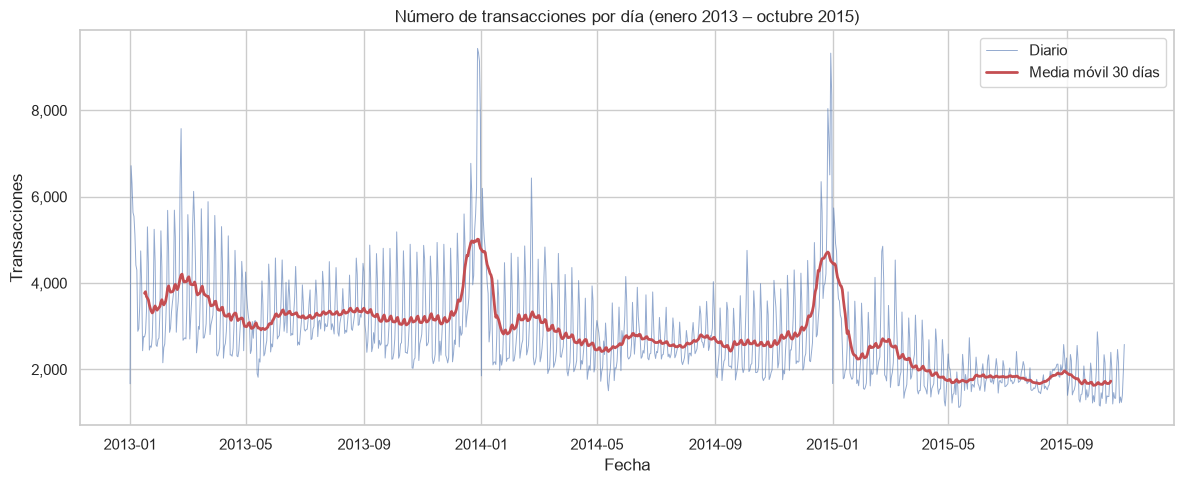

Métrica,Valor
Media diaria,"2,839"
Desviación estándar,"1,166"
Coeficiente de variación,41.1%
Mínimo,"1,123 (12/05/2015)"
Máximo,"9,434 (28/12/2013)"
Media diaria 2013,"3,473"
Media diaria 2014,"2,893"
Media diaria 2015,"2,015"
Día de la semana con más transacciones (media),"Sábado (3,989)"
Día de la semana con menos transacciones (media),"Lunes (2,293)"


In [13]:
daily_transactions = sales_train.groupby("date").size()
rolling_30 = daily_transactions.rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_transactions.index, daily_transactions, linewidth=0.7, alpha=0.6, label="Diario")
ax.plot(rolling_30.index, rolling_30, linewidth=2, color="C3", label="Media móvil 30 días")
ax.set_title("Número de transacciones por día (enero 2013 – octubre 2015)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Transacciones")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

DAY_NAMES = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
by_weekday = daily_transactions.groupby(daily_transactions.index.day_of_week).mean()
by_year = daily_transactions.groupby(daily_transactions.index.year).mean()

daily_summary = pd.DataFrame(
    {
        "Métrica": [
            "Media diaria",
            "Desviación estándar",
            "Coeficiente de variación",
            "Mínimo",
            "Máximo",
            *[f"Media diaria {year}" for year in by_year.index],
            "Día de la semana con más transacciones (media)",
            "Día de la semana con menos transacciones (media)",
        ],
        "Valor": [
            f"{daily_transactions.mean():,.0f}",
            f"{daily_transactions.std():,.0f}",
            f"{daily_transactions.std() / daily_transactions.mean():.1%}",
            f"{daily_transactions.min():,} ({daily_transactions.idxmin():%d/%m/%Y})",
            f"{daily_transactions.max():,} ({daily_transactions.idxmax():%d/%m/%Y})",
            *[f"{value:,.0f}" for value in by_year],
            f"{DAY_NAMES[by_weekday.idxmax()]} ({by_weekday.max():,.0f})",
            f"{DAY_NAMES[by_weekday.idxmin()]} ({by_weekday.min():,.0f})",
        ],
    }
)

style_table(daily_summary)

**Interpretación**

- La serie diaria es muy ruidosa: la media es de 2,839 transacciones por día con una desviación de 1,166
  (coeficiente de variación del 41.1 %), y va de 1,123 (12/05/2015) a 9,434 (28/12/2013).
- Hay un ciclo semanal marcado: el sábado promedia 3,989 transacciones frente a 2,293 del lunes. Es la
  oscilación de alta frecuencia que se ve en la línea diaria.
- Los picos más altos se concentran a finales de diciembre de cada año, lo que indica una fuerte
  estacionalidad anual por las compras de fin de año.
- La media móvil muestra una tendencia descendente: la media diaria baja de 3,473 en 2013 a 2,893 en 2014
  y a 2,015 en 2015.

#### Conclusión: frecuencia de agregación

Conviene trabajar con **frecuencia mensual** (`date_block_num`):

- **El objetivo es mensual.** `item_cnt_month` y `test.csv` se definen por mes y par tienda-producto, así
  que el modelo debe aprender y predecir a esa escala.
- **Reduce el ruido.** La serie diaria tiene un coeficiente de variación del 41.1 % y un ciclo semanal
  marcado. Al sumar por mes, ese ruido y el efecto del día de la semana se compensan.
- **Los meses son comparables.** Los 34 bloques están completos y `date_block_num` coincide con la fecha en
  todos los registros, así que la agregación mensual no introduce sesgos por días faltantes.
- **Conserva la señal útil.** La tendencia descendente y la estacionalidad de diciembre siguen siendo
  visibles a nivel mensual.

La frecuencia semanal no aporta ventajas: las semanas no encajan con los meses, que es la unidad del
pronóstico, y la serie seguiría siendo más ruidosa. La información diaria puede aprovecharse después como
variables derivadas (por ejemplo, número de días con ventas en el mes), pero el conjunto de modelado debe
construirse a nivel mensual.

## 4. Análisis de valores faltantes y duplicados

### 4.a Valores nulos

Número y porcentaje de valores nulos por columna en los cinco archivos.

In [14]:
null_report = pd.DataFrame(
    [
        {
            "Archivo": FILES[name],
            "Columna": col,
            "Nulos": int(df[col].isna().sum()),
            "% de nulos": df[col].isna().mean() * 100,
        }
        for name, df in datasets.items()
        for col in df.columns
    ]
)

style_table(null_report, {"% de nulos": "{:.2f}"})

Archivo,Columna,Nulos,% de nulos
sales_train.csv,date,0,0.00
sales_train.csv,date_block_num,0,0.00
sales_train.csv,shop_id,0,0.00
sales_train.csv,item_id,0,0.00
sales_train.csv,item_price,0,0.00
sales_train.csv,item_cnt_day,0,0.00
items.csv,item_name,0,0.00
items.csv,item_id,0,0.00
items.csv,item_category_id,0,0.00
item_categories.csv,item_category_name,0,0.00


**Interpretación**

- Ninguna de las 16 columnas de los cinco archivos tiene valores nulos, así que no se requiere imputación
  por ausencia de datos.
- Los problemas de calidad del dataset no son de valores faltantes, sino de valores inválidos y duplicados,
  que se analizan a continuación.

### 4.b Estrategia de tratamiento y valores inválidos

#### Precios menores o iguales a cero

Se identifican las ventas con `item_price` ≤ 0 y se calcula su precio de reemplazo: la mediana de los precios
válidos del mismo producto en la misma tienda y mes; si no existe, la del producto en el mes; y si tampoco
existe, el registro se elimina.

In [15]:
def impute_invalid_prices(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Imputa item_price <= 0 con la mediana de referencia; elimina los registros sin referencia."""
    df = df.copy()
    valid = df[df["item_price"] > 0]
    median_shop_month = valid.groupby(["item_id", "shop_id", "date_block_num"])["item_price"].median()
    median_month = valid.groupby(["item_id", "date_block_num"])["item_price"].median()

    log = []
    for idx, row in df[df["item_price"] <= 0].iterrows():
        key_shop = (row["item_id"], row["shop_id"], row["date_block_num"])
        key_month = (row["item_id"], row["date_block_num"])
        if key_shop in median_shop_month.index:
            new_price, reference = median_shop_month[key_shop], "producto-tienda-mes"
        elif key_month in median_month.index:
            new_price, reference = median_month[key_month], "producto-mes"
        else:
            new_price, reference = np.nan, "sin referencia (se elimina)"
        df.loc[idx, "item_price"] = new_price
        log.append({"Índice": idx, "date": row["date"].strftime("%d/%m/%Y"), "shop_id": row["shop_id"],
                    "item_id": row["item_id"], "date_block_num": row["date_block_num"],
                    "Precio original": row["item_price"], "Precio imputado": new_price,
                    "Referencia": reference})

    return df.dropna(subset=["item_price"]), pd.DataFrame(log)


invalid_prices = sales_train[sales_train["item_price"] <= 0]
print(f"Registros con item_price <= 0: {len(invalid_prices):,}")

_, price_log = impute_invalid_prices(sales_train)
display(style_table(price_log))

first_invalid = invalid_prices.iloc[0]
reference_sales = sales_train[
    (sales_train["item_id"] == first_invalid["item_id"])
    & (sales_train["shop_id"] == first_invalid["shop_id"])
    & (sales_train["date_block_num"] == first_invalid["date_block_num"])
].assign(date=lambda d: d["date"].dt.strftime("%d/%m/%Y"))
print("Ventas del mismo producto, tienda y mes:")
style_table(reference_sales)

Registros con item_price <= 0: 1


Índice,date,shop_id,item_id,date_block_num,Precio original,Precio imputado,Referencia
484683,15/05/2013,32,2973,4,-1.00,"1,874.00",producto-tienda-mes


Ventas del mismo producto, tienda y mes:


date,date_block_num,shop_id,item_id,item_price,item_cnt_day
23/05/2013,4,32,2973,"1,249.00",1
15/05/2013,4,32,2973,-1.00,1
06/05/2013,4,32,2973,"2,499.00",1


**Interpretación**

- Solo hay 1 registro con precio inválido: el producto 2973 en la tienda 32 el 15/05/2013, con
  `item_price` = −1 y una unidad vendida.
- En ese mismo mes y tienda el producto tiene otras dos ventas válidas, a 1,249.00 y 2,499.00, por lo que se
  imputa la mediana: 1,874.00.
- **Decisión:** imputar en lugar de eliminar. El −1 es un código de error en el precio, pero la cantidad
  vendida es válida, y eliminar la fila restaría una unidad a la variable objetivo. Con referencia en la
  misma tienda y mes, la mediana es un reemplazo realista y resistente a precios extremos.

#### Cantidades negativas (devoluciones)

Se cuantifican los registros con `item_cnt_day` < 0, su peso sobre los registros y las unidades, y las
categorías en las que se concentran.

In [16]:
returns = sales_train[sales_train["item_cnt_day"] < 0]
units_sold = sales_train.loc[sales_train["item_cnt_day"] > 0, "item_cnt_day"].sum()
units_returned = -returns["item_cnt_day"].sum()

returns_summary = pd.DataFrame(
    {
        "Métrica": [
            "Registros con devolución",
            "% de los registros",
            "Unidades devueltas",
            "% de las unidades vendidas",
            "Unidades netas (vendidas − devueltas)",
        ],
        "Valor": [
            f"{len(returns):,}",
            f"{len(returns) / len(sales_train):.2%}",
            f"{units_returned:,}",
            f"{units_returned / units_sold:.2%}",
            f"{units_sold - units_returned:,}",
        ],
    }
)
display(style_table(returns_summary))

sales_with_category = sales_train.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
returns_by_category = (
    sales_with_category.assign(is_return=sales_with_category["item_cnt_day"] < 0)
    .groupby("item_category_id")
    .agg(records=("is_return", "size"), return_records=("is_return", "sum"))
    .reset_index()
    .merge(item_categories, on="item_category_id")
    .sort_values("return_records", ascending=False)
)
returns_by_category["% de las devoluciones"] = (
    returns_by_category["return_records"] / returns_by_category["return_records"].sum() * 100
)
returns_by_category["% acumulado"] = returns_by_category["% de las devoluciones"].cumsum()
returns_by_category["Tasa de devolución (%)"] = (
    returns_by_category["return_records"] / returns_by_category["records"] * 100
)
top_return_categories = returns_by_category.head(10).rename(
    columns={"item_category_name": "Categoría", "return_records": "Devoluciones",
             "records": "Registros de la categoría"}
)[["item_category_id", "Categoría", "Devoluciones", "% de las devoluciones", "% acumulado",
   "Registros de la categoría", "Tasa de devolución (%)"]]

print(f"Categorías con al menos una devolución: {(returns_by_category['return_records'] > 0).sum()} "
      f"de {len(item_categories)}")
style_table(
    top_return_categories,
    {"% de las devoluciones": "{:.1f}", "% acumulado": "{:.1f}", "Tasa de devolución (%)": "{:.2f}"},
)

Métrica,Valor
Registros con devolución,"7,356"
% de los registros,0.25%
Unidades devueltas,"7,541"
% de las unidades vendidas,0.21%
Unidades netas (vendidas − devueltas),"3,648,206"


Categorías con al menos una devolución: 60 de 84


item_category_id,Categoría,Devoluciones,% de las devoluciones,% acumulado,Registros de la categoría,Tasa de devolución (%)
19,Игры - PS3,847,11.5,11.5,"208,219",0.41
30,Игры PC - Стандартные издания,804,10.9,22.4,"351,591",0.23
37,Кино - Blu-Ray,742,10.1,32.5,"192,674",0.39
40,Кино - DVD,714,9.7,42.2,"564,652",0.13
23,Игры - XBOX 360,622,8.5,50.7,"146,789",0.42
55,Музыка - CD локального производства,458,6.2,56.9,"339,585",0.13
20,Игры - PS4,421,5.7,62.6,"79,058",0.53
28,Игры PC - Дополнительные издания,268,3.6,66.3,"121,539",0.22
38,Кино - Blu-Ray 3D,223,3.0,69.3,"42,718",0.52
21,Игры - PSP,189,2.6,71.9,"32,164",0.59


**Interpretación**

- Hay 7,356 registros con devolución (0.25 % de los registros), que suman 7,541 unidades devueltas: el
  0.21 % de las unidades vendidas. Las ventas netas son 3,648,206 unidades.
- Las devoluciones aparecen en 60 de las 84 categorías, pero se concentran: las 10 primeras reúnen el
  71.9 %. Dominan los videojuegos (PS3, PC, XBOX 360, PS4, PSP: 42.8 % entre las seis categorías de juegos
  del top 10) y el cine en formato físico (Blu-Ray, DVD y Blu-Ray 3D: 22.8 %).
- La tasa de devolución por categoría es baja en todas (entre 0.13 % y 0.59 % de sus registros); las más
  altas corresponden a consolas de nicho o recientes, como PSP (0.59 %) y PS4 (0.53 %).
- **Decisión:** conservar las devoluciones como ventas netas. `item_cnt_month` se define como la suma de
  `item_cnt_day`, incluidas las devoluciones, así que eliminarlas sobrestimaría el objetivo. Su peso es
  además pequeño (0.21 % de las unidades).

#### Resumen de la estrategia de tratamiento

Decisiones adoptadas para los problemas de valores faltantes e inválidos.

In [17]:
strategy = pd.DataFrame(
    [
        ("Valores nulos", int(null_report["Nulos"].sum()), "Sin tratamiento",
         "Ninguna columna de los cinco archivos tiene nulos."),
        ("item_price ≤ 0", len(invalid_prices), "Imputar con la mediana de referencia",
         "La venta es válida y solo falla el precio; hay referencia del mismo producto, tienda y mes."),
        ("item_cnt_day < 0 (devoluciones)", len(returns), "Conservar como ventas netas",
         "El objetivo item_cnt_month es la suma neta de item_cnt_day; eliminarlas lo sobrestimaría."),
    ],
    columns=["Problema", "Registros afectados", "Decisión", "Justificación"],
)

style_table(strategy)

Problema,Registros afectados,Decisión,Justificación
Valores nulos,0,Sin tratamiento,Ninguna columna de los cinco archivos tiene nulos.
item_price ≤ 0,1,Imputar con la mediana de referencia,"La venta es válida y solo falla el precio; hay referencia del mismo producto, tienda y mes."
item_cnt_day < 0 (devoluciones),"7,356",Conservar como ventas netas,El objetivo item_cnt_month es la suma neta de item_cnt_day; eliminarlas lo sobrestimaría.


### 4.c Duplicados

#### Registros duplicados exactos en `sales_train`

Se buscan filas idénticas en todas sus columnas (fecha, mes, tienda, producto, precio y cantidad).

In [18]:
exact_duplicates = sales_train[sales_train.duplicated(keep=False)].sort_values(
    ["date", "shop_id", "item_id"]
)
print(f"Filas sobrantes por duplicado exacto: {sales_train.duplicated().sum():,} "
      f"({len(exact_duplicates):,} filas implicadas)")

style_table(exact_duplicates.reset_index(names="Índice").assign(
    date=lambda d: d["date"].dt.strftime("%d/%m/%Y")
))

Filas sobrantes por duplicado exacto: 6 (12 filas implicadas)


Índice,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,05/01/2013,0,54,20130,149.00,1
76962,05/01/2013,0,54,20130,149.00,1
1435365,23/02/2014,13,50,3423,999.00,1
1435367,23/02/2014,13,50,3423,999.00,1
1496765,23/03/2014,14,21,3423,999.00,1
1496766,23/03/2014,14,21,3423,999.00,1
1671872,01/05/2014,16,50,3423,999.00,1
1671873,01/05/2014,16,50,3423,999.00,1
1866322,12/07/2014,18,25,3423,999.00,1
1866340,12/07/2014,18,25,3423,999.00,1


**Interpretación**

- Hay 6 filas duplicadas exactas (12 filas implicadas, en pares). Todas son ventas de una unidad, y 4 de los
  6 pares corresponden al mismo producto (3423) a 999.00 en distintas tiendas y fechas.
- **Decisión:** eliminar los duplicados y conservar la primera aparición. `sales_train` registra las ventas
  diarias agregadas por tienda, producto y precio, así que dos filas idénticas apuntan a un error de carga
  y no a dos ventas distintas. El impacto es mínimo: 6 unidades sobre más de 3.6 millones.

#### Tiendas duplicadas en `shops.csv`

Se normalizan los nombres de las tiendas quitando los marcadores "!", "?", "²" y "фран" (franquicia) para
detectar IDs distintos con el mismo nombre. Para cada par se revisan los meses con ventas y su presencia en
`test.csv`.

In [19]:
def month_ranges(blocks) -> str:
    """Convierte una lista de date_block_num en rangos compactos, p. ej. '0-24, 26-33'."""
    blocks = sorted(set(int(b) for b in blocks))
    groups = [[blocks[0]]]
    for block in blocks[1:]:
        if block == groups[-1][-1] + 1:
            groups[-1].append(block)
        else:
            groups.append([block])
    return ", ".join(f"{g[0]}-{g[-1]}" if len(g) > 1 else f"{g[0]}" for g in groups)


shops_norm = shops.assign(
    normalized_name=shops["shop_name"]
    .str.replace(r"[!?²]", "", regex=True)
    .str.replace("фран", "")
    .str.strip()
    .str.lower()
)
duplicate_groups = shops_norm.groupby("normalized_name")["shop_id"].apply(list)
duplicate_groups = duplicate_groups[duplicate_groups.str.len() > 1]

test_shops = set(test["shop_id"])
pair_rows, SHOP_ID_MAP = [], {}
for pair_number, shop_ids in enumerate(duplicate_groups, start=1):
    for shop_id in shop_ids:
        shop_sales = sales_train.loc[sales_train["shop_id"] == shop_id, "date_block_num"]
        pair_rows.append({
            "Par": pair_number,
            "shop_id": shop_id,
            "Nombre": shops.loc[shops["shop_id"] == shop_id, "shop_name"].iloc[0],
            "Meses con ventas (date_block_num)": month_ranges(shop_sales.unique()),
            "N.º de meses": shop_sales.nunique(),
            "Registros": len(shop_sales),
            "En test.csv": "Sí" if shop_id in test_shops else "No",
        })
    kept = [s for s in shop_ids if s in test_shops]
    keep_id = kept[0] if len(kept) == 1 else max(shop_ids, key=lambda s: (sales_train["shop_id"] == s).sum())
    SHOP_ID_MAP.update({s: keep_id for s in shop_ids if s != keep_id})

display(style_table(pd.DataFrame(pair_rows)))

shop_mapping = pd.DataFrame(
    {"ID original": list(SHOP_ID_MAP.keys()), "ID unificado": list(SHOP_ID_MAP.values())}
)
print("Mapeo de unificación:")
style_table(shop_mapping)

Par,shop_id,Nombre,Meses con ventas (date_block_num),N.º de meses,Registros,En test.csv
1,10,Жуковский ул. Чкалова 39м?,"0-24, 26-33",33,"21,397",Sí
1,11,Жуковский ул. Чкалова 39м²,25,1,499,No
2,0,"!Якутск Орджоникидзе, 56 фран",0-1,2,"9,857",No
2,57,"Якутск Орджоникидзе, 56",2-33,32,"117,428",Sí
3,1,"!Якутск ТЦ ""Центральный"" фран",0-1,2,"5,678",No
3,58,"Якутск ТЦ ""Центральный""",2-33,32,"71,441",Sí


Mapeo de unificación:


ID original,ID unificado
11,10
0,57
1,58


**Interpretación**

- Se detectan 3 pares de tiendas con el mismo nombre: 0/57 y 1/58 (Yakutsk, que difieren por "!" y
  "фран") y 10/11 (Zhukovsky, que difieren por "?" y "²").
- Los IDs de cada par se complementan en el tiempo en lugar de solaparse: las tiendas 0 y 1 venden solo en
  los meses 0-1, y 57 y 58 desde el mes 2. La tienda 11 vende solo en el mes 25, justo el único mes que le
  falta a la 10. Es la misma tienda registrada con dos IDs.
- En cada par solo un ID aparece en `test.csv` (10, 57 y 58), así que se conserva ese ID y se reasignan a él
  las ventas de 0, 1 y 11 (16,034 registros). Así el historial de cada tienda queda continuo y conectado con
  los pares a pronosticar.

#### Copia limpia de `sales_train`

Se aplican las decisiones sobre una copia (`sales_clean`), sin modificar `sales_train` ni los archivos de
`data/raw`, y se guarda en `data/interim` en formato Parquet, que conserva los tipos optimizados.

In [20]:
records_raw = len(sales_train)

sales_clean, _ = impute_invalid_prices(sales_train)
records_after_prices = len(sales_clean)

sales_clean = sales_clean.drop_duplicates(keep="first")
records_after_duplicates = len(sales_clean)

sales_clean["shop_id"] = sales_clean["shop_id"].replace(SHOP_ID_MAP).astype("int8")
sales_clean = sales_clean.reset_index(drop=True)

clean_path = INTERIM_PATH / CLEAN_SALES_FILE
sales_clean.to_parquet(clean_path, index=False)
reloaded = pd.read_parquet(clean_path)

cleaning_steps = pd.DataFrame(
    {
        "Paso": [
            "sales_train original",
            "Imputación de precios ≤ 0",
            "Eliminación de duplicados exactos",
            "Unificación de tiendas duplicadas",
        ],
        "Registros": [records_raw, records_after_prices, records_after_duplicates, len(sales_clean)],
    }
)
cleaning_steps["Eliminados en el paso"] = (
    -cleaning_steps["Registros"].diff().fillna(0).astype(int)
)

checks = pd.DataFrame(
    {
        "Verificación": [
            "Precios ≤ 0 restantes",
            "Duplicados exactos restantes",
            "Tiendas distintas en sales_clean",
            "IDs reasignados presentes (0, 1, 11)",
            "Archivo guardado",
            "Filas y tipos al releer el Parquet",
        ],
        "Resultado": [
            f"{(sales_clean['item_price'] <= 0).sum():,}",
            f"{sales_clean.duplicated().sum():,}",
            f"{sales_clean['shop_id'].nunique()}",
            f"{sales_clean['shop_id'].isin(list(SHOP_ID_MAP)).sum():,}",
            clean_path.as_posix(),
            "Coinciden" if reloaded.shape == sales_clean.shape
            and reloaded.dtypes.equals(sales_clean.dtypes) else "No coinciden",
        ],
    }
)

display(style_table(cleaning_steps))
style_table(checks)

Paso,Registros,Eliminados en el paso
sales_train original,"2,935,849",0
Imputación de precios ≤ 0,"2,935,849",0
Eliminación de duplicados exactos,"2,935,843",6
Unificación de tiendas duplicadas,"2,935,843",0


Verificación,Resultado
Precios ≤ 0 restantes,0
Duplicados exactos restantes,0
Tiendas distintas en sales_clean,57
"IDs reasignados presentes (0, 1, 11)",0
Archivo guardado,../data/interim/sales_train_clean.parquet
Filas y tipos al releer el Parquet,Coinciden


**Interpretación**

- `sales_train` pasa de 2,935,849 a 2,935,843 registros: solo se eliminan los 6 duplicados exactos. La
  imputación del precio y la unificación de tiendas modifican valores pero no eliminan filas.
- Tras la limpieza no quedan precios ≤ 0 ni duplicados exactos, y las ventas se reparten en 57 tiendas en
  lugar de 60, porque los IDs 0, 1 y 11 ya no aparecen.
- `sales_clean` se guarda en `data/interim/sales_train_clean.parquet` y al releerlo conserva filas y tipos.
  Las secciones siguientes parten de este archivo. Los archivos de `data/raw` no se modificaron.

## 5. Análisis descriptivo general

#### Preparación de los datos

Se parte de la copia limpia (`sales_train_clean.parquet`), se calculan los ingresos de cada registro y se
añaden los atributos de producto, categoría y tienda.

In [21]:
sales = load_parquet(CLEAN_SALES_FILE)
sales["revenue"] = sales["item_price"] * sales["item_cnt_day"]

sales = (
    sales.merge(items, on="item_id", how="left")
    .merge(item_categories, on="item_category_id", how="left")
    .merge(shops, on="shop_id", how="left")
)

print(f"Registros: {len(sales):,}")
print("Nulos tras unir los catálogos:",
      sales[["item_name", "item_category_name", "shop_name"]].isna().sum().sum())

Registros: 2,935,843
Nulos tras unir los catálogos: 0


#### Categoría principal

Se toma el texto anterior a " - " en `item_category_name` y se traduce al español. Los prefijos de
videojuegos (`Игры`, `Игры PC`, `Игры Android`, `Игры MAC`) se agrupan en *Videojuegos*, y los auriculares
de PC (`PC`) en *Accesorios*. Los prefijos de servicio o residuales, que no llegan al 1 % de las unidades ni
del revenue (envíos, entradas, pilas, medios vírgenes y categorías de servicio), se agrupan en *Otros*.

In [22]:
CATEGORY_TRANSLATION = {
    "Игры": "Videojuegos",
    "Игры PC": "Videojuegos",
    "Игры Android": "Videojuegos",
    "Игры MAC": "Videojuegos",
    "Кино": "Cine",
    "Музыка": "Música",
    "Книги": "Libros",
    "Подарки": "Regalos",
    "Программы": "Software",
    "Аксессуары": "Accesorios",
    "PC": "Accesorios",
    "Игровые консоли": "Consolas",
    "Карты оплаты": "Tarjetas de pago",
    "Карты оплаты (Кино, Музыка, Игры)": "Tarjetas de pago",
}

sales["category_prefix"] = sales["item_category_name"].str.split(" - ").str[0].str.strip()
sales["categoria_principal"] = sales["category_prefix"].map(CATEGORY_TRANSLATION).fillna("Otros")

category_equivalence = (
    sales.groupby(["category_prefix", "categoria_principal"])
    .agg(subcategories=("item_category_id", "nunique"), units=("item_cnt_day", "sum"),
         revenue=("revenue", "sum"))
    .reset_index()
)
category_equivalence["% unidades"] = category_equivalence["units"] / sales["item_cnt_day"].sum() * 100
category_equivalence["% revenue"] = category_equivalence["revenue"] / sales["revenue"].sum() * 100
category_equivalence = category_equivalence.sort_values(["categoria_principal", "units"],
                                                        ascending=[True, False])

style_table(
    category_equivalence.rename(columns={"category_prefix": "Prefijo original",
                                         "subcategories": "Subcategorías"})
    [["Prefijo original", "categoria_principal", "Subcategorías", "% unidades", "% revenue"]],
    {"% unidades": "{:.2f}", "% revenue": "{:.2f}"},
)

Prefijo original,categoria_principal,Subcategorías,% unidades,% revenue
Аксессуары,Accesorios,7,2.33,4.90
PC,Accesorios,1,0.00,0.00
Кино,Cine,5,25.13,9.86
Игровые консоли,Consolas,8,0.88,15.54
Книги,Libros,13,2.09,0.89
Музыка,Música,6,11.27,4.40
Служебные,Otros,2,0.60,0.75
Доставка товара,Otros,1,0.50,0.19
Билеты (Цифра),Otros,1,0.38,0.57
Элементы питания,Otros,1,0.33,0.03


#### Ciudad y tipo de tienda

La ciudad se obtiene de la primera palabra de `shop_name` (sin "!") y se translitera al alfabeto latino.
Las tiendas que no son físicas —tienda online (Интернет-магазин), almacén digital (Цифровой склад) y venta
itinerante (Выездная Торговля)— se marcan con el tipo *Online/Otros*.

In [23]:
CITY_TRANSLITERATION = {
    "Адыгея": "Adygeya", "Балашиха": "Balashikha", "Волжский": "Volzhsky", "Вологда": "Vologda",
    "Воронеж": "Voronezh", "Жуковский": "Zhukovsky", "Казань": "Kazan", "Калуга": "Kaluga",
    "Коломна": "Kolomna", "Красноярск": "Krasnoyarsk", "Курск": "Kursk", "Москва": "Moskva",
    "Мытищи": "Mytishchi", "Н.Новгород": "Nizhny Novgorod", "Новосибирск": "Novosibirsk",
    "Омск": "Omsk", "РостовНаДону": "Rostov-na-Donu", "СПб": "Sankt-Peterburg", "Самара": "Samara",
    "Сергиев": "Sergiyev Posad", "Сургут": "Surgut", "Томск": "Tomsk", "Тюмень": "Tyumen",
    "Уфа": "Ufa", "Химки": "Khimki", "Чехов": "Chekhov", "Якутск": "Yakutsk",
    "Ярославль": "Yaroslavl",
}
NON_PHYSICAL_SHOPS = {"Интернет-магазин", "Цифровой", "Выездная"}

shops_geo = shops.assign(first_word=shops["shop_name"].str.replace("!", "").str.split().str[0])
is_non_physical = shops_geo["first_word"].isin(NON_PHYSICAL_SHOPS)
shops_geo["tipo_tienda"] = np.where(is_non_physical, "Online/Otros", "Física")
shops_geo["ciudad"] = np.where(is_non_physical, "Online/Otros",
                               shops_geo["first_word"].map(CITY_TRANSLITERATION))
if shops_geo["ciudad"].isna().any():
    raise ValueError("Hay tiendas sin transliteración de ciudad")

sales = sales.merge(shops_geo[["shop_id", "ciudad", "tipo_tienda"]], on="shop_id", how="left")

city_equivalence = (
    shops_geo[shops_geo["shop_id"].isin(sales["shop_id"].unique())]
    .groupby(["first_word", "ciudad", "tipo_tienda"])
    .agg(n_shops=("shop_id", "size"), shop_ids=("shop_id", lambda s: ", ".join(map(str, s))))
    .reset_index()
    .sort_values(["tipo_tienda", "ciudad"])
    .rename(columns={"first_word": "Primera palabra", "n_shops": "Tiendas", "shop_ids": "IDs"})
)

style_table(city_equivalence)

Primera palabra,ciudad,tipo_tienda,Tiendas,IDs
Адыгея,Adygeya,Física,1,2
Балашиха,Balashikha,Física,1,3
Чехов,Chekhov,Física,1,56
Калуга,Kaluga,Física,1,15
Казань,Kazan,Física,2,"13, 14"
Химки,Khimki,Física,1,54
Коломна,Kolomna,Física,1,16
Красноярск,Krasnoyarsk,Física,2,"17, 18"
Курск,Kursk,Física,1,19
Москва,Moskva,Física,13,"20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32"


### 5.a Métricas estadísticas

Estadísticos descriptivos del precio, las unidades diarias y los ingresos por registro, junto con su
coeficiente de asimetría.

In [24]:
METRIC_VARS = {"item_price": "item_price (RUB)", "item_cnt_day": "item_cnt_day (unidades)",
               "revenue": "revenue (RUB)"}

descriptive_stats = pd.DataFrame(
    [
        {
            "Variable": label,
            "Media": sales[col].mean(),
            "Mediana": sales[col].median(),
            "Mínimo": sales[col].min(),
            "P25": sales[col].quantile(0.25),
            "P75": sales[col].quantile(0.75),
            "P99": sales[col].quantile(0.99),
            "Máximo": sales[col].max(),
            "Desv. estándar": sales[col].std(),
            "Asimetría": sales[col].skew(),
        }
        for col, label in METRIC_VARS.items()
    ]
)

style_table(descriptive_stats, {c: "{:,.2f}" for c in descriptive_stats.columns[1:]})

Variable,Media,Mediana,Mínimo,P25,P75,P99,Máximo,Desv. estándar,Asimetría
item_price (RUB),890.85,399.00,0.07,249.00,999.00,"5,999.00","307,980.00","1,729.80",10.75
item_cnt_day (unidades),1.24,1.00,-22.00,1.00,1.00,5.00,"2,169.00",2.62,272.83
revenue (RUB),"1,157.73",449.00,"-68,970.00",249.00,"1,078.20","11,375.00","1,829,990.00","5,683.61",103.56


**Interpretación**


- Las tres variables tienen una fuerte **asimetría positiva**: la media supera claramente a la mediana
  (precio: 890.85 frente a 399.00 RUB; revenue: 1,157.73 frente a 449.00 RUB) y los coeficientes de
  asimetría son muy altos (10.75 en precio, 103.56 en revenue y 272.83 en unidades).
- `item_cnt_day` está casi siempre en 1: la mediana, el P25 y el P75 valen 1 y el P99 solo llega a 5. Aun
  así, el máximo es de 2,169 unidades en un día, un valor extremo muy alejado del resto.
- El precio va de 0.07 a 307,980 RUB. El P99 es de 5,999 RUB, así que el máximo es unas 50 veces mayor que
  el percentil 99. El revenue alcanza 1,829,990 RUB en un registro y tiene un mínimo de −68,970 RUB por
  devoluciones de productos caros.
- Estos extremos (precios muy bajos o muy altos y ventas diarias masivas) deben revisarse como posibles
  outliers antes de modelar, porque las medias y las desviaciones estándar están muy influidas por ellos.

### 5.b Distribución de las ventas

#### 5.b.i Por producto y categoría

**Concentración de ventas.** Se ordenan los productos por unidades netas vendidas y se calcula qué
porcentaje de ellos acumula el 80 % de las unidades (curva de Pareto).

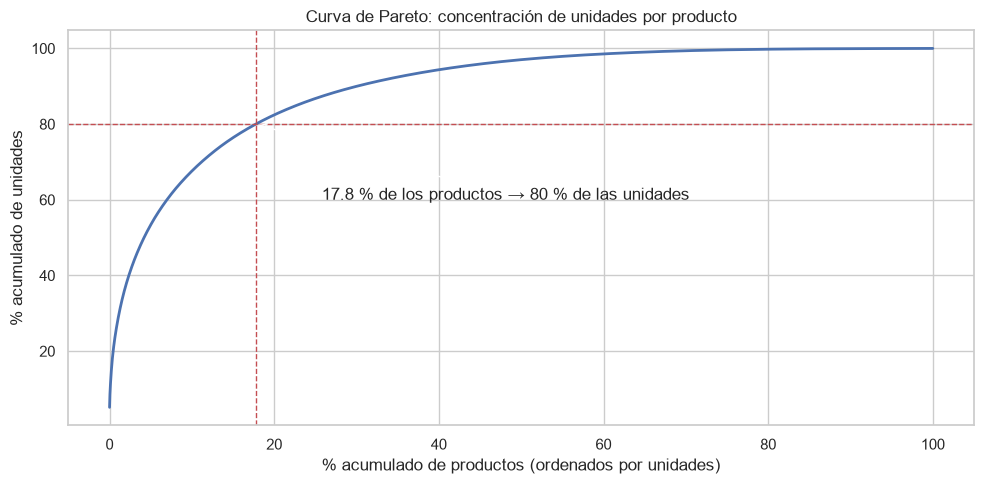

Métrica,Valor
Productos con ventas,"21,807"
Productos que generan el 80 % de las unidades,"3,877"
% de productos que generan el 80 % de las unidades,17.8 %
% de unidades del 1 % de productos más vendidos,28.1 %


item_id,Producto,categoria_principal,Unidades,% de las unidades
20949,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,Regalos,"187,642",5.14
2808,"Diablo III [PC, Jewel, русская версия]",Videojuegos,"17,245",0.47
3732,"Grand Theft Auto V [PS3, русские субтитры]",Videojuegos,"16,642",0.46
17717,Прием денежных средств для 1С-Онлайн,Otros,"15,830",0.43
5822,Playstation Store пополнение бумажника: Карта оплаты 1000 руб.,Tarjetas de pago,"14,515",0.40


In [25]:
units_by_item = sales.groupby("item_id")["item_cnt_day"].sum().sort_values(ascending=False)
cumulative_share = units_by_item.cumsum() / units_by_item.sum() * 100
items_for_80 = int((cumulative_share < 80).sum()) + 1
pct_items_for_80 = items_for_80 / len(units_by_item) * 100
pct_items_axis = np.arange(1, len(units_by_item) + 1) / len(units_by_item) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pct_items_axis, cumulative_share.values, linewidth=2)
ax.axhline(80, color="C3", linestyle="--", linewidth=1)
ax.axvline(pct_items_for_80, color="C3", linestyle="--", linewidth=1)
ax.annotate(f"{pct_items_for_80:.1f} % de los productos → 80 % de las unidades",
            xy=(pct_items_for_80, 80), xytext=(pct_items_for_80 + 8, 60),
            arrowprops={"arrowstyle": "->"})
ax.set_title("Curva de Pareto: concentración de unidades por producto")
ax.set_xlabel("% acumulado de productos (ordenados por unidades)")
ax.set_ylabel("% acumulado de unidades")
plt.tight_layout()
plt.show()

top_items = (
    units_by_item.head(5).rename("Unidades").reset_index()
    .merge(items[["item_id", "item_name", "item_category_id"]], on="item_id")
    .merge(sales[["item_id", "categoria_principal"]].drop_duplicates(), on="item_id")
)
top_items["% de las unidades"] = top_items["Unidades"] / units_by_item.sum() * 100

pareto_summary = pd.DataFrame(
    {
        "Métrica": ["Productos con ventas", "Productos que generan el 80 % de las unidades",
                    "% de productos que generan el 80 % de las unidades",
                    "% de unidades del 1 % de productos más vendidos"],
        "Valor": [f"{len(units_by_item):,}", f"{items_for_80:,}", f"{pct_items_for_80:.1f} %",
                  f"{cumulative_share.iloc[int(len(units_by_item) * 0.01) - 1]:.1f} %"],
    }
)
display(style_table(pareto_summary))
style_table(
    top_items.rename(columns={"item_name": "Producto"})
    [["item_id", "Producto", "categoria_principal", "Unidades", "% de las unidades"]],
    {"% de las unidades": "{:.2f}"},
)

**Interpretación**


- Las ventas están muy concentradas: el **17.8 % de los productos (3,877 de 21,807) genera el 80 % de las
  unidades**, y el 1 % más vendido acumula el 28.1 %.
- El producto más vendido no es un artículo de catálogo, sino la bolsa de la tienda (item 20949, "Фирменный
  пакет майка 1С Интерес"), con 187,642 unidades: el 5.14 % de todas las unidades. También aparece en el
  top 5 un concepto de cobro (item 17717, recepción de pagos de 1C-Online).
- Esos artículos no reflejan demanda de producto y distorsionan los totales de unidades. Conviene tenerlos
  identificados en el modelado.

**Unidades por producto en escala logarítmica.** Histograma del total de unidades netas por producto (solo
productos con unidades netas positivas), con contenedores logarítmicos.

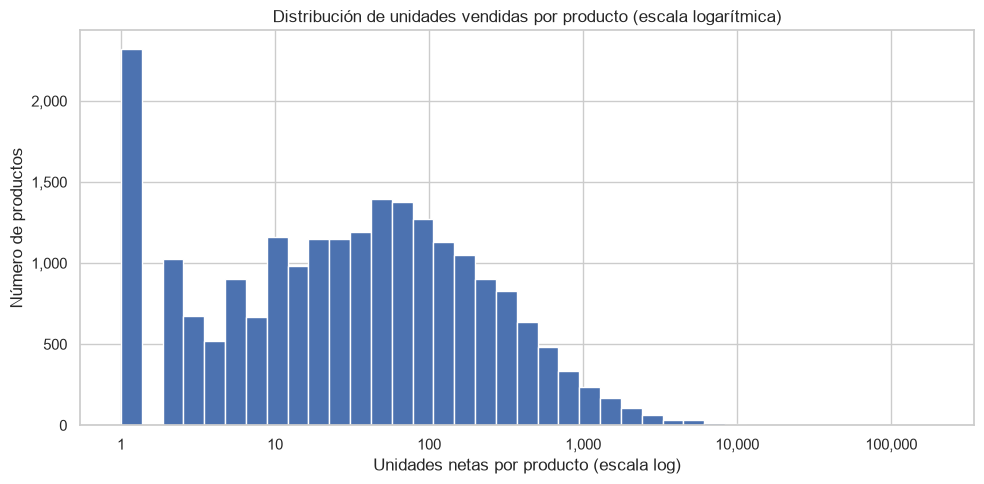

Métrica,Valor
Productos con unidades netas > 0,"21,799"
Productos con unidades netas ≤ 0,8
Mediana de unidades por producto,33
Media de unidades por producto,167.4
Productos con 10 unidades o menos,"6,701 (30.7%)"
"Productos con más de 1,000 unidades",607 (2.8%)


In [26]:
positive_units = units_by_item[units_by_item > 0]
log_bins = np.logspace(0, np.log10(positive_units.max()), 40)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(positive_units, bins=log_bins, edgecolor="white")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Distribución de unidades vendidas por producto (escala logarítmica)")
ax.set_xlabel("Unidades netas por producto (escala log)")
ax.set_ylabel("Número de productos")
plt.tight_layout()
plt.show()

units_distribution = pd.DataFrame(
    {
        "Métrica": ["Productos con unidades netas > 0", "Productos con unidades netas ≤ 0",
                    "Mediana de unidades por producto", "Media de unidades por producto",
                    "Productos con 10 unidades o menos", "Productos con más de 1,000 unidades"],
        "Valor": [f"{len(positive_units):,}", f"{(units_by_item <= 0).sum():,}",
                  f"{positive_units.median():,.0f}", f"{positive_units.mean():,.1f}",
                  f"{(positive_units <= 10).sum():,} ({(positive_units <= 10).mean():.1%})",
                  f"{(positive_units > 1000).sum():,} ({(positive_units > 1000).mean():.1%})"],
    }
)
style_table(units_distribution)

**Interpretación**


- La distribución es de **cola larga**: la mediana es de 33 unidades por producto, pero la media sube a
  167.4 por los productos muy vendidos.
- El 30.7 % de los productos (6,701) vende 10 unidades o menos en todo el periodo, y más de 2,000 productos
  venden una sola unidad (la barra de la izquierda). Solo el 2.8 % (607) supera las 1,000 unidades.
- En escala logarítmica, el grueso de los productos se sitúa entre 10 y 1,000 unidades. Hay 8 productos
  con unidades netas ≤ 0, en los que las devoluciones igualan o superan las ventas.
- Para el pronóstico, esto implica que la mayoría de los pares tienda-producto tendrán ventas mensuales
  muy bajas o nulas.

**Participación por categoría principal.** Porcentaje de las unidades y del revenue que aporta cada
categoría principal, junto con su precio medio por unidad.

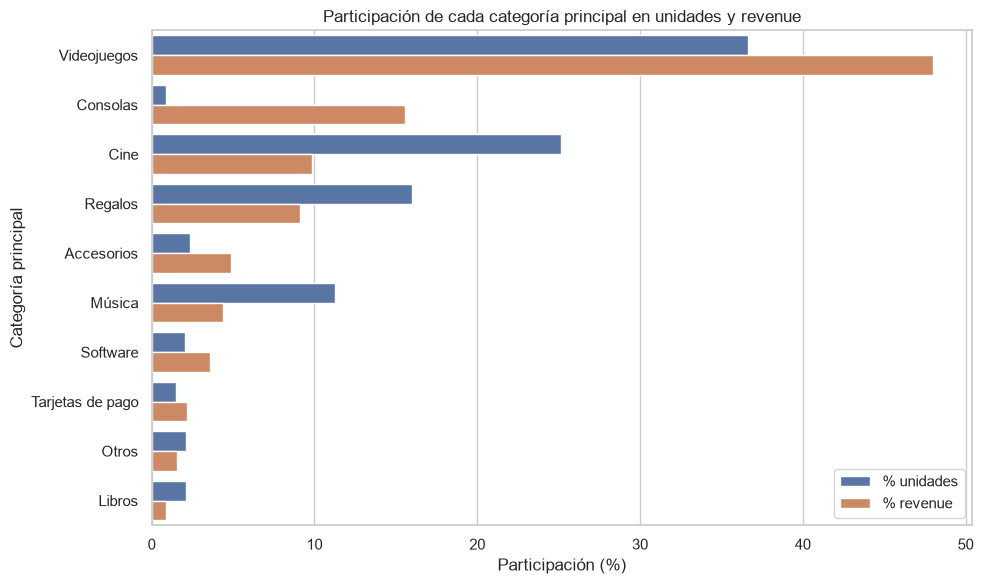

categoria_principal,Unidades,Revenue (M RUB),% unidades,% revenue,Precio medio (RUB)
Videojuegos,"1,335,990","1,631.8",36.6,48.0,"1,221"
Consolas,"32,155",528.0,0.9,15.5,"16,421"
Cine,"916,941",335.0,25.1,9.9,365
Regalos,"584,366",309.1,16.0,9.1,529
Accesorios,"85,059",166.4,2.3,4.9,"1,956"
Música,"411,294",149.7,11.3,4.4,364
Software,"74,954",122.4,2.1,3.6,"1,633"
Tarjetas de pago,"53,883",73.0,1.5,2.1,"1,354"
Otros,"77,217",53.1,2.1,1.6,688
Libros,"76,341",30.3,2.1,0.9,398


In [27]:
category_share = (
    sales.groupby("categoria_principal")
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
    .reset_index()
)
category_share["% unidades"] = category_share["units"] / category_share["units"].sum() * 100
category_share["% revenue"] = category_share["revenue"] / category_share["revenue"].sum() * 100
category_share["Precio medio (RUB)"] = category_share["revenue"] / category_share["units"]
category_share = category_share.sort_values("% revenue", ascending=False)

plot_data = category_share.melt(id_vars="categoria_principal", value_vars=["% unidades", "% revenue"],
                                var_name="Métrica", value_name="Participación (%)")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_data, y="categoria_principal", x="Participación (%)", hue="Métrica", ax=ax)
ax.set_title("Participación de cada categoría principal en unidades y revenue")
ax.set_xlabel("Participación (%)")
ax.set_ylabel("Categoría principal")
ax.legend(title=None)
plt.tight_layout()
plt.show()

style_table(
    category_share.assign(revenue=category_share["revenue"] / 1e6).rename(
        columns={"units": "Unidades", "revenue": "Revenue (M RUB)"}),
    {"Revenue (M RUB)": "{:,.1f}", "% unidades": "{:.1f}", "% revenue": "{:.1f}",
     "Precio medio (RUB)": "{:,.0f}"},
)

**Interpretación**


- **Videojuegos** domina en ambas métricas: 36.6 % de las unidades y 48.0 % del revenue.
- **Consolas** es el caso más desigual: solo el 0.9 % de las unidades, pero el 15.5 % del revenue, por su
  precio medio de 16,421 RUB.
- **Cine** (25.1 % de las unidades), **Regalos** (16.0 %) y **Música** (11.3 %) venden mucho volumen a
  precios bajos (365, 529 y 364 RUB de media), así que pesan bastante menos en revenue (9.9 %, 9.1 % y
  4.4 %).
- Las demás categorías aportan menos del 5 % cada una. *Otros* (envíos, pagos, entradas, pilas) suma el
  2.1 % de las unidades y el 1.6 % del revenue.
- La categoría principal es una variable relevante: el volumen y el precio cambian mucho entre categorías.

#### 5.b.ii Por sucursal

**Distribución por tienda.** Unidades y revenue totales del periodo por tienda. Los totales dependen
también de cuántos meses estuvo activa cada tienda.

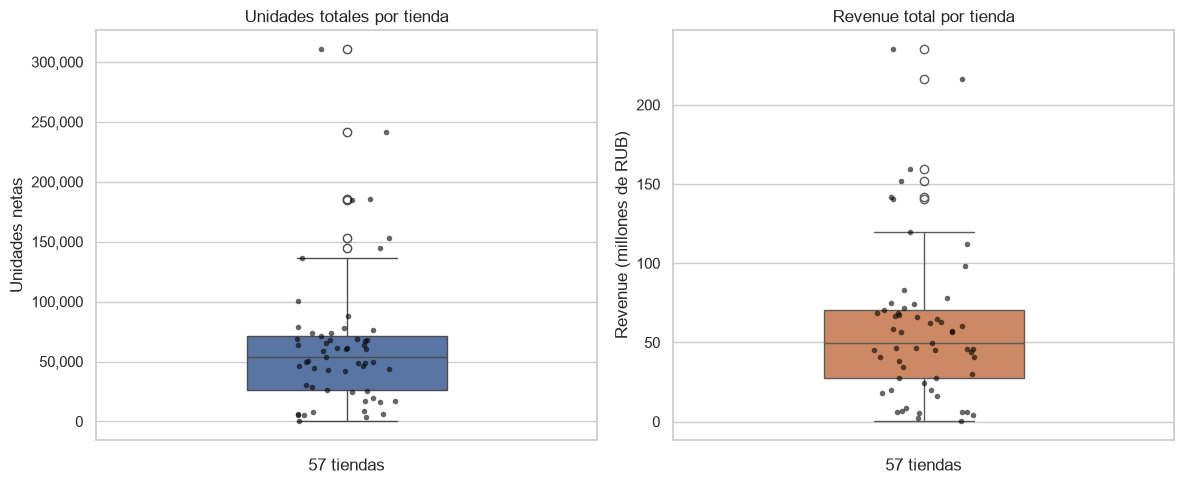

Métrica,Unidades,Revenue (M RUB)
Media,"64,003.5",59.6
Mediana,"53,886.0",49.8
Mínimo,330.0,0.4
Máximo,"310,777.0",235.2
Máximo / mediana,5.8,4.7


shop_id,Tienda,ciudad,Unidades,Revenue (M RUB),% revenue,Meses activos
31,"Москва ТЦ ""Семеновский""",Moskva,"310,777",235.2,6.92,34
25,"Москва ТРК ""Атриум""",Moskva,"241,919",216.5,6.37,34
28,"Москва ТЦ ""МЕГА Теплый Стан"" II",Moskva,"184,557",159.7,4.70,34
42,"СПб ТК ""Невский Центр""",Sankt-Peterburg,"144,933",151.9,4.47,34
54,"Химки ТЦ ""Мега""",Khimki,"185,789",141.9,4.18,28
32,"Москва ТЦ ""Серебряный Дом""",Moskva,"8,781",5.8,0.17,7
23,"Москва ТК ""Буденовский"" (пав.А2)",Moskva,"7,705",5.6,0.17,4
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",Rostov-na-Donu,"4,943",4.3,0.13,11
8,"Воронеж ТРЦ Сити-Парк ""Град""",Voronezh,"3,595",2.3,0.07,4
36,"Новосибирск ТРЦ ""Галерея Новосибирск""",Novosibirsk,330,0.4,0.01,1


In [28]:
shop_totals = (
    sales.groupby(["shop_id", "ciudad", "tipo_tienda"])
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"),
         active_months=("date_block_num", "nunique"))
    .reset_index()
)
shop_totals["revenue_m"] = shop_totals["revenue"] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=shop_totals["units"], ax=axes[0], color="C0", width=0.4)
sns.stripplot(y=shop_totals["units"], ax=axes[0], color="black", size=4, alpha=0.6)
axes[0].set_title("Unidades totales por tienda")
axes[0].set_ylabel("Unidades netas")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
sns.boxplot(y=shop_totals["revenue_m"], ax=axes[1], color="C1", width=0.4)
sns.stripplot(y=shop_totals["revenue_m"], ax=axes[1], color="black", size=4, alpha=0.6)
axes[1].set_title("Revenue total por tienda")
axes[1].set_ylabel("Revenue (millones de RUB)")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for ax in axes:
    ax.set_xlabel(f"{len(shop_totals)} tiendas")
plt.tight_layout()
plt.show()

shop_stats = pd.DataFrame(
    {
        "Métrica": ["Media", "Mediana", "Mínimo", "Máximo", "Máximo / mediana"],
        "Unidades": [shop_totals["units"].mean(), shop_totals["units"].median(),
                     shop_totals["units"].min(), shop_totals["units"].max(),
                     shop_totals["units"].max() / shop_totals["units"].median()],
        "Revenue (M RUB)": [shop_totals["revenue_m"].mean(), shop_totals["revenue_m"].median(),
                            shop_totals["revenue_m"].min(), shop_totals["revenue_m"].max(),
                            shop_totals["revenue_m"].max() / shop_totals["revenue_m"].median()],
    }
)
display(style_table(shop_stats, {"Unidades": "{:,.1f}", "Revenue (M RUB)": "{:,.1f}"}))

shop_ranking = shop_totals.sort_values("revenue", ascending=False)
shop_ranking["% revenue"] = shop_ranking["revenue"] / shop_ranking["revenue"].sum() * 100
shop_ranking = shop_ranking.merge(shops, on="shop_id")
style_table(
    pd.concat([shop_ranking.head(5), shop_ranking.tail(5)])
    .rename(columns={"shop_name": "Tienda", "units": "Unidades", "revenue_m": "Revenue (M RUB)",
                     "active_months": "Meses activos"})
    [["shop_id", "Tienda", "ciudad", "Unidades", "Revenue (M RUB)", "% revenue", "Meses activos"]],
    {"Revenue (M RUB)": "{:,.1f}", "% revenue": "{:.2f}"},
)

**Interpretación**


- Las tiendas son muy heterogéneas: la mediana es de 53,886 unidades y 49.8 M RUB, pero la mayor, la
  tienda 31 (Moskva, ТЦ "Семеновский"), vende 310,777 unidades y 235.2 M RUB, unas 5.8 veces la mediana en
  unidades.
- Las 5 tiendas con más revenue (31, 25, 28, 42 y 54) reúnen el 26.6 % del revenue total. Cuatro están en
  Moscú o su entorno, y la otra en San Petersburgo.
- Los totales más bajos corresponden a tiendas con pocos meses activos: la 36 (Novosibirsk) solo tiene
  1 mes de ventas y la 8 (Voronezh) y la 23 (Moskva), 4. Su bajo total refleja actividad parcial, no
  necesariamente bajo rendimiento.
- El boxplot muestra varias tiendas atípicas por arriba en ambas métricas. La tienda es una variable clave
  y conviene comparar tiendas por mes activo y no solo por totales.

**Participación por ciudad.** Porcentaje de las unidades y del revenue por ciudad, ordenado por revenue.

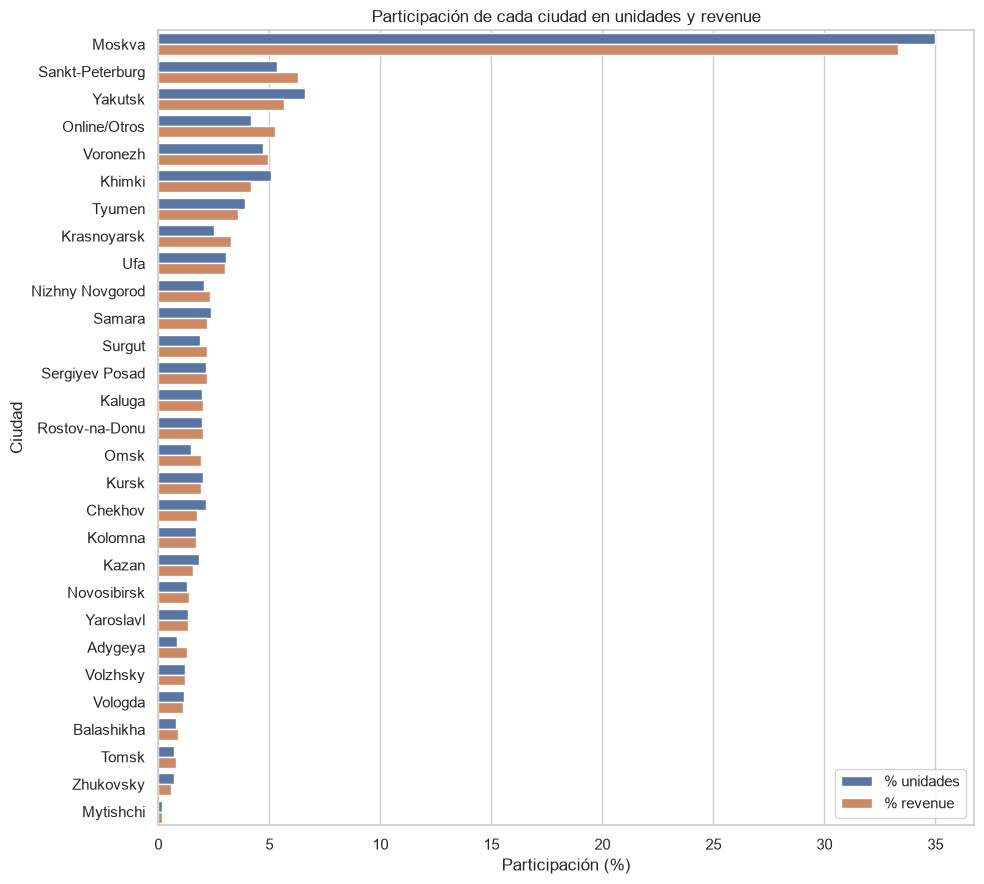

Ciudad,Tiendas,Unidades,% unidades,Revenue (M RUB),% revenue
Moskva,13,"1,276,374",35.0,"1,132.7",33.3
Sankt-Peterburg,2,"195,541",5.4,214.1,6.3
Yakutsk,2,"240,857",6.6,191.6,5.6
Online/Otros,3,"152,732",4.2,178.4,5.2
Voronezh,3,"171,142",4.7,167.4,4.9
Khimki,1,"185,789",5.1,141.9,4.2
Tyumen,3,"142,093",3.9,122.3,3.6
Krasnoyarsk,2,"91,324",2.5,111.2,3.3
Ufa,2,"111,401",3.1,101.6,3.0
Nizhny Novgorod,2,"75,467",2.1,78.8,2.3


In [29]:
city_share = (
    sales.groupby("ciudad")
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), n_shops=("shop_id", "nunique"))
    .reset_index()
)
city_share["% unidades"] = city_share["units"] / city_share["units"].sum() * 100
city_share["% revenue"] = city_share["revenue"] / city_share["revenue"].sum() * 100
city_share = city_share.sort_values("% revenue", ascending=False)

plot_data = city_share.melt(id_vars="ciudad", value_vars=["% unidades", "% revenue"],
                            var_name="Métrica", value_name="Participación (%)")
fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(data=plot_data, y="ciudad", x="Participación (%)", hue="Métrica", ax=ax)
ax.set_title("Participación de cada ciudad en unidades y revenue")
ax.set_xlabel("Participación (%)")
ax.set_ylabel("Ciudad")
ax.legend(title=None)
plt.tight_layout()
plt.show()

style_table(
    city_share.head(10).assign(revenue=lambda d: d["revenue"] / 1e6).rename(
        columns={"ciudad": "Ciudad", "n_shops": "Tiendas", "units": "Unidades",
                 "revenue": "Revenue (M RUB)"})
    [["Ciudad", "Tiendas", "Unidades", "% unidades", "Revenue (M RUB)", "% revenue"]],
    {"% unidades": "{:.1f}", "% revenue": "{:.1f}", "Revenue (M RUB)": "{:,.1f}"},
)

**Interpretación**


- **Moskva** concentra el 35.0 % de las unidades y el 33.3 % del revenue con 13 tiendas, más de cinco
  veces cualquier otra ciudad.
- Le siguen Sankt-Peterburg (6.3 % del revenue), Yakutsk (5.6 %), el canal Online/Otros (5.2 %), Voronezh
  (4.9 %) y Khimki (4.2 %). Las demás ciudades aportan menos del 4 % cada una.
- Algunas ciudades tienen más peso en revenue que en unidades, como Sankt-Peterburg (6.3 % frente a 5.4 %)
  y Online/Otros (5.2 % frente a 4.2 %), lo que sugiere una mezcla de productos más cara. En Yakutsk ocurre
  lo contrario (6.6 % de las unidades y 5.6 % del revenue).

#### 5.b.iii Por periodo

**Totales por año.** El histórico termina en octubre de 2015, así que 2015 solo tiene 10 meses. Para
comparar años en igualdad de condiciones se calculan también los totales de enero a octubre de cada año.

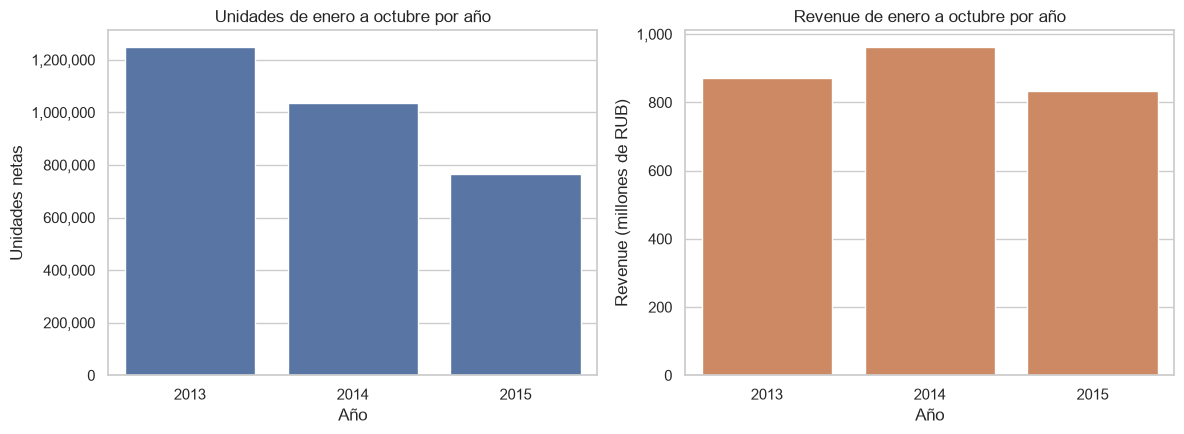

Año,Meses,Unidades,Revenue (M RUB),Unidades ene–oct,Revenue ene–oct (M RUB),Var. unidades ene–oct (%),Var. revenue ene–oct (%)
2013,12,"1,562,732","1,217.5","1,249,381",871.3,—,—
2014,12,"1,320,884","1,346.8","1,034,285",962.7,-17.2,+10.5
2015,10,"764,584",834.6,"764,584",834.6,-26.1,-13.3


In [30]:
sales["year"] = sales["date"].dt.year
sales["month"] = sales["date"].dt.month
is_jan_oct = sales["month"] <= 10

yearly = sales.groupby("year").agg(months=("month", "nunique"), units=("item_cnt_day", "sum"),
                                   revenue=("revenue", "sum"))
yearly_jan_oct = sales[is_jan_oct].groupby("year").agg(units_jan_oct=("item_cnt_day", "sum"),
                                                       revenue_jan_oct=("revenue", "sum"))
yearly = yearly.join(yearly_jan_oct).reset_index()
yearly["Var. unidades ene–oct (%)"] = yearly["units_jan_oct"].pct_change() * 100
yearly["Var. revenue ene–oct (%)"] = yearly["revenue_jan_oct"].pct_change() * 100
for col in ["revenue", "revenue_jan_oct"]:
    yearly[col] = yearly[col] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=yearly, x="year", y="units_jan_oct", ax=axes[0], color="C0")
axes[0].set_title("Unidades de enero a octubre por año")
axes[0].set_ylabel("Unidades netas")
sns.barplot(data=yearly, x="year", y="revenue_jan_oct", ax=axes[1], color="C1")
axes[1].set_title("Revenue de enero a octubre por año")
axes[1].set_ylabel("Revenue (millones de RUB)")
for ax in axes:
    ax.set_xlabel("Año")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

style_table(
    yearly.rename(columns={"year": "Año", "months": "Meses", "units": "Unidades",
                           "revenue": "Revenue (M RUB)", "units_jan_oct": "Unidades ene–oct",
                           "revenue_jan_oct": "Revenue ene–oct (M RUB)"}),
    {"Año": "{}", "Revenue (M RUB)": "{:,.1f}", "Revenue ene–oct (M RUB)": "{:,.1f}",
     "Var. unidades ene–oct (%)": "{:+.1f}", "Var. revenue ene–oct (%)": "{:+.1f}"},
)

**Interpretación**


- Comparando enero–octubre, las **unidades caen de forma sostenida**: −17.2 % en 2014 y −26.1 % en 2015,
  hasta 764,584 unidades.
- El **revenue no cae al mismo ritmo**: sube un 10.5 % en 2014 (de 871.3 a 962.7 M RUB) y baja un 13.3 % en
  2015 (834.6 M RUB). Se venden menos unidades, pero más caras. Los valores están en rublos nominales,
  por lo que incluyen el efecto de la inflación y de la devaluación del rublo de finales de 2014.
- Los totales anuales sin ajustar exageran la caída de 2015 (764,584 unidades frente a 1,320,884 en 2014),
  porque 2015 no incluye noviembre ni diciembre, los meses más fuertes.

**Por mes del año.** Unidades y revenue de cada mes calendario, con una línea por año.

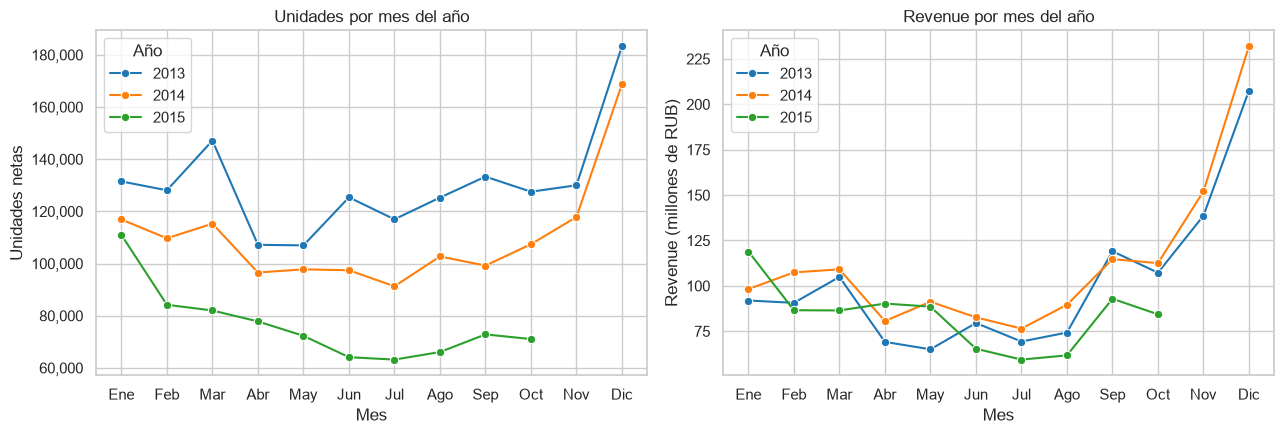

Mes,2013,2014,2015,Media mensual
Ene,"131,478","116,899","110,971","119,783"
Feb,"128,090","109,686","84,198","107,325"
Mar,"147,142","115,296","82,014","114,817"
Abr,"107,190","96,556","77,827","93,858"
May,"106,970","97,789","72,295","92,351"
Jun,"125,381","97,429","64,114","95,641"
Jul,"116,966","91,279","63,187","90,477"
Ago,"125,291","102,721","66,079","98,030"
Sep,"133,332","99,208","72,843","101,794"
Oct,"127,541","107,422","71,056","102,006"


In [31]:
MONTH_NAMES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

monthly = sales.groupby(["year", "month"]).agg(units=("item_cnt_day", "sum"),
                                               revenue=("revenue", "sum")).reset_index()
monthly["revenue_m"] = monthly["revenue"] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for metric, ax, title, ylabel in [
    ("units", axes[0], "Unidades por mes del año", "Unidades netas"),
    ("revenue_m", axes[1], "Revenue por mes del año", "Revenue (millones de RUB)"),
]:
    sns.lineplot(data=monthly, x="month", y=metric, hue="year", marker="o", palette="tab10", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Mes")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, 13), MONTH_NAMES)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(title="Año")
plt.tight_layout()
plt.show()

monthly_table = monthly.pivot(index="month", columns="year", values="units")
monthly_table.index = MONTH_NAMES
monthly_table["Media mensual"] = monthly_table.mean(axis=1)
monthly_table = monthly_table.reset_index(names="Mes")
monthly_table.columns = monthly_table.columns.astype(str)
style_table(monthly_table, {c: "{:,.0f}" for c in monthly_table.columns[1:]})

**Interpretación**


- **Diciembre es el pico claro** del año: 183,342 unidades en 2013 y 168,754 en 2014, frente a una media
  mensual de entre 90,000 y 124,000 en el resto de meses. En revenue el pico es todavía más pronunciado.
- **Noviembre sube respecto a octubre** en los dos años con datos: +1.9 % en unidades en 2013 (de 127,541 a
  130,009) y +9.7 % en 2014 (de 107,422 a 117,845). En revenue el salto es mayor. Es una referencia directa
  para el pronóstico de noviembre de 2015, cuyo octubre fue de 71,056 unidades.
- El verano (junio–agosto) es la temporada baja, y hay picos en enero, marzo y septiembre.
- 2015 está por debajo de los años anteriores en casi todos los meses en unidades, aunque en revenue se
  mantiene cerca de 2013 y 2014 hasta mayo.

**Por semana del año.** Unidades y revenue por semana ISO, con una línea por año ISO. La primera y la
última semana del histórico pueden estar incompletas.

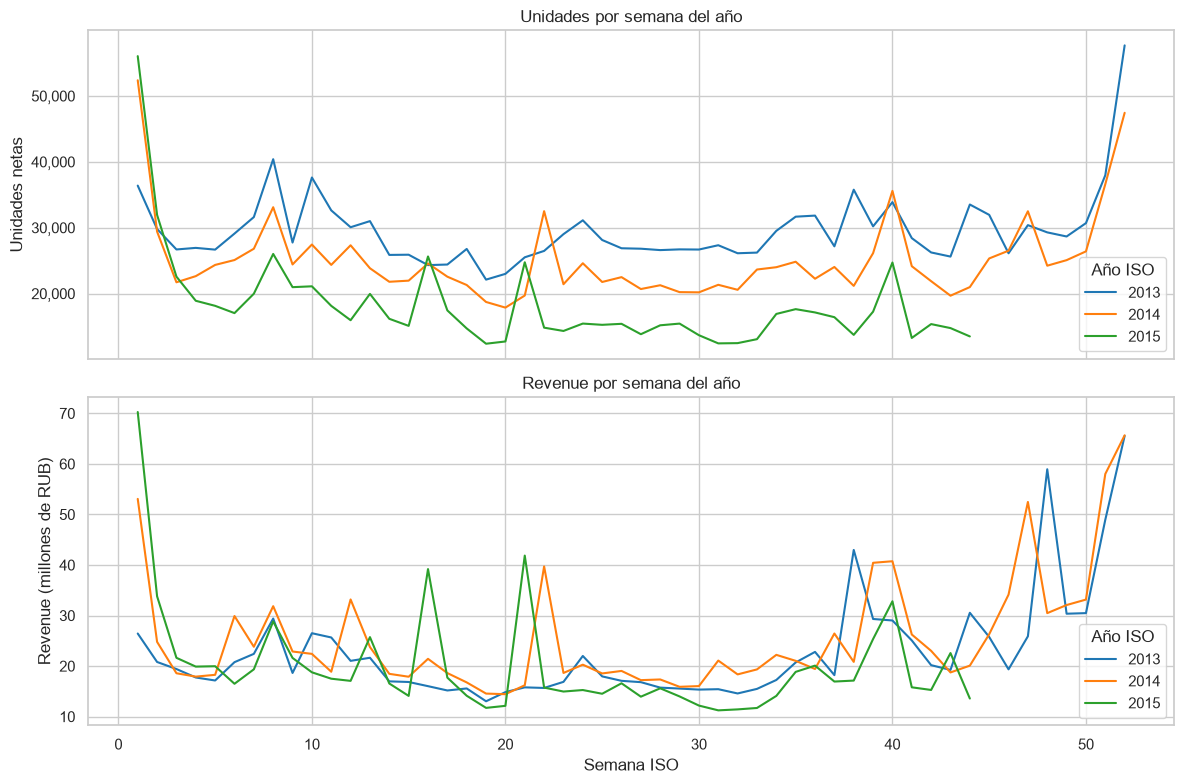

Métrica,Valor
Semanas completas,146
Mediana de unidades por semana,"24,500"
Semana 52 de 2013,"57,680 unidades"
Semana 1 de 2015,"56,048 unidades"
Semana 1 de 2014,"52,385 unidades"
Semana 52 de 2014,"47,444 unidades"
Semana 8 de 2013,"40,401 unidades"


In [32]:
iso = sales["date"].dt.isocalendar()
weekly = (
    sales.assign(iso_year=iso["year"].astype(int), iso_week=iso["week"].astype(int))
    .groupby(["iso_year", "iso_week"])
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), days=("date", "nunique"))
    .reset_index()
)
weekly["revenue_m"] = weekly["revenue"] / 1e6

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for metric, ax, title, ylabel in [
    ("units", axes[0], "Unidades por semana del año", "Unidades netas"),
    ("revenue_m", axes[1], "Revenue por semana del año", "Revenue (millones de RUB)"),
]:
    sns.lineplot(data=weekly, x="iso_week", y=metric, hue="iso_year", palette="tab10", ax=ax)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(title="Año ISO")
axes[1].set_xlabel("Semana ISO")
plt.tight_layout()
plt.show()

full_weeks = weekly[weekly["days"] == 7]
top_weeks = full_weeks.nlargest(5, "units")
style_table(
    pd.DataFrame(
        {
            "Métrica": ["Semanas completas", "Mediana de unidades por semana",
                        *[f"Semana {w} de {y}" for y, w in zip(top_weeks["iso_year"],
                                                                top_weeks["iso_week"])]],
            "Valor": [f"{len(full_weeks)}", f"{full_weeks['units'].median():,.0f}",
                      *[f"{u:,} unidades" for u in top_weeks["units"]]],
        }
    )
)

**Interpretación**


- La mediana es de 24,500 unidades por semana completa (146 semanas).
- Las semanas más fuertes coinciden con el fin de año: la semana 52 de 2013 (57,680 unidades) y la semana 1
  de 2015 (56,048), que en el calendario ISO va del 29/12/2014 al 04/01/2015. Les siguen la semana 1 de 2014
  y la 52 de 2014.
- Fuera de diciembre destaca la semana 8 de 2013 (40,401 unidades, del 18 al 24 de febrero), que coincide
  con la festividad del 23 de febrero en Rusia, una fecha de regalos.
- En revenue aparecen picos aislados sin un aumento equivalente de unidades. El más claro es la semana 48
  de 2013, con casi el doble de revenue que las semanas vecinas y unidades en niveles normales. Son
  compatibles con lanzamientos de productos caros, como videojuegos o consolas, y conviene verificarlos en
  el análisis por producto.

**Por día de la semana.** Media diaria de unidades y revenue según el día de la semana.

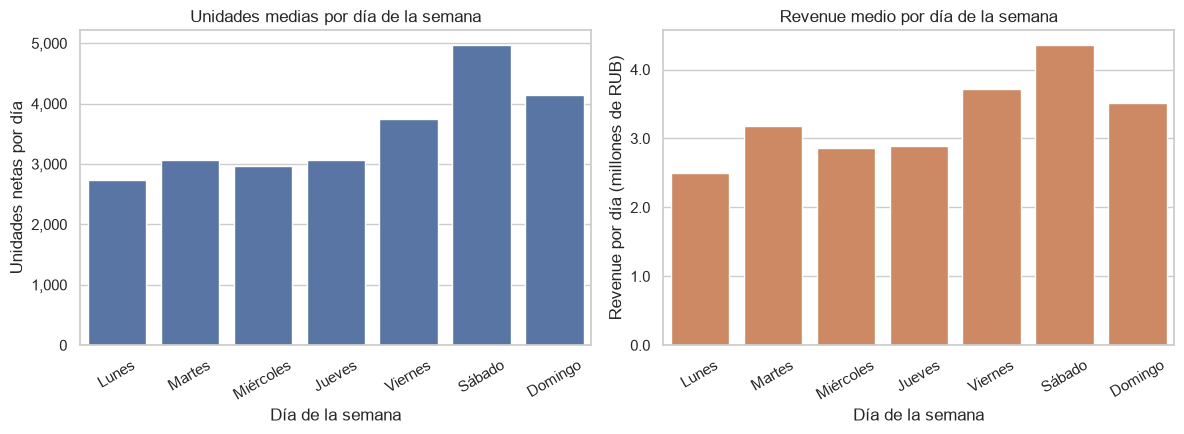

Día,Días,Unidades medias,Revenue medio (M RUB),Índice vs. media (%)
Lunes,147,"2,731",2.49,77
Martes,148,"3,074",3.17,87
Miércoles,148,"2,971",2.87,84
Jueves,148,"3,072",2.89,87
Viernes,148,"3,740",3.72,106
Sábado,148,"4,964",4.35,141
Domingo,147,"4,145",3.51,117


In [33]:
daily = sales.groupby("date").agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
daily["weekday"] = daily.index.day_of_week
by_weekday = daily.groupby("weekday").agg(units=("units", "mean"), revenue=("revenue", "mean"),
                                          days=("units", "size"))
by_weekday["revenue_m"] = by_weekday["revenue"] / 1e6
by_weekday["day"] = [DAY_NAMES[d] for d in by_weekday.index]
by_weekday["Índice vs. media (%)"] = by_weekday["units"] / daily["units"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=by_weekday, x="day", y="units", ax=axes[0], color="C0")
axes[0].set_title("Unidades medias por día de la semana")
axes[0].set_ylabel("Unidades netas por día")
sns.barplot(data=by_weekday, x="day", y="revenue_m", ax=axes[1], color="C1")
axes[1].set_title("Revenue medio por día de la semana")
axes[1].set_ylabel("Revenue por día (millones de RUB)")
for ax in axes:
    ax.set_xlabel("Día de la semana")
    ax.tick_params(axis="x", rotation=30)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.1f}" if ax is axes[1] else "{x:,.0f}"))
plt.tight_layout()
plt.show()

style_table(
    by_weekday.rename(columns={"day": "Día", "days": "Días", "units": "Unidades medias",
                               "revenue_m": "Revenue medio (M RUB)"})
    [["Día", "Días", "Unidades medias", "Revenue medio (M RUB)", "Índice vs. media (%)"]],
    {"Unidades medias": "{:,.0f}", "Revenue medio (M RUB)": "{:,.2f}", "Índice vs. media (%)": "{:.0f}"},
)

**Interpretación**


- El **sábado** es el día más fuerte: 4,964 unidades y 4.35 M RUB de media, un 41 % por encima de la media
  diaria. Le siguen el domingo (4,145 unidades) y el viernes (3,740).
- El **lunes** es el día más débil: 2,731 unidades y 2.49 M RUB, un 23 % por debajo de la media. De martes a
  jueves los valores son parecidos (entre 2,971 y 3,074 unidades).
- El ciclo semanal es marcado, pero cada mes contiene un número similar de cada día de la semana, así que
  su efecto se compensa casi por completo al agregar por mes.

#### Guardado de los datos enriquecidos

Se guardan `sales_clean` y las columnas nuevas (`revenue`, `item_category_id`, `categoria_principal`,
`ciudad` y `tipo_tienda`) en `data/interim/sales_enriched.parquet`. Las columnas de texto repetitivas se
almacenan como `category` para reducir tamaño; los nombres originales en ruso pueden recuperarse uniendo
con los catálogos.

In [34]:
ENRICHED_COLUMNS = ["date", "date_block_num", "shop_id", "item_id", "item_price", "item_cnt_day",
                    "revenue", "item_category_id", "categoria_principal", "ciudad", "tipo_tienda"]

sales_enriched = sales[ENRICHED_COLUMNS].copy()
for col in ["categoria_principal", "ciudad", "tipo_tienda"]:
    sales_enriched[col] = sales_enriched[col].astype("category")

enriched_path = INTERIM_PATH / ENRICHED_SALES_FILE
sales_enriched.to_parquet(enriched_path, index=False)
reloaded = load_parquet(ENRICHED_SALES_FILE)

style_table(
    pd.DataFrame(
        {
            "Verificación": ["Archivo", "Registros", "Columnas", "Memoria en pandas (MB)",
                             "Filas y tipos al releer"],
            "Resultado": [enriched_path.as_posix(), f"{len(sales_enriched):,}",
                          f"{sales_enriched.shape[1]}", f"{memory_mb(sales_enriched):,.2f}",
                          "Coinciden" if reloaded.shape == sales_enriched.shape
                          and reloaded.dtypes.equals(sales_enriched.dtypes) else "No coinciden"],
        }
    )
)

Verificación,Resultado
Archivo,../data/interim/sales_enriched.parquet
Registros,"2,935,843"
Columnas,11
Memoria en pandas (MB),100.79
Filas y tipos al releer,Coinciden


## 6. Exploración temporal

#### Preparación de las series

Se cargan las ventas enriquecidas y se construyen las series mensual (`date_block_num` 0–33) y semanal de
unidades y revenue. Las semanas van de lunes a domingo y se conservan solo las completas (7 días), lo que
excluye la primera y la última semana del histórico.

In [35]:
sales_ts = load_parquet(ENRICHED_SALES_FILE)

monthly_ts = (
    sales_ts.groupby("date_block_num")
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), shops=("shop_id", "nunique"))
)
monthly_ts.index = pd.date_range("2013-01-01", periods=len(monthly_ts), freq="MS")
monthly_ts["revenue_m"] = monthly_ts["revenue"] / 1e6

weekly_ts = (
    sales_ts.groupby(pd.Grouper(key="date", freq="W-SUN"))
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), days=("date", "nunique"))
)
weekly_ts = weekly_ts[weekly_ts["days"] == 7].drop(columns="days")
weekly_ts["revenue_m"] = weekly_ts["revenue"] / 1e6

print(f"Meses: {len(monthly_ts)} | Semanas completas: {len(weekly_ts)} "
      f"({weekly_ts.index.min():%d/%m/%Y} a {weekly_ts.index.max():%d/%m/%Y}, fecha de cierre de semana)")

Meses: 34 | Semanas completas: 146 (13/01/2013 a 25/10/2015, fecha de cierre de semana)


### 6.a Evolución de las ventas

**Serie mensual.** Unidades y revenue por mes, con los meses de diciembre resaltados.

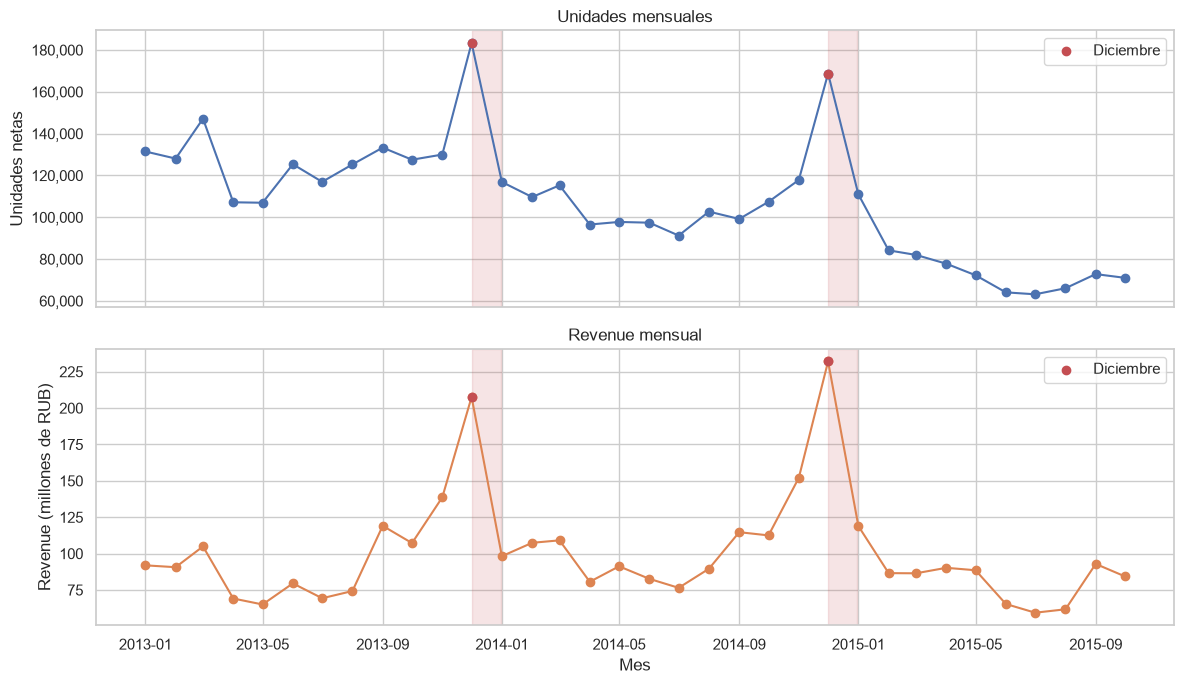

Métrica,Valor
Mes con más unidades,"2013-12 (183,342)"
Mes con menos unidades,"2015-07 (63,187)"
Mes con más revenue,2014-12 (232.0 M RUB)
Mes con menos revenue,2015-07 (59.4 M RUB)
Unidades: primeros 12 meses vs. últimos 12 meses,"1,562,732 vs. 1,051,183 (-32.7%)"


In [36]:
december_months = monthly_ts.index[monthly_ts.index.month == 12]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, col, color, title, ylabel in [
    (axes[0], "units", "C0", "Unidades mensuales", "Unidades netas"),
    (axes[1], "revenue_m", "C1", "Revenue mensual", "Revenue (millones de RUB)"),
]:
    ax.plot(monthly_ts.index, monthly_ts[col], marker="o", color=color)
    for month in december_months:
        ax.axvspan(month, month + pd.offsets.MonthEnd(1), color="C3", alpha=0.15)
    ax.scatter(december_months, monthly_ts.loc[december_months, col], color="C3", zorder=3,
               label="Diciembre")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(loc="upper right")
axes[1].set_xlabel("Mes")
plt.tight_layout()
plt.show()

monthly_extremes = pd.DataFrame(
    {
        "Métrica": ["Mes con más unidades", "Mes con menos unidades", "Mes con más revenue",
                    "Mes con menos revenue", "Unidades: primeros 12 meses vs. últimos 12 meses"],
        "Valor": [
            f"{monthly_ts['units'].idxmax():%Y-%m} ({monthly_ts['units'].max():,})",
            f"{monthly_ts['units'].idxmin():%Y-%m} ({monthly_ts['units'].min():,})",
            f"{monthly_ts['revenue_m'].idxmax():%Y-%m} ({monthly_ts['revenue_m'].max():,.1f} M RUB)",
            f"{monthly_ts['revenue_m'].idxmin():%Y-%m} ({monthly_ts['revenue_m'].min():,.1f} M RUB)",
            f"{monthly_ts['units'].iloc[:12].sum():,} vs. {monthly_ts['units'].iloc[-12:].sum():,} "
            f"({monthly_ts['units'].iloc[-12:].sum() / monthly_ts['units'].iloc[:12].sum() - 1:+.1%})",
        ],
    }
)
style_table(monthly_extremes)

**Interpretación**

- La serie mensual combina una **tendencia descendente** con **picos en diciembre**. Las unidades de los
  últimos 12 meses (1,051,183) son un 32.7 % menores que las de los primeros 12 (1,562,732).
- El máximo de unidades es diciembre de 2013 (183,342) y el mínimo julio de 2015 (63,187).
- El revenue no sigue la misma tendencia: su máximo es diciembre de 2014 (232.0 M RUB), aunque ese mes se
  vendieron menos unidades que en diciembre de 2013. Además, el revenue sube con fuerza de septiembre a
  diciembre, por la temporada de lanzamientos de videojuegos y consolas antes de fin de año.
- Ambas series coinciden en el mínimo, julio de 2015 (59.4 M RUB), lo que confirma la debilidad de 2015.

**Serie semanal.** Unidades por semana completa, con una media móvil de 9 semanas para distinguir la
tendencia de las oscilaciones de corto plazo.

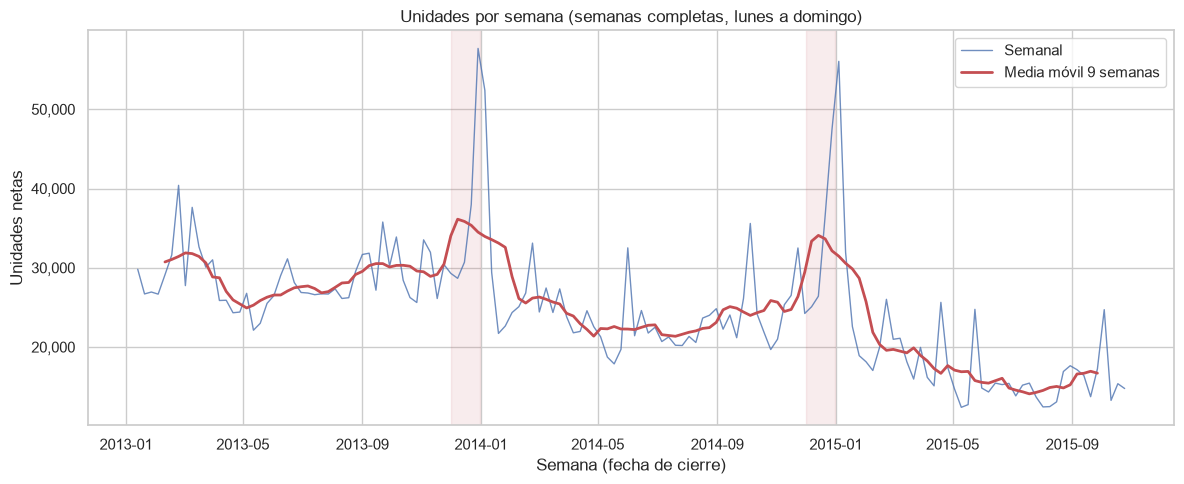

Métrica,Valor
Semanas completas,146
Mediana semanal,"24,500"
Semana máxima,"29/12/2013 (57,680)"
Semana mínima,"10/05/2015 (12,389)"
Coeficiente de variación semanal,31.7%
Coeficiente de variación mensual,26.5%


In [37]:
weekly_rolling = weekly_ts["units"].rolling(9, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly_ts.index, weekly_ts["units"], linewidth=1, alpha=0.8, label="Semanal")
ax.plot(weekly_rolling.index, weekly_rolling, linewidth=2, color="C3", label="Media móvil 9 semanas")
for month in december_months:
    ax.axvspan(month, month + pd.offsets.MonthEnd(1), color="C3", alpha=0.1)
ax.set_title("Unidades por semana (semanas completas, lunes a domingo)")
ax.set_xlabel("Semana (fecha de cierre)")
ax.set_ylabel("Unidades netas")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

weekly_summary = pd.DataFrame(
    {
        "Métrica": ["Semanas completas", "Mediana semanal", "Semana máxima", "Semana mínima",
                    "Coeficiente de variación semanal", "Coeficiente de variación mensual"],
        "Valor": [
            f"{len(weekly_ts)}",
            f"{weekly_ts['units'].median():,.0f}",
            f"{weekly_ts['units'].idxmax():%d/%m/%Y} ({weekly_ts['units'].max():,})",
            f"{weekly_ts['units'].idxmin():%d/%m/%Y} ({weekly_ts['units'].min():,})",
            f"{weekly_ts['units'].std() / weekly_ts['units'].mean():.1%}",
            f"{monthly_ts['units'].std() / monthly_ts['units'].mean():.1%}",
        ],
    }
)
style_table(weekly_summary)

**Interpretación**

- La serie semanal (146 semanas completas, con una mediana de 24,500 unidades) es más volátil que la
  mensual: su coeficiente de variación es del 31.7 %, frente al 26.5 % de la mensual.
- Muestra detalles que la serie mensual oculta: el pico de fin de año dura dos semanas (la máxima cierra el
  29/12/2013, con 57,680 unidades), hay picos puntuales a mitad de mes y caídas tras las fiestas.
- La semana más baja cierra el 10/05/2015 (12,389 unidades) y coincide con los feriados rusos de principios
  de mayo.
- La media móvil de 9 semanas confirma la caída de nivel, más pronunciada desde enero de 2015.

### 6.b Patrones

#### 6.b.i Tendencia

Se descompone la serie mensual de unidades con `seasonal_decompose` (periodo 12). Para elegir entre el
modelo aditivo y el multiplicativo se compara el tamaño relativo de sus residuos: se elige el que deja un
residuo menor en proporción al nivel de la serie. Con 34 meses y una media móvil centrada de 12 meses, la
tendencia y el residuo solo pueden estimarse de julio de 2013 a abril de 2015.

Modelo,Desv. estándar del residuo relativo (%),Máx. |residuo relativo| (%)
Aditivo,4.01,9.53
Multiplicativo,4.54,8.73


Modelo elegido: aditivo


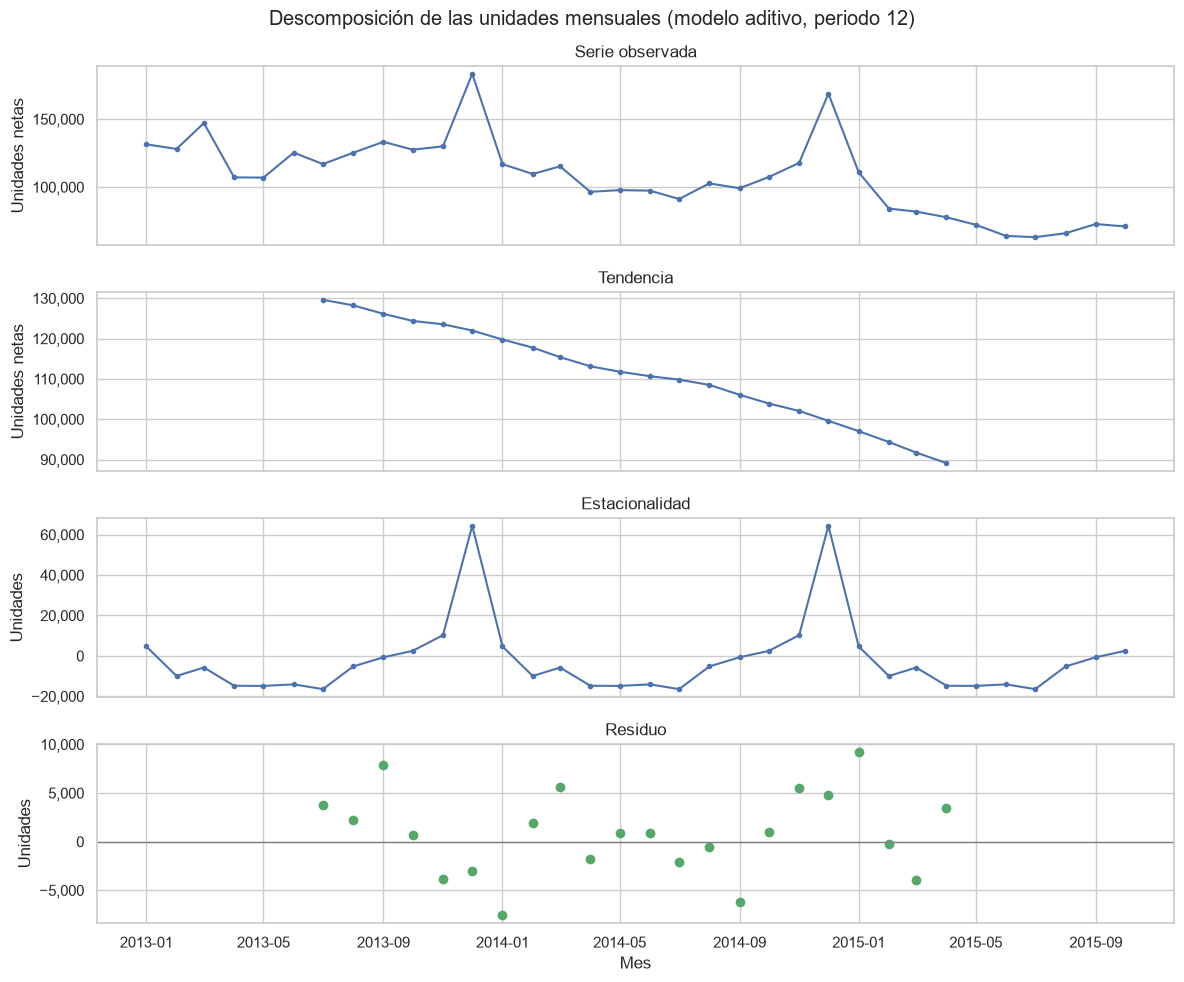

Métrica,Valor
Tendencia inicial,"2013-07: 129,620"
Tendencia final,"2015-04: 89,114"
Variación total,-31.3%
Variación media mensual,-1.77%


In [38]:
decompositions = {
    model: seasonal_decompose(monthly_ts["units"], model=model, period=12)
    for model in ["additive", "multiplicative"]
}
relative_residual = {
    "additive": (decompositions["additive"].resid / decompositions["additive"].trend).dropna(),
    "multiplicative": (decompositions["multiplicative"].resid - 1).dropna(),
}
model_comparison = pd.DataFrame(
    {
        "Modelo": ["Aditivo", "Multiplicativo"],
        "Desv. estándar del residuo relativo (%)": [relative_residual[m].std() * 100
                                                    for m in relative_residual],
        "Máx. |residuo relativo| (%)": [relative_residual[m].abs().max() * 100
                                        for m in relative_residual],
    }
)
DECOMPOSITION_MODEL = min(relative_residual, key=lambda m: relative_residual[m].std())
decomposition = decompositions[DECOMPOSITION_MODEL]
MODEL_LABEL = {"additive": "aditivo", "multiplicative": "multiplicativo"}[DECOMPOSITION_MODEL]
display(style_table(model_comparison, {c: "{:.2f}" for c in model_comparison.columns[1:]}))
print(f"Modelo elegido: {MODEL_LABEL}")

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
components = [
    (monthly_ts["units"], "Serie observada", "Unidades netas"),
    (decomposition.trend, "Tendencia", "Unidades netas"),
    (decomposition.seasonal, "Estacionalidad", "Índice" if DECOMPOSITION_MODEL == "multiplicative"
     else "Unidades"),
    (decomposition.resid, "Residuo", "Índice" if DECOMPOSITION_MODEL == "multiplicative"
     else "Unidades"),
]
for ax, (series, title, ylabel) in zip(axes, components):
    if title == "Residuo":
        ax.axhline(1 if DECOMPOSITION_MODEL == "multiplicative" else 0, color="grey", linewidth=1)
        ax.scatter(series.index, series, color="C2")
    else:
        ax.plot(series.index, series, marker="o", markersize=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    fmt = "{x:,.2f}" if (DECOMPOSITION_MODEL == "multiplicative" and title in ("Estacionalidad", "Residuo")) \
        else "{x:,.0f}"
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter(fmt))
axes[-1].set_xlabel("Mes")
fig.suptitle(f"Descomposición de las unidades mensuales (modelo {MODEL_LABEL}, periodo 12)")
plt.tight_layout()
plt.show()

trend = decomposition.trend.dropna()
trend_summary = pd.DataFrame(
    {
        "Métrica": ["Tendencia inicial", "Tendencia final", "Variación total",
                    "Variación media mensual"],
        "Valor": [f"{trend.index[0]:%Y-%m}: {trend.iloc[0]:,.0f}",
                  f"{trend.index[-1]:%Y-%m}: {trend.iloc[-1]:,.0f}",
                  f"{trend.iloc[-1] / trend.iloc[0] - 1:+.1%}",
                  f"{(trend.iloc[-1] / trend.iloc[0]) ** (1 / (len(trend) - 1)) - 1:+.2%}"],
    }
)
style_table(trend_summary)

**Interpretación**

- Los dos modelos dan residuos parecidos. El **aditivo** deja un residuo relativo algo menor (desviación de
  4.01 % frente a 4.54 %), por lo que se elige. El tamaño del pico de diciembre se mantiene en valores
  absolutos (unas +53,000 unidades sobre la media en 2013 y unas +59,000 en 2014), aunque el nivel baja.
- **Tendencia:** cae de forma continua, de 129,620 unidades (julio de 2013) a 89,114 (abril de 2015), un
  −31.3 % (−1.77 % mensual de media). La pendiente se acentúa desde finales de 2014.
- **Estacionalidad:** diciembre suma unas +64,390 unidades sobre la tendencia, y noviembre +10,271. De abril
  a julio la serie queda entre 14,000 y 16,500 unidades por debajo.
- **Residuo:** se mantiene entre unas −7,500 y +9,250 unidades, sin meses extremos. Tendencia y
  estacionalidad explican la mayor parte de la serie mensual.
- Con 34 meses, cada índice estacional se estima con solo 2 o 3 observaciones, así que debe tomarse como una
  aproximación.

**Variación interanual.** Tasa de variación de unidades y revenue respecto al mismo mes del año anterior
(disponible desde enero de 2014).

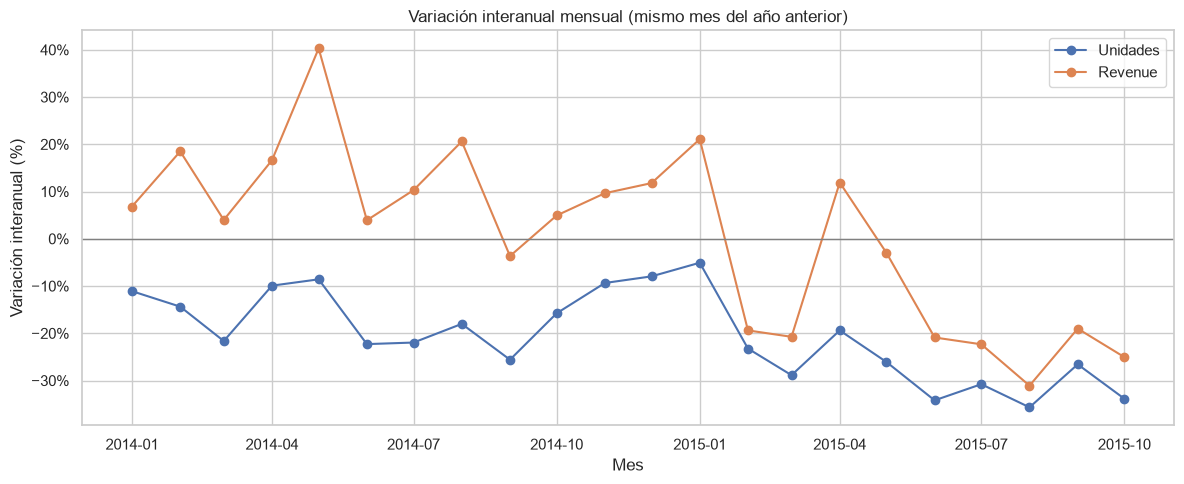

Año,Métrica,Media (%),Mínimo (%),Máximo (%),Meses con caída
2014,Unidades,-15.5,-25.6,-8.0,12 de 12
2014,Revenue,+12.0,-3.7,+40.3,1 de 12
2015,Unidades,-26.4,-35.7,-5.1,10 de 10
2015,Revenue,-12.9,-31.1,+21.1,8 de 10


Mes,Var. unidades (%),Var. revenue (%)
2014-01,-11.1,+6.8
2014-02,-14.4,+18.5
2014-03,-21.6,+4.0
2014-04,-9.9,+16.6
2014-05,-8.6,+40.3
2014-06,-22.3,+3.9
2014-07,-22.0,+10.3
2014-08,-18.0,+20.6
2014-09,-25.6,-3.7
2014-10,-15.8,+4.9


In [39]:
yoy = (monthly_ts[["units", "revenue"]].pct_change(12) * 100).dropna()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yoy.index, yoy["units"], marker="o", label="Unidades")
ax.plot(yoy.index, yoy["revenue"], marker="o", label="Revenue")
ax.axhline(0, color="grey", linewidth=1)
ax.set_title("Variación interanual mensual (mismo mes del año anterior)")
ax.set_xlabel("Mes")
ax.set_ylabel("Variación interanual (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend()
plt.tight_layout()
plt.show()

yoy_table = yoy.reset_index(names="Mes").assign(Mes=lambda d: d["Mes"].dt.strftime("%Y-%m"))
yoy_table = yoy_table.rename(columns={"units": "Var. unidades (%)", "revenue": "Var. revenue (%)"})
yoy_by_year = pd.DataFrame(
    [
        {"Año": str(year), "Métrica": label, "Media (%)": group[col].mean(),
         "Mínimo (%)": group[col].min(), "Máximo (%)": group[col].max(),
         "Meses con caída": f"{(group[col] < 0).sum()} de {len(group)}"}
        for year, group in yoy.groupby(yoy.index.year)
        for col, label in [("units", "Unidades"), ("revenue", "Revenue")]
    ]
)
display(style_table(yoy_by_year, {c: "{:+.1f}" for c in ["Media (%)", "Mínimo (%)", "Máximo (%)"]}))
style_table(yoy_table, {"Var. unidades (%)": "{:+.1f}", "Var. revenue (%)": "{:+.1f}"})

**Interpretación**

- **Unidades:** caen en los 22 meses comparables. La caída media es del −15.5 % en 2014 y se acelera al
  −26.4 % en 2015, con un mínimo de −35.7 % en agosto de 2015.
- **Revenue:** crece en 2014 (+12.0 % de media; solo septiembre cae) y alcanza +40.3 % en mayo de 2014. En
  2015 cambia de signo: cae en 8 de 10 meses (−12.9 % de media).
- Las excepciones de 2015 son enero (+21.1 %) y abril (+11.9 %). Abril coincide con el lanzamiento de GTA V
  para PC (6.b.iii).
- Hasta finales de 2014 la caída de volumen se compensó con precios más altos. En 2015 ya caen ambas
  métricas, lo que anticipa un noviembre de 2015 claramente por debajo de noviembre de 2014.

#### 6.b.ii Estacionalidad

Unidades por mes del año con una línea por año, en valores absolutos y como índice sobre la media de enero
a octubre de cada año (para comparar la forma del perfil aunque el nivel cambie), junto con el índice
estacional de la descomposición.

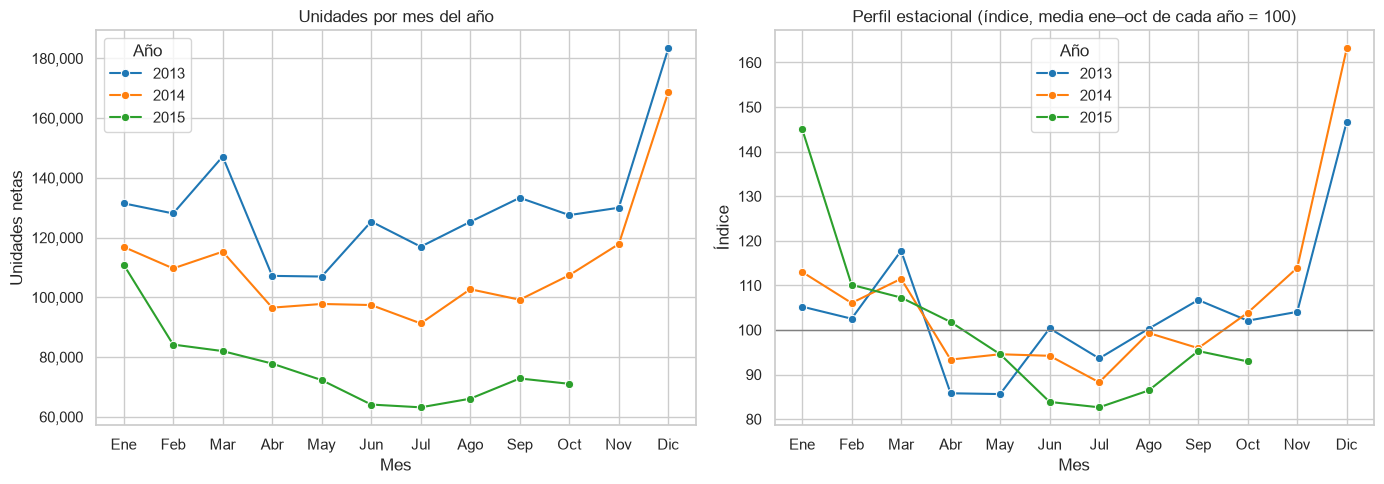

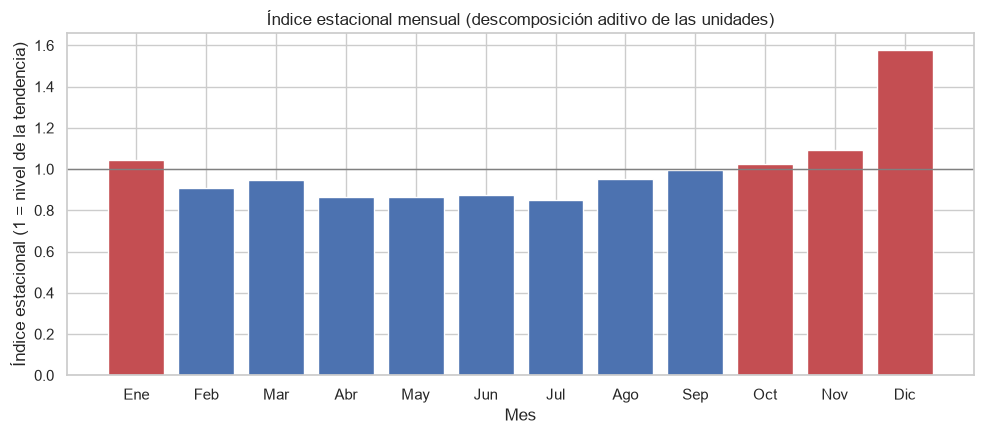

Mes,Componente estacional (unidades),Índice estacional,Efecto sobre la tendencia (%)
Ene,"+4,674",1.042,+4.2
Feb,"-9,965",0.910,-9.0
Mar,"-5,758",0.948,-5.2
Abr,"-14,785",0.867,-13.3
May,"-14,856",0.866,-13.4
Jun,"-14,101",0.873,-12.7
Jul,"-16,449",0.852,-14.8
Ago,"-5,224",0.953,-4.7
Sep,-689,0.994,-0.6
Oct,"+2,491",1.022,+2.2


In [40]:
MONTH_NAMES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

seasonal_profile = monthly_ts[["units"]].assign(year=monthly_ts.index.year, month=monthly_ts.index.month)
jan_oct_mean = seasonal_profile[seasonal_profile["month"] <= 10].groupby("year")["units"].mean()
seasonal_profile["index_jan_oct"] = seasonal_profile["units"] / seasonal_profile["year"].map(jan_oct_mean) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=seasonal_profile, x="month", y="units", hue="year", marker="o", palette="tab10",
             ax=axes[0])
axes[0].set_title("Unidades por mes del año")
axes[0].set_ylabel("Unidades netas")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
sns.lineplot(data=seasonal_profile, x="month", y="index_jan_oct", hue="year", marker="o",
             palette="tab10", ax=axes[1])
axes[1].axhline(100, color="grey", linewidth=1)
axes[1].set_title("Perfil estacional (índice, media ene–oct de cada año = 100)")
axes[1].set_ylabel("Índice")
for ax in axes:
    ax.set_xlabel("Mes")
    ax.set_xticks(range(1, 13), MONTH_NAMES)
    ax.legend(title="Año")
plt.tight_layout()
plt.show()

seasonal_component = decomposition.seasonal.iloc[:12]
seasonal_component.index = seasonal_component.index.month
seasonal_component = seasonal_component.sort_index()
if DECOMPOSITION_MODEL == "multiplicative":
    seasonal_index = seasonal_component
else:
    # En el modelo aditivo el índice equivalente es 1 + componente / nivel medio de la tendencia
    seasonal_index = 1 + seasonal_component / decomposition.trend.mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(MONTH_NAMES, seasonal_index.values, color=["C3" if v > 1 else "C0" for v in seasonal_index])
ax.axhline(1, color="grey", linewidth=1)
ax.set_title(f"Índice estacional mensual (descomposición {MODEL_LABEL} de las unidades)")
ax.set_xlabel("Mes")
ax.set_ylabel("Índice estacional (1 = nivel de la tendencia)")
plt.tight_layout()
plt.show()

seasonal_table = pd.DataFrame({"Mes": MONTH_NAMES, "Índice estacional": seasonal_index.values,
                               "Efecto sobre la tendencia (%)": (seasonal_index.values - 1) * 100})
if DECOMPOSITION_MODEL == "additive":
    seasonal_table.insert(1, "Componente estacional (unidades)", seasonal_component.values)
style_table(seasonal_table, {"Componente estacional (unidades)": "{:+,.0f}", "Índice estacional": "{:.3f}",
                             "Efecto sobre la tendencia (%)": "{:+.1f}"})

**Interpretación**

- El perfil estacional es parecido en los años con datos completos: un primer trimestre por encima de la
  media, una temporada baja de abril a agosto y una subida desde septiembre que culmina en diciembre.
- En índice sobre la media enero–octubre, diciembre llega a 146.7 en 2013 y a 163.2 en 2014, y noviembre a
  104.1 y 113.9. El repunte de fin de año ha ganado peso relativo.
- 2015 sigue un perfil similar hasta octubre, pero desplazado a la baja. Su enero (índice 145) destaca
  porque el resto del año cae con fuerza.
- **Índice estacional:** diciembre se sitúa un 57.9 % por encima de la tendencia (1.579) y noviembre un
  9.2 % (1.092). De abril a julio está entre un 12.7 % y un 14.8 % por debajo, y septiembre y octubre
  rondan la tendencia (0.994 y 1.022).
- Para noviembre de 2015 se espera un mes por encima del nivel de tendencia, aunque lejos del pico de
  diciembre.

#### 6.b.iii Picos y caídas abruptas

**A nivel mensual** se revisan los residuos de la descomposición: un mes es atípico si su residuo se aleja
más de ±2 desviaciones estándar de la media de los residuos.

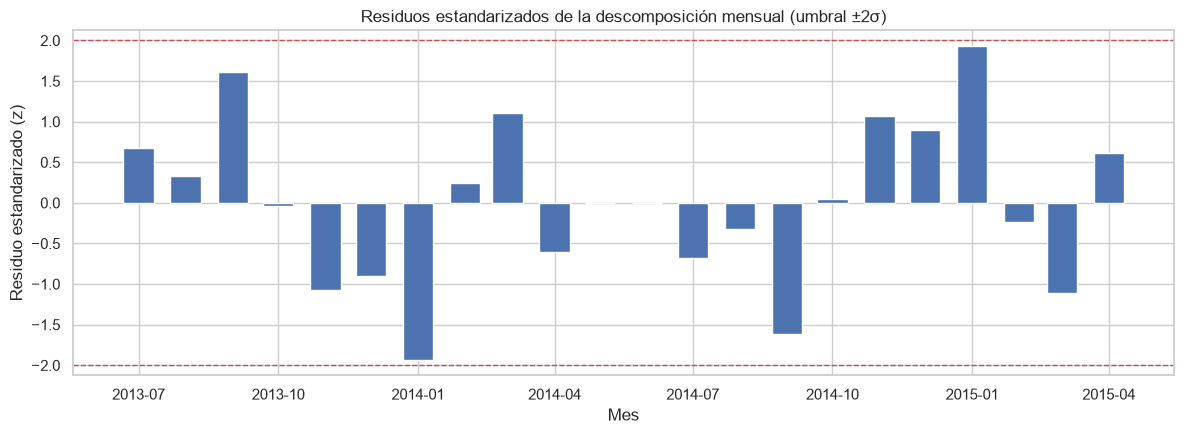

Meses con |z| > 2: 0


Mes,Residuo,z
2015-01,9246.564,+1.93
2014-01,-7549.644,-1.93
2013-09,7868.835,+1.61
2014-09,-6171.915,-1.61


In [41]:
resid = decomposition.resid.dropna()
resid_z = (resid - resid.mean()) / resid.std()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(resid_z.index, resid_z, width=20, color=["C3" if abs(z) > 2 else "C0" for z in resid_z])
for bound in (-2, 2):
    ax.axhline(bound, color="C3", linestyle="--", linewidth=1)
ax.set_title("Residuos estandarizados de la descomposición mensual (umbral ±2σ)")
ax.set_xlabel("Mes")
ax.set_ylabel("Residuo estandarizado (z)")
plt.tight_layout()
plt.show()

monthly_outliers = resid_z[resid_z.abs() > 2]
print(f"Meses con |z| > 2: {len(monthly_outliers)}")
largest_resid = resid_z.reindex(resid_z.abs().sort_values(ascending=False).index).head(4)
style_table(
    pd.DataFrame({"Mes": largest_resid.index.strftime("%Y-%m"), "Residuo": resid.loc[largest_resid.index].values,
                  "z": largest_resid.values}),
    {"Residuo": "{:.3f}", "z": "{:+.2f}"},
)

**Interpretación**

- Ningún mes supera el umbral de ±2σ: la serie mensual no tiene picos ni caídas abruptas que no expliquen la
  tendencia y la estacionalidad. El pico de diciembre ya lo absorbe el componente estacional.
- Los residuos más grandes son enero de 2015 (+9,247 unidades, z = +1.93), enero de 2014 (−7,550,
  z = −1.93), septiembre de 2013 (+7,869, z = +1.61, el mes del lanzamiento de GTA V) y septiembre de 2014
  (−6,172, z = −1.61).
- Las variaciones atípicas aparecen al bajar a nivel semanal.

**A nivel semanal** se mide la desviación de cada semana respecto a su media móvil centrada de 9 semanas,
en unidades y en revenue. Una semana es atípica si esa desviación se aleja más de ±2 desviaciones estándar.

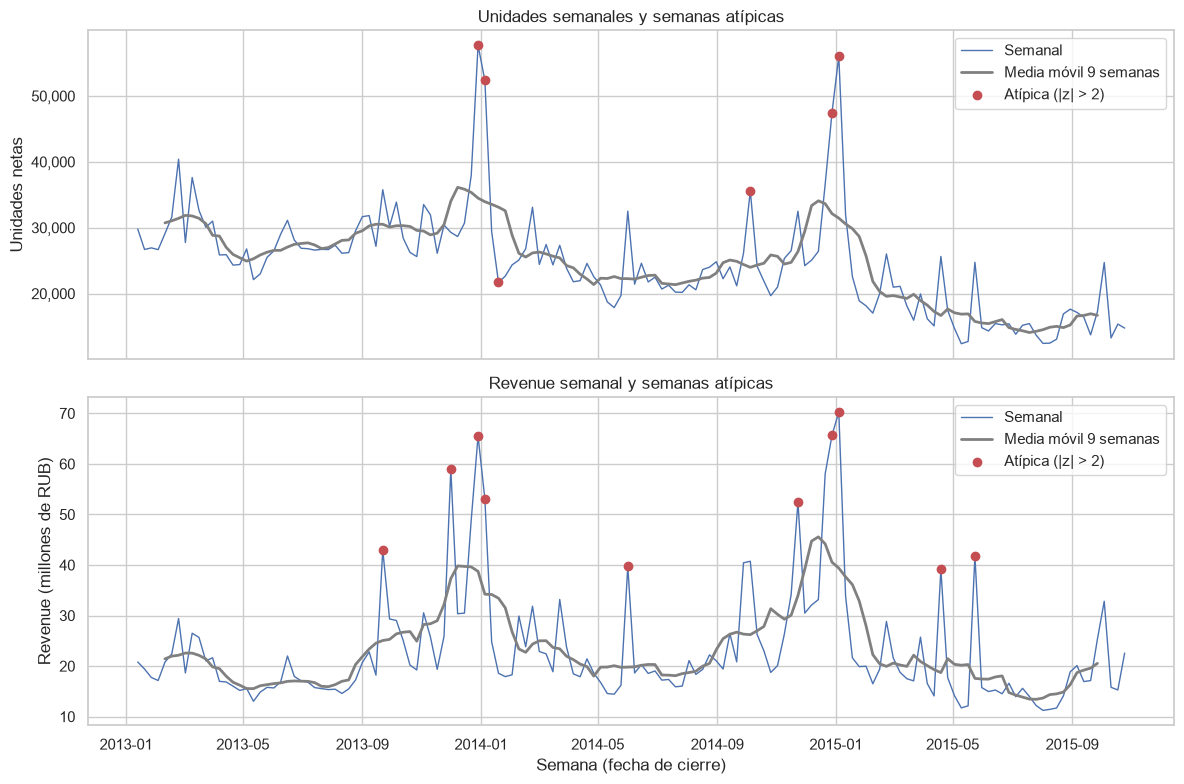

Semana (cierre),Métrica,Valor,Media móvil,Desviación (%),z
22/09/2013,Revenue (M RUB),43.0,25.1,+71.5,+2.19
01/12/2013,Revenue (M RUB),58.9,37.3,+58.0,+2.64
29/12/2013,Revenue (M RUB),65.5,38.7,+69.2,+3.27
29/12/2013,Unidades,"57,680.0","34,496.6",+67.2,+4.49
05/01/2014,Revenue (M RUB),53.1,34.2,+55.1,+2.30
05/01/2014,Unidades,"52,385.0","33,947.6",+54.3,+3.57
19/01/2014,Unidades,"21,714.0","33,118.1",-34.4,-2.21
01/06/2014,Revenue (M RUB),39.7,19.8,+100.7,+2.43
05/10/2014,Unidades,"35,592.0","23,988.8",+48.4,+2.24
23/11/2014,Revenue (M RUB),52.5,33.9,+54.6,+2.26


In [42]:
def flag_weekly_anomalies(series: pd.Series, window: int = 9) -> pd.DataFrame:
    rolling = series.rolling(window, center=True).mean()
    deviation = series - rolling
    z = (deviation - deviation.mean()) / deviation.std()
    return pd.DataFrame({"value": series, "rolling": rolling, "z": z})


weekly_anomalies = {
    "units": flag_weekly_anomalies(weekly_ts["units"]),
    "revenue_m": flag_weekly_anomalies(weekly_ts["revenue_m"]),
}

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (metric, frame), title, ylabel in zip(
    axes, weekly_anomalies.items(), ["Unidades semanales", "Revenue semanal"],
    ["Unidades netas", "Revenue (millones de RUB)"],
):
    outliers = frame[frame["z"].abs() > 2]
    ax.plot(frame.index, frame["value"], linewidth=1, label="Semanal")
    ax.plot(frame.index, frame["rolling"], linewidth=2, color="grey", label="Media móvil 9 semanas")
    ax.scatter(outliers.index, outliers["value"], color="C3", zorder=3, label="Atípica (|z| > 2)")
    ax.set_title(f"{title} y semanas atípicas")
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(loc="upper right")
axes[1].set_xlabel("Semana (fecha de cierre)")
plt.tight_layout()
plt.show()

anomaly_rows = []
for metric, frame in weekly_anomalies.items():
    for week_end, row in frame[frame["z"].abs() > 2].iterrows():
        anomaly_rows.append({
            "Semana (cierre)": week_end, "Métrica": "Unidades" if metric == "units" else "Revenue (M RUB)",
            "Valor": row["value"], "Media móvil": row["rolling"],
            "Desviación (%)": (row["value"] / row["rolling"] - 1) * 100, "z": row["z"],
        })
weekly_outliers = pd.DataFrame(anomaly_rows).sort_values(["Semana (cierre)", "Métrica"])
style_table(
    weekly_outliers.assign(**{"Semana (cierre)": weekly_outliers["Semana (cierre)"].dt.strftime("%d/%m/%Y")}),
    {"Valor": "{:,.1f}", "Media móvil": "{:,.1f}", "Desviación (%)": "{:+.1f}", "z": "{:+.2f}"},
)

**Interpretación**

- Se detectan 16 semanas atípicas: 6 en unidades y 10 en revenue.
- **Fin de año:** las semanas que cierran el 29/12/2013, 05/01/2014, 28/12/2014 y 04/01/2015 son atípicas en
  ambas métricas, con desviaciones de entre +47.6 % y +78.4 % sobre su media móvil.
- **Picos solo en revenue:** hay 6 semanas fuera de diciembre en las que el revenue se dispara (de +54.6 % a
  +138.4 %) sin un salto equivalente en unidades. Es la huella de productos caros, que se analiza a
  continuación.
- **Pico de unidades en octubre de 2014:** la semana que cierra el 05/10/2014 (+48.4 %) es el único pico de
  unidades fuera de fin de año.
- **Caída del 19/01/2014 (−34.4 %):** es en parte un efecto del método. La media móvil de esa semana incluye
  las semanas festivas, que la inflan; refleja la calma posterior a las fiestas.

**Productos detrás de las semanas atípicas.** Para cada semana atípica se muestran los tres productos con
mayor aporte en la métrica en la que destacó, y su peso sobre el total de la semana.

In [43]:
sales_ts["week_end"] = sales_ts["date"].dt.to_period("W-SUN").dt.end_time.dt.normalize()
week_item = (
    sales_ts[sales_ts["week_end"].isin(weekly_outliers["Semana (cierre)"])]
    .groupby(["week_end", "item_id"])
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
    .reset_index()
)
week_totals = weekly_ts[["units", "revenue"]]

driver_rows = []
for _, anomaly in weekly_outliers.iterrows():
    week_end = anomaly["Semana (cierre)"]
    metric = "units" if anomaly["Métrica"] == "Unidades" else "revenue"
    top = week_item[week_item["week_end"] == week_end].nlargest(3, metric)
    for _, product in top.iterrows():
        driver_rows.append({
            "Semana (cierre)": week_end.strftime("%d/%m/%Y"), "Métrica": anomaly["Métrica"],
            "Desviación (%)": anomaly["Desviación (%)"], "item_id": product["item_id"],
            "Producto": items.loc[items["item_id"] == product["item_id"], "item_name"].iloc[0][:60],
            "% de la semana": product[metric] / week_totals.loc[week_end, metric] * 100,
        })

style_table(pd.DataFrame(driver_rows), {"Desviación (%)": "{:+.1f}", "% de la semana": "{:.1f}"})

Semana (cierre),Métrica,Desviación (%),item_id,Producto,% de la semana
22/09/2013,Revenue (M RUB),+71.5,3732,"Grand Theft Auto V [PS3, русские субтитры]",32.5
22/09/2013,Revenue (M RUB),+71.5,3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",15.7
22/09/2013,Revenue (M RUB),+71.5,3740,Grand Theft Auto V. Специальное издание [PS3],3.4
01/12/2013,Revenue (M RUB),+58.0,6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),57.3
01/12/2013,Revenue (M RUB),+58.0,4231,"Killzone: В плену сумрака [PS4, русская версия]",4.7
01/12/2013,Revenue (M RUB),+58.0,3333,"FIFA 14 [PS4, русская документация]",2.1
29/12/2013,Revenue (M RUB),+69.2,6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),21.3
29/12/2013,Revenue (M RUB),+69.2,7942,Xbox 360 250 ГБ Kinect bundle Sports 2+Forza Horizon (5DX-00,2.9
29/12/2013,Revenue (M RUB),+69.2,3732,"Grand Theft Auto V [PS3, русские субтитры]",1.9
29/12/2013,Unidades,+67.2,20949,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,7.0


**Interpretación**

- **La mayoría de los picos fuera de diciembre se deben a lanzamientos concretos**, en los que uno o pocos
  productos generan entre un tercio y más de la mitad del revenue de la semana:
  - **22/09/2013:** lanzamiento de *Grand Theft Auto V* para PS3 y Xbox 360. Ambas versiones suman el 48.2 %
    del revenue.
  - **01/12/2013:** lanzamiento de la **PlayStation 4**. La consola sola genera el 57.3 % del revenue, más sus
    primeros juegos (Killzone, FIFA 14).
  - **01/06/2014:** *Watch_Dogs* (PS4, PC y PS3), con el 32.3 % del revenue.
  - **23/11/2014:** *GTA V* para PS4 (19.6 %), más *Far Cry 4* y un pack de PS4.
  - **19/04/2015:** *GTA V* para PC (31.1 %) y *Mortal Kombat X* (22.8 % entre sus dos ediciones).
  - **24/05/2015:** *The Witcher 3* (Ведьмак 3) en PS4 y PC, con el 49.2 % del revenue entre tres ediciones.
- **05/10/2014:** el pico de unidades coincide con la venta de entradas para la feria **ИгроМир 2014**
  (el 5.2 % de las unidades de la semana), además de nuevos lanzamientos. Explica solo parte del exceso.
- **Fin de año:** el aumento es generalizado. El producto con más unidades es la bolsa de la tienda (~7 %),
  y en revenue pesan las consolas (PS4 con el 21.3 % en la semana del 29/12/2013, y packs de PS4 y Xbox
  One en 2014). Responde a las compras de regalos de Navidad y Año Nuevo, no a un producto concreto.

**Aperturas y cierres de tiendas.** Número de tiendas con ventas en cada mes y tiendas que no estuvieron
activas durante todo el histórico.

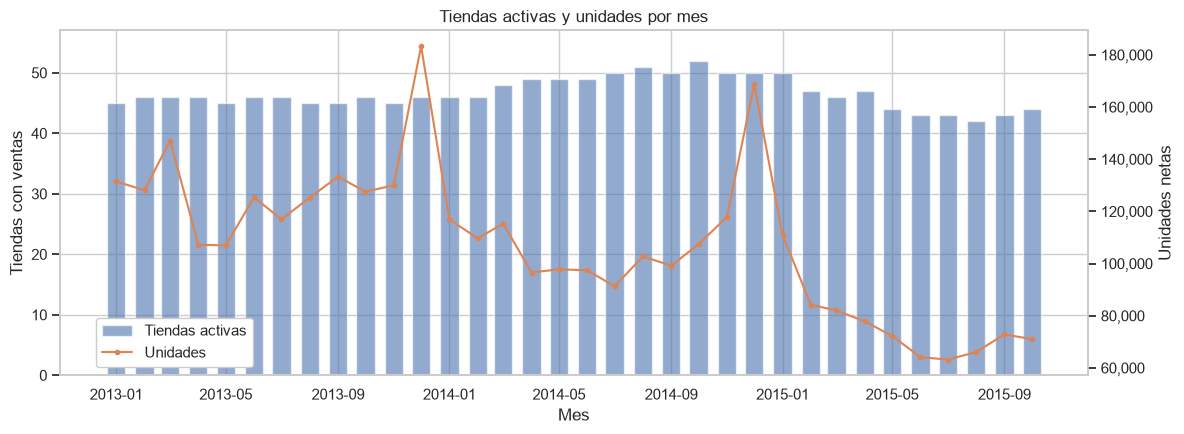

Tiendas activas: 45 en 2013-01, máximo de 52 en 2014-10 y 44 en 2015-10


shop_id,Ciudad,Estado,Primer mes,Último mes,Meses activos,% revenue total
5,Vologda,Abre después del inicio,1,33,33,1.12
55,Online/Otros,Abre después del inicio,4,33,30,1.46
9,Online/Otros,Abre después del inicio,9,33,4,0.48
49,Tyumen,Abre después del inicio,11,33,23,0.59
39,Rostov-na-Donu,Abre después del inicio,14,33,20,0.53
48,Tomsk,Abre después del inicio,15,33,19,0.82
34,Nizhny Novgorod,Abre después del inicio,18,33,16,0.25
20,Moskva,Abre después del inicio,21,33,2,0.19
36,Novosibirsk,Abre después del inicio,33,33,1,0.01
17,Krasnoyarsk,Abre y cierra,5,24,20,0.82


In [44]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(monthly_ts.index, monthly_ts["shops"], width=20, color="C0", alpha=0.6, label="Tiendas activas")
ax1.set_ylabel("Tiendas con ventas")
ax1.set_ylim(0, monthly_ts["shops"].max() + 5)
ax2 = ax1.twinx()
ax2.plot(monthly_ts.index, monthly_ts["units"], color="C1", marker="o", markersize=3, label="Unidades")
ax2.set_ylabel("Unidades netas")
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2.grid(False)
ax1.set_title("Tiendas activas y unidades por mes")
ax1.set_xlabel("Mes")
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.15), framealpha=1)
plt.tight_layout()
plt.show()

shop_life = (
    sales_ts.groupby(["shop_id", "ciudad"], observed=True)
    .agg(first_block=("date_block_num", "min"), last_block=("date_block_num", "max"),
         active_months=("date_block_num", "nunique"), revenue=("revenue", "sum"))
    .reset_index()
)
shop_life["% revenue total"] = shop_life["revenue"] / shop_life["revenue"].sum() * 100
shop_life["Estado"] = np.select(
    [(shop_life["first_block"] > 0) & (shop_life["last_block"] < 33), shop_life["first_block"] > 0,
     shop_life["last_block"] < 33],
    ["Abre y cierra", "Abre después del inicio", "Cierra antes del final"], default="Todo el periodo",
)
partial_shops = shop_life[shop_life["Estado"] != "Todo el periodo"].sort_values(["Estado", "first_block"])
print(f"Tiendas activas: {monthly_ts['shops'].iloc[0]} en {monthly_ts.index[0]:%Y-%m}, máximo de "
      f"{monthly_ts['shops'].max()} en {monthly_ts['shops'].idxmax():%Y-%m} y "
      f"{monthly_ts['shops'].iloc[-1]} en {monthly_ts.index[-1]:%Y-%m}")
style_table(
    partial_shops.rename(columns={"ciudad": "Ciudad", "first_block": "Primer mes", "last_block": "Último mes",
                                  "active_months": "Meses activos"})
    [["shop_id", "Ciudad", "Estado", "Primer mes", "Último mes", "Meses activos", "% revenue total"]],
    {"% revenue total": "{:.2f}"},
)

**Interpretación**

- El número de tiendas activas pasa de 45 (enero de 2013) a un máximo de 52 (octubre de 2014) y baja a entre
  42 y 47 en 2015 (44 en octubre de 2015).
- Las aperturas de finales de 2013 y de 2014 (tiendas 49, 39, 48, 34 y otras) amortiguaron la caída de esos
  meses. Los cierres de
  2015 restan ventas: la tienda **54** (Khimki, 4.18 % del revenue total) deja de vender en abril de 2015 (mes
  27); la **30** (Moskva) en febrero (mes 25); la **29** (Moskva) en mayo (mes 28); y la **43**
  (Sankt-Peterburg) en enero (mes 24).
- Las tiendas **27** (Moskva, 4.14 % del revenue) y **51** (Tyumen) venden por última vez en septiembre de
  2015 (mes 32), sin ventas en octubre. Hay que comprobar si siguen operando antes de pronosticar
  noviembre.
- Las tiendas 9 (venta itinerante) y 20 (Moskva) solo tienen 4 y 2 meses con ventas: son puntos de venta
  esporádicos. La tienda 36 aparece por primera vez en octubre de 2015.
- Los cierres explican parte de la caída de 2015, pero no toda: la serie sigue bajando incluso cuando el
  número de tiendas se estabiliza en torno a 43.

#### 6.b.iv Ciclos

**Día de la semana × mes del año.** Unidades medias por día según el día de la semana y el mes calendario.

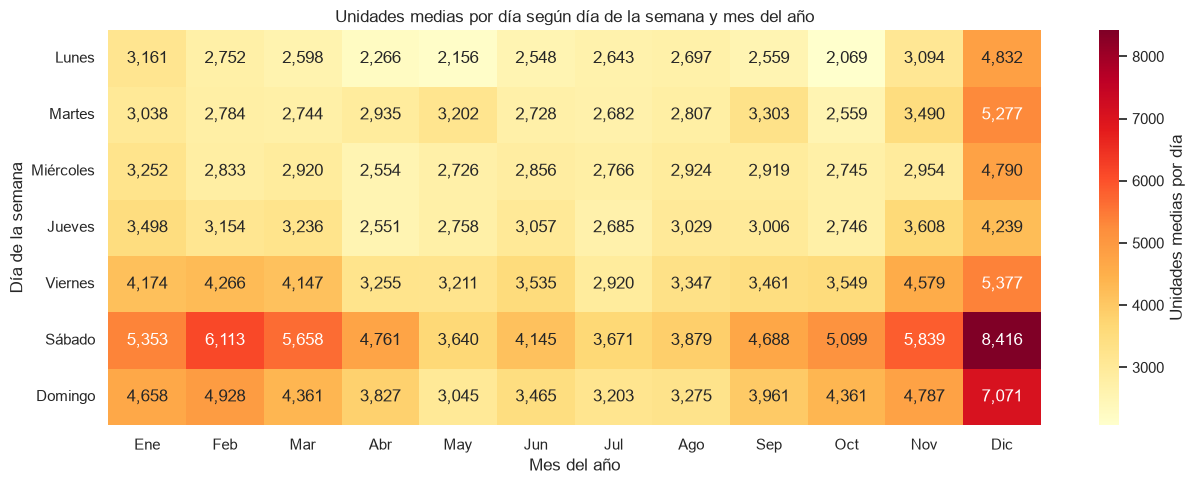

Métrica,Valor
Meses en que el sábado es el día más fuerte,12 de 12
Meses en que el lunes es el día más débil,9 de 12
Celda máxima,"Sábado de Dic (8,416)"
Celda mínima,"Lunes de Oct (2,069)"


In [45]:
daily_ts = sales_ts.groupby("date").agg(units=("item_cnt_day", "sum")).reset_index()
daily_ts["weekday"] = daily_ts["date"].dt.day_of_week
daily_ts["month"] = daily_ts["date"].dt.month
daily_ts["year"] = daily_ts["date"].dt.year

weekday_month = daily_ts.pivot_table(index="weekday", columns="month", values="units", aggfunc="mean")
weekday_month.index = DAY_NAMES
weekday_month.columns = MONTH_NAMES

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(weekday_month, annot=True, fmt=",.0f", cmap="YlOrRd", cbar_kws={"label": "Unidades medias por día"},
            ax=ax)
ax.set_title("Unidades medias por día según día de la semana y mes del año")
ax.set_xlabel("Mes del año")
ax.set_ylabel("Día de la semana")
plt.tight_layout()
plt.show()

weekday_rank = weekday_month.rank(ascending=False)
style_table(
    pd.DataFrame({
        "Métrica": ["Meses en que el sábado es el día más fuerte",
                    "Meses en que el lunes es el día más débil",
                    "Celda máxima", "Celda mínima"],
        "Valor": [f"{(weekday_rank.loc['Sábado'] == 1).sum()} de 12",
                  f"{(weekday_rank.loc['Lunes'] == 7).sum()} de 12",
                  f"{weekday_month.stack().idxmax()[0]} de {weekday_month.stack().idxmax()[1]} "
                  f"({weekday_month.stack().max():,.0f})",
                  f"{weekday_month.stack().idxmin()[0]} de {weekday_month.stack().idxmin()[1]} "
                  f"({weekday_month.stack().min():,.0f})"],
    })
)

**Interpretación**

- El **sábado** es el día más fuerte en los 12 meses del año, y el **lunes** el más débil en 9 de 12. El
  ciclo semanal es independiente del mes.
- Diciembre eleva todos los días de la semana, con la celda máxima en los sábados de diciembre (8,416
  unidades de media). La mínima es el lunes de octubre (2,069).
- Los sábados de febrero (6,113) y marzo (5,658) también destacan, en línea con las fechas de regalos del
  23 de febrero y el 8 de marzo.

**Perfil semanal por año.** Unidades medias de cada día de la semana como índice sobre la media diaria del
año (media = 100), para comparar la forma del ciclo semanal aunque el nivel de ventas cambie.

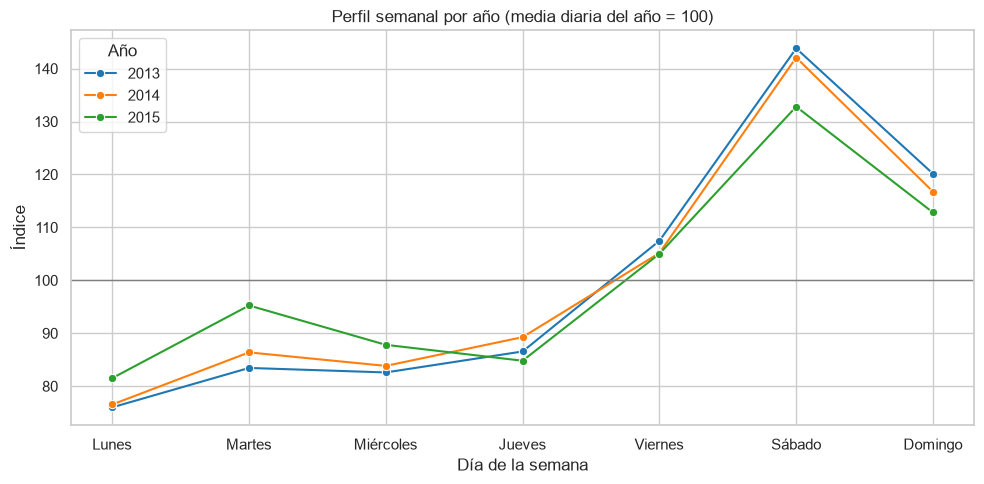

Día,2013,2014,2015
Lunes,76,77,82
Martes,83,86,95
Miércoles,83,84,88
Jueves,87,89,85
Viernes,107,105,105
Sábado,144,142,133
Domingo,120,117,113


In [46]:
weekly_profile = daily_ts.groupby(["year", "weekday"])["units"].mean().reset_index()
weekly_profile["index"] = weekly_profile["units"] / weekly_profile.groupby("year")["units"].transform("mean") * 100
weekly_profile["day"] = weekly_profile["weekday"].map(dict(enumerate(DAY_NAMES)))

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=weekly_profile, x="weekday", y="index", hue="year", marker="o", palette="tab10", ax=ax)
ax.axhline(100, color="grey", linewidth=1)
ax.set_xticks(range(7), DAY_NAMES)
ax.set_title("Perfil semanal por año (media diaria del año = 100)")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Índice")
ax.legend(title="Año")
plt.tight_layout()
plt.show()

profile_table = weekly_profile.pivot(index="day", columns="year", values="index").reindex(DAY_NAMES)
profile_table.columns = profile_table.columns.astype(str)
style_table(profile_table.reset_index(names="Día"), {c: "{:.0f}" for c in profile_table.columns})

**Interpretación**

- La forma del ciclo semanal se mantiene en los tres años: de lunes a jueves por debajo de la media, viernes
  ligeramente por encima (105-107) y un máximo el sábado, seguido del domingo.
- El ciclo se ha suavizado algo: el índice del sábado baja de 144 (2013) a 142 (2014) y a 133 (2015), y el
  del lunes sube de 76 a 82. En 2015 las ventas se reparten más a lo largo de la semana.
- Al agregar por mes, este ciclo apenas influye. Solo cambia ligeramente el total de cada mes según cuántos
  fines de semana contenga.

#### Resumen de la exploración temporal

Patrones que debe considerar el modelo de forecasting de `item_cnt_month` para noviembre de 2015:

1. **Tendencia descendente fuerte y acelerada.** La tendencia cae un 31.3 % entre mediados de 2013 y
   abril de 2015, y las unidades caen frente al año anterior en todos los meses (−26.4 % de media en
   2015). El modelo debe apoyarse en el nivel reciente (los últimos meses) y no en promedios históricos,
   que sobrestimarían las ventas.
2. **Estacionalidad anual con noviembre por encima de la tendencia.** Noviembre está un 9.2 % por encima de
   la tendencia y supera a octubre en los dos años con datos (+1.9 % y +9.7 %). Conviene incluir el mes del
   año y las ventas del mismo mes del año anterior (rezago de 12 meses). Solo hay dos noviembres de
   referencia, así que la estimación del efecto es frágil.
3. **Picos por lanzamientos concretos.** Los picos fuera de diciembre se deben a pocos productos nuevos
   (GTA V, PS4, Watch_Dogs, The Witcher 3), que concentran sus ventas en las primeras semanas. Son útiles
   variables como la antigüedad del producto (meses desde su primera venta) y el comportamiento de
   lanzamientos previos de la misma categoría.
4. **Unidades y revenue divergen.** El precio medio sube mientras el volumen cae. El objetivo son unidades,
   así que el precio puede usarse como variable explicativa, pero el revenue no es un buen sustituto del
   objetivo.
5. **Cambios en la red de tiendas.** Hay aperturas, cierres y tiendas esporádicas. Conviene marcar si una
   tienda está activa y revisar las que no vendieron en octubre de 2015 (27 y 51), porque su pronóstico
   debería ser cercano a cero si cerraron.
6. **Ciclo semanal estable pero diluido al agregar por mes.** El sábado es siempre el día más fuerte, pero
   a nivel mensual su efecto se reduce al número de fines de semana del mes. Noviembre de 2015 tiene
   4 sábados y 5 domingos.
7. **Sin anomalías mensuales que limpiar.** Ningún mes supera ±2σ en el residuo, así que no hace falta
   corregir meses completos. Las anomalías son semanales y se explican por eventos reales (fin de año,
   lanzamientos, ИгроМир).

## 7. Análisis comparativo entre sucursales y productos

#### Preparación

Se cargan las ventas enriquecidas y se definen los diccionarios de traducción de subcategorías y de
descripción en español de los productos que aparecen en las tablas de esta sección.

In [47]:
sales_cmp = load_parquet(ENRICHED_SALES_FILE)

SUBCATEGORY_TRANSLATION = {
    0: "PC - Auriculares", 1: "Accesorios - PS2", 2: "Accesorios - PS3", 3: "Accesorios - PS4",
    4: "Accesorios - PSP", 5: "Accesorios - PS Vita", 6: "Accesorios - Xbox 360", 7: "Accesorios - Xbox One",
    8: "Entradas (digital)", 9: "Envío de productos", 10: "Consolas - PS2", 11: "Consolas - PS3",
    12: "Consolas - PS4", 13: "Consolas - PSP", 14: "Consolas - PS Vita", 15: "Consolas - Xbox 360",
    16: "Consolas - Xbox One", 17: "Consolas - Otras", 18: "Juegos - PS2", 19: "Juegos - PS3",
    20: "Juegos - PS4", 21: "Juegos - PSP", 22: "Juegos - PS Vita", 23: "Juegos - Xbox 360",
    24: "Juegos - Xbox One", 25: "Juegos - Accesorios para juegos", 26: "Juegos Android - Digital",
    27: "Juegos Mac - Digital", 28: "Juegos PC - Ediciones adicionales", 29: "Juegos PC - Ediciones de colección",
    30: "Juegos PC - Ediciones estándar", 31: "Juegos PC - Digital",
    32: "Tarjetas de pago (cine, música, juegos)", 33: "Tarjetas de pago - Live!",
    34: "Tarjetas de pago - Live! (digital)", 35: "Tarjetas de pago - PSN",
    36: "Tarjetas de pago - Windows (digital)", 37: "Cine - Blu-Ray", 38: "Cine - Blu-Ray 3D",
    39: "Cine - Blu-Ray 4K", 40: "Cine - DVD", 41: "Cine - Ediciones de colección",
    42: "Libros - Artbooks y enciclopedias", 43: "Libros - Audiolibros", 44: "Libros - Audiolibros (digital)",
    45: "Libros - Audiolibros 1C", 46: "Libros - Negocios", 47: "Libros - Cómics y manga",
    48: "Libros - Informática", 49: "Libros - Materiales metodológicos 1C", 50: "Libros - Postales",
    51: "Libros - Divulgación", 52: "Libros - Guías de viaje", 53: "Libros - Ficción", 54: "Libros - Digital",
    55: "Música - CD de producción local", 56: "Música - CD de sello", 57: "Música - MP3",
    58: "Música - Vinilo", 59: "Música - Video musical", 60: "Música - Ediciones de regalo",
    61: "Regalos - Merchandising", 62: "Regalos - Gadgets, robots y deporte", 63: "Regalos - Peluches",
    64: "Regalos - Juegos de mesa", 65: "Regalos - Juegos de mesa (compactos)",
    66: "Regalos - Postales y pegatinas", 67: "Regalos - Juguetes educativos",
    68: "Regalos - Certificados y servicios", 69: "Regalos - Recuerdos", 70: "Regalos - Recuerdos (colgantes)",
    71: "Regalos - Bolsas, álbumes y alfombrillas", 72: "Regalos - Figuras",
    73: "Software - 1C:Enterprise 8", 74: "Software - Mac (digital)", 75: "Software - Hogar y oficina",
    76: "Software - Hogar y oficina (digital)", 77: "Software - Educativo", 78: "Software - Educativo (digital)",
    79: "Servicio", 80: "Servicio - Entradas", 81: "Medios vírgenes (granel)", 82: "Medios vírgenes (unidad)",
    83: "Pilas y baterías",
}

ITEM_DESCRIPTIONS = {
    20949: "Bolsa de la tienda 1C Interes", 2808: "Diablo III (PC)", 3731: "GTA V (PC)",
    3732: "GTA V (PS3)", 3733: "GTA V (PS4)", 3734: "GTA V (Xbox 360)",
    17717: "Recepción de pagos 1C-Online (servicio)", 5822: "Tarjeta PlayStation Store 1,000 RUB",
    5823: "Tarjeta PlayStation Store 2,500 RUB", 6675: "Consola PlayStation 4 (500 GB)",
    1855: "Battlefield 4 (PC)", 16787: "The Last of Us (PS3)", 13443: "Pack PS4 (500 GB) + GTA V",
    13405: "Pack Xbox One + FIFA 15 + Forza Motorsport 5", 6066: "Radmin 3, 522 licencias (corporativa)",
    11365: "Envío EMS (servicio)", 13199: "Ajedrez de colección El Señor de los Anillos",
    7241: "UserGate Proxy & Firewall (licencia)", 13403: "Pack Xbox One 1 TB Halo 5 (edición limitada)",
    11373: "Envío a punto de recogida Boxberry (servicio)", 9248: "Entrada ИгроМир 2015 (digital)",
    9249: "Entrada ИгроМир 2015 (digital, UPR)", 9242: "Entrada ИгроМир 2014",
    19437: "Middle-earth: Shadow of Mordor (PC, digital)", 11864: "Serpiente de peluche (36 cm)",
    11865: "Serpiente de peluche antiestrés (33 cm)", 11857: "Serpiente de peluche antiestrés (36 cm)",
    11869: "Serpiente de peluche antiestrés (33 cm)", 20146: "Serpiente de peluche (75 cm)",
    11872: "Serpiente de peluche (23 cm)", 11859: "Serpiente de peluche con flor (33 cm)",
    11855: "Serpiente de peluche (33 cm)", 1836: "Battlefield 3 Premium Edition (PS3)",
    1837: "Battlefield 3 Premium Edition (Xbox 360)", 7019: "Titanfall (Xbox 360)",
    1850: "Battlefield 4 Limited Edition (PS3)", 1851: "Battlefield 4 Limited Edition (Xbox 360)",
    1856: "Battlefield 4 (PS3)", 11858: "Serpiente de peluche con flor (22 cm)",
}

item_names = items.set_index("item_id")["item_name"]
category_names = item_categories.set_index("item_category_id")["item_category_name"]


def describe_item(item_id: int) -> str:
    return ITEM_DESCRIPTIONS.get(int(item_id), "—")


print(f"Registros: {len(sales_cmp):,} | Subcategorías traducidas: {len(SUBCATEGORY_TRANSLATION)} de "
      f"{len(item_categories)}")

Registros: 2,935,843 | Subcategorías traducidas: 84 de 84


### 7.a Productos y categorías más y menos vendidos

**Top 10 de productos por unidades y por revenue**, con el nombre original y una descripción en español.

In [48]:
item_totals = (
    sales_cmp.groupby(["item_id", "categoria_principal"], observed=True)
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"),
         months=("date_block_num", "nunique"), shops=("shop_id", "nunique"))
    .reset_index()
)


def top_items_table(metric: str) -> pd.DataFrame:
    top = item_totals.nlargest(10, metric).copy()
    top.insert(0, "Puesto", range(1, 11))
    top["Nombre original"] = top["item_id"].map(item_names).str[:60]
    top["Descripción"] = top["item_id"].map(describe_item)
    top["Revenue (M RUB)"] = top["revenue"] / 1e6
    return top.rename(columns={"units": "Unidades"})[
        ["Puesto", "item_id", "Nombre original", "Descripción", "categoria_principal", "Unidades",
         "Revenue (M RUB)"]
    ]


print("Top 10 por unidades")
display(style_table(top_items_table("units"), {"Revenue (M RUB)": "{:,.2f}"}))
print("Top 10 por revenue")
style_table(top_items_table("revenue"), {"Revenue (M RUB)": "{:,.2f}"})

Top 10 por unidades


Puesto,item_id,Nombre original,Descripción,categoria_principal,Unidades,Revenue (M RUB)
1,20949,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,Bolsa de la tienda 1C Interes,Regalos,"187,642",0.93
2,2808,"Diablo III [PC, Jewel, русская версия]",Diablo III (PC),Videojuegos,"17,245",16.85
3,3732,"Grand Theft Auto V [PS3, русские субтитры]",GTA V (PS3),Videojuegos,"16,642",43.62
4,17717,Прием денежных средств для 1С-Онлайн,Recepción de pagos 1C-Online (servicio),Otros,"15,830",17.20
5,5822,Playstation Store пополнение бумажника: Карта оплаты 1000 ру,"Tarjeta PlayStation Store 1,000 RUB",Tarjetas de pago,"14,515",15.41
6,3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",GTA V (Xbox 360),Videojuegos,"11,688",31.07
7,6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),Consola PlayStation 4 (500 GB),Consolas,"10,289",219.39
8,3731,"Grand Theft Auto V [PC, русские субтитры]",GTA V (PC),Videojuegos,"10,099",19.98
9,1855,"Battlefield 4 [PC, русская версия]",Battlefield 4 (PC),Videojuegos,"10,032",9.36
10,16787,"Одни из нас [PS3, русская версия]",The Last of Us (PS3),Videojuegos,"9,227",21.91


Top 10 por revenue


Puesto,item_id,Nombre original,Descripción,categoria_principal,Unidades,Revenue (M RUB)
1,6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),Consola PlayStation 4 (500 GB),Consolas,"10,289",219.39
2,3732,"Grand Theft Auto V [PS3, русские субтитры]",GTA V (PS3),Videojuegos,"16,642",43.62
3,13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B01) + игра Gran,Pack PS4 (500 GB) + GTA V,Consolas,"1,366",34.33
4,3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",GTA V (Xbox 360),Videojuegos,"11,688",31.07
5,3733,"Grand Theft Auto V [PS4, русские субтитры]",GTA V (PS4),Videojuegos,"6,506",22.30
6,16787,"Одни из нас [PS3, русская версия]",The Last of Us (PS3),Videojuegos,"9,227",21.91
7,3731,"Grand Theft Auto V [PC, русские субтитры]",GTA V (PC),Videojuegos,"10,099",19.98
8,13405,"Комплект ""Microsoft Xbox One 500GB (Day One Edition Green Bo",Pack Xbox One + FIFA 15 + Forza Motorsport 5,Consolas,991,18.13
9,17717,Прием денежных средств для 1С-Онлайн,Recepción de pagos 1C-Online (servicio),Otros,"15,830",17.20
10,5823,Playstation Store пополнение бумажника: Карта оплаты 2500 ру,"Tarjeta PlayStation Store 2,500 RUB",Tarjetas de pago,"6,523",17.15


**Interpretación**

- **Por unidades** domina la bolsa de la tienda (187,642 unidades, más de diez veces el segundo producto),
  pero solo aporta 0.93 M RUB. Del resto, la mayoría son videojuegos de gran éxito: tres versiones de
  *GTA V*, *Diablo III*, *Battlefield 4* y *The Last of Us*. También entran dos artículos que no son producto
  físico: la recepción de pagos de 1C-Online y la tarjeta de PlayStation Store de 1,000 RUB.
- **Por revenue** lidera con mucha ventaja la **consola PlayStation 4**: 219.39 M RUB con 10,289 unidades,
  cinco veces más que el segundo. *GTA V* aparece en sus cuatro versiones (PS3, Xbox 360, PS4 y PC) y en
  el pack PS4 + GTA V, de modo que la franquicia ocupa 5 de los 10 primeros puestos.
- Solo 6 productos están en ambos rankings: GTA V (PS3, Xbox 360 y PC), la PS4, *The Last of Us* y el
  servicio de pagos 1C-Online. Volumen e ingresos dependen en buena parte de productos distintos.

**Productos menos vendidos.** En lugar de un bottom 10 (cientos de productos empatan con una unidad), se
agrupan los productos por total de unidades netas, se compara su distribución por categoría con la del
catálogo vendido y se cuenta cuántos vendieron en un único mes.

In [49]:
item_totals["Tramo"] = pd.cut(item_totals["units"], bins=[-np.inf, 0, 1, 5, 10, np.inf],
                              labels=["≤ 0", "1", "2–5", "6–10", "> 10"])
low_sellers = item_totals[item_totals["Tramo"].isin(["1", "2–5", "6–10"])]

tier_summary = (
    item_totals.groupby("Tramo", observed=True)
    .agg(products=("item_id", "size"), single_month=("months", lambda m: (m == 1).sum()),
         units=("units", "sum"))
    .reset_index()
)
tier_summary["% de productos"] = tier_summary["products"] / len(item_totals) * 100
tier_summary["% con un único mes"] = tier_summary["single_month"] / tier_summary["products"] * 100
tier_summary["% de las unidades"] = tier_summary["units"] / item_totals["units"].sum() * 100
display(style_table(
    tier_summary.rename(columns={"Tramo": "Unidades totales", "products": "Productos",
                                 "single_month": "Con un único mes"})
    [["Unidades totales", "Productos", "% de productos", "Con un único mes", "% con un único mes",
      "% de las unidades"]],
    {"% de productos": "{:.1f}", "% con un único mes": "{:.1f}", "% de las unidades": "{:.2f}"},
))

low_by_category = pd.DataFrame({
    "Productos con ≤ 10 unidades": low_sellers["categoria_principal"].value_counts(),
    "Total de productos": item_totals["categoria_principal"].value_counts(),
}).fillna(0).astype(int)
low_by_category["% del grupo ≤ 10"] = (
    low_by_category["Productos con ≤ 10 unidades"] / low_by_category["Productos con ≤ 10 unidades"].sum() * 100
)
low_by_category["% del catálogo"] = (
    low_by_category["Total de productos"] / low_by_category["Total de productos"].sum() * 100
)
low_by_category["% de la categoría con ≤ 10"] = (
    low_by_category["Productos con ≤ 10 unidades"] / low_by_category["Total de productos"] * 100
)
low_by_category = low_by_category.sort_values("Productos con ≤ 10 unidades", ascending=False)
style_table(
    low_by_category.reset_index(names="categoria_principal"),
    {c: "{:.1f}" for c in ["% del grupo ≤ 10", "% del catálogo", "% de la categoría con ≤ 10"]},
)

Unidades totales,Productos,% de productos,Con un único mes,% con un único mes,% de las unidades
≤ 0,8,0.0,6,75.0,-0.00
1,"2,319",10.6,"2,311",99.7,0.06
2–5,"2,688",12.3,426,15.8,0.23
6–10,"1,694",7.8,85,5.0,0.36
> 10,"15,098",69.2,171,1.1,99.34


categoria_principal,Productos con ≤ 10 unidades,Total de productos,% del grupo ≤ 10,% del catálogo,% de la categoría con ≤ 10
Cine,"1,454","7,390",21.7,33.9,19.7
Música,"1,338","4,259",20.0,19.5,31.4
Regalos,"1,323","3,461",19.7,15.9,38.2
Videojuegos,"1,244","3,871",18.6,17.8,32.1
Software,768,"1,134",11.5,5.2,67.7
Libros,478,"1,229",7.1,5.6,38.9
Accesorios,44,220,0.7,1.0,20.0
Consolas,28,144,0.4,0.7,19.4
Otros,19,58,0.3,0.3,32.8
Tarjetas de pago,5,41,0.1,0.2,12.2


**Interpretación**

- El 30.7 % de los productos vende 10 unidades o menos en todo el periodo: 2,319 venden una sola unidad
  (10.6 %), 2,688 entre 2 y 5 (12.3 %) y 1,694 entre 6 y 10 (7.8 %). Juntos solo suman el 0.65 % de las
  unidades.
- Casi todos los productos de una unidad (99.7 %) venden en un único mes, frente al 15.8 % en el tramo de 2
  a 5 unidades. En total, 2,999 productos (13.8 %) aparecen en un solo mes. Para el modelo son prácticamente
  invisibles: no tienen historial con el que estimar su demanda.
- Por categoría, **Software** es la más afectada: el 67.7 % de sus productos vende 10 unidades o menos, y
  pesa el 11.5 % de este grupo frente al 5.2 % del catálogo. Le siguen Libros (38.9 %) y Regalos (38.2 %).
- **Cine** es la categoría con más productos de baja venta en número (1,454), pero está infrarrepresentada
  respecto a su peso en el catálogo (21.7 % frente a 33.9 %).

**Ranking de categorías principales** por unidades y revenue.

In [50]:
main_ranking = (
    sales_cmp.groupby("categoria_principal", observed=True)
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"), products=("item_id", "nunique"))
    .reset_index()
)
main_ranking["% unidades"] = main_ranking["units"] / main_ranking["units"].sum() * 100
main_ranking["% revenue"] = main_ranking["revenue"] / main_ranking["revenue"].sum() * 100
main_ranking["Puesto unidades"] = main_ranking["units"].rank(ascending=False).astype(int)
main_ranking["Puesto revenue"] = main_ranking["revenue"].rank(ascending=False).astype(int)
main_ranking["revenue"] = main_ranking["revenue"] / 1e6
main_ranking = main_ranking.sort_values("Puesto unidades")

style_table(
    main_ranking.rename(columns={"units": "Unidades", "revenue": "Revenue (M RUB)", "products": "Productos"})
    [["categoria_principal", "Puesto unidades", "Unidades", "% unidades", "Puesto revenue",
      "Revenue (M RUB)", "% revenue", "Productos"]],
    {"% unidades": "{:.1f}", "% revenue": "{:.1f}", "Revenue (M RUB)": "{:,.1f}"},
)

categoria_principal,Puesto unidades,Unidades,% unidades,Puesto revenue,Revenue (M RUB),% revenue,Productos
Videojuegos,1,"1,335,990",36.6,1,"1,631.8",48.0,"3,871"
Cine,2,"916,941",25.1,3,335.0,9.9,"7,390"
Regalos,3,"584,366",16.0,4,309.1,9.1,"3,461"
Música,4,"411,294",11.3,6,149.7,4.4,"4,259"
Accesorios,5,"85,059",2.3,5,166.4,4.9,220
Otros,6,"77,217",2.1,9,53.1,1.6,58
Libros,7,"76,341",2.1,10,30.3,0.9,"1,229"
Software,8,"74,954",2.1,7,122.4,3.6,"1,134"
Tarjetas de pago,9,"53,883",1.5,8,73.0,2.1,41
Consolas,10,"32,155",0.9,2,528.0,15.5,144


**Interpretación**

- Videojuegos es la primera categoría en unidades y en revenue.
- Las mayores diferencias entre ambos rankings son **Consolas**, última en unidades (0.9 %) pero segunda en
  revenue (15.5 %), y **Cine**, segunda en unidades (25.1 %) pero tercera en revenue (9.9 %).
- Música (4.º en unidades, 6.º en revenue), Libros (7.º y 10.º) y Otros (6.º y 9.º) venden volumen a precios
  bajos. Software y Tarjetas de pago tienen tickets más altos y mejoran en revenue.
- Cine tiene el catálogo más amplio (7,390 productos), pero con menos ventas por producto. Tarjetas de pago
  concentra 53,883 unidades en solo 41 productos.

**Ranking de subcategorías.** Las 15 subcategorías (`item_category_name`, con traducción) con más y menos
unidades y revenue.

In [51]:
subcategory_ranking = (
    sales_cmp.groupby(["item_category_id", "categoria_principal"], observed=True)
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"))
    .reset_index()
)
subcategory_ranking["Subcategoría"] = subcategory_ranking["item_category_id"].map(category_names)
subcategory_ranking["Traducción"] = subcategory_ranking["item_category_id"].map(SUBCATEGORY_TRANSLATION)
subcategory_ranking["% unidades"] = subcategory_ranking["units"] / subcategory_ranking["units"].sum() * 100
subcategory_ranking["% revenue"] = subcategory_ranking["revenue"] / subcategory_ranking["revenue"].sum() * 100
subcategory_ranking["Puesto unidades"] = subcategory_ranking["units"].rank(ascending=False, method="min").astype(int)
subcategory_ranking["Puesto revenue"] = subcategory_ranking["revenue"].rank(ascending=False, method="min").astype(int)
subcategory_ranking["Revenue (M RUB)"] = subcategory_ranking["revenue"] / 1e6
subcategory_ranking = subcategory_ranking.rename(columns={"units": "Unidades"})

SUBCAT_COLUMNS = ["item_category_id", "Subcategoría", "Traducción", "Unidades", "% unidades",
                  "Puesto unidades", "Revenue (M RUB)", "% revenue", "Puesto revenue"]
SUBCAT_FORMATS = {"% unidades": "{:.2f}", "% revenue": "{:.2f}", "Revenue (M RUB)": "{:,.2f}"}
print(f"Subcategorías con ventas: {len(subcategory_ranking)}")
for title, frame in [
    ("15 subcategorías con más unidades", subcategory_ranking.nlargest(15, "Unidades")),
    ("15 subcategorías con más revenue", subcategory_ranking.nlargest(15, "revenue")),
    ("15 subcategorías con menos unidades", subcategory_ranking.nsmallest(15, "Unidades")),
    ("15 subcategorías con menos revenue", subcategory_ranking.nsmallest(15, "revenue")),
]:
    print(title)
    display(style_table(frame[SUBCAT_COLUMNS], SUBCAT_FORMATS))

Subcategorías con ventas: 84
15 subcategorías con más unidades


item_category_id,Subcategoría,Traducción,Unidades,% unidades,Puesto unidades,Revenue (M RUB),% revenue,Puesto revenue
40,Кино - DVD,Cine - DVD,"634,170",17.38,1,169.94,5.00,6
30,Игры PC - Стандартные издания,Juegos PC - Ediciones estándar,"456,540",12.51,2,257.52,7.58,5
55,Музыка - CD локального производства,Música - CD de producción local,"348,591",9.56,3,100.02,2.94,8
19,Игры - PS3,Juegos - PS3,"254,887",6.99,4,412.05,12.12,1
37,Кино - Blu-Ray,Cine - Blu-Ray,"203,283",5.57,5,90.48,2.66,9
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","Regalos - Bolsas, álbumes y alfombrillas","187,998",5.15,6,0.93,0.03,61
28,Игры PC - Дополнительные издания,Juegos PC - Ediciones adicionales,"174,954",4.80,7,136.42,4.01,7
23,Игры - XBOX 360,Juegos - Xbox 360,"169,940",4.66,8,259.62,7.64,4
20,Игры - PS4,Juegos - PS4,"127,319",3.49,9,373.01,10.97,2
65,Подарки - Настольные игры (компактные),Regalos - Juegos de mesa (compactos),"73,077",2.00,10,24.73,0.73,31


15 subcategorías con más revenue


item_category_id,Subcategoría,Traducción,Unidades,% unidades,Puesto unidades,Revenue (M RUB),% revenue,Puesto revenue
19,Игры - PS3,Juegos - PS3,"254,887",6.99,4,412.05,12.12,1
20,Игры - PS4,Juegos - PS4,"127,319",3.49,9,373.01,10.97,2
12,Игровые консоли - PS4,Consolas - PS4,"13,230",0.36,40,292.24,8.60,3
23,Игры - XBOX 360,Juegos - Xbox 360,"169,940",4.66,8,259.62,7.64,4
30,Игры PC - Стандартные издания,Juegos PC - Ediciones estándar,"456,540",12.51,2,257.52,7.58,5
40,Кино - DVD,Cine - DVD,"634,170",17.38,1,169.94,5.00,6
28,Игры PC - Дополнительные издания,Juegos PC - Ediciones adicionales,"174,954",4.80,7,136.42,4.01,7
55,Музыка - CD локального производства,Música - CD de producción local,"348,591",9.56,3,100.02,2.94,8
37,Кино - Blu-Ray,Cine - Blu-Ray,"203,283",5.57,5,90.48,2.66,9
75,Программы - Для дома и офиса,Software - Hogar y oficina,"48,224",1.32,13,87.09,2.56,10


15 subcategorías con menos unidades


item_category_id,Subcategoría,Traducción,Unidades,% unidades,Puesto unidades,Revenue (M RUB),% revenue,Puesto revenue
10,Игровые консоли - PS2,Consolas - PS2,1,0.00,83,0.00,0.00,77
51,Книги - Познавательная литература,Libros - Divulgación,1,0.00,83,0.00,0.00,83
1,Аксессуары - PS2,Accesorios - PS2,2,0.00,82,0.00,0.00,80
0,PC - Гарнитуры/Наушники,PC - Auriculares,3,0.00,78,0.00,0.00,82
50,Книги - Открытки,Libros - Postales,3,0.00,78,0.00,0.00,84
52,Книги - Путеводители,Libros - Guías de viaje,3,0.00,78,0.00,0.00,81
53,Книги - Художественная литература,Libros - Ficción,3,0.00,78,0.00,0.00,79
48,Книги - Компьютерная литература,Libros - Informática,6,0.00,77,0.00,0.00,78
27,Игры MAC - Цифра,Juegos Mac - Digital,8,0.00,76,0.01,0.00,74
18,Игры - PS2,Juegos - PS2,11,0.00,75,0.00,0.00,76


15 subcategorías con menos revenue


item_category_id,Subcategoría,Traducción,Unidades,% unidades,Puesto unidades,Revenue (M RUB),% revenue,Puesto revenue
50,Книги - Открытки,Libros - Postales,3,0.00,78,0.00,0.00,84
51,Книги - Познавательная литература,Libros - Divulgación,1,0.00,83,0.00,0.00,83
0,PC - Гарнитуры/Наушники,PC - Auriculares,3,0.00,78,0.00,0.00,82
52,Книги - Путеводители,Libros - Guías de viaje,3,0.00,78,0.00,0.00,81
1,Аксессуары - PS2,Accesorios - PS2,2,0.00,82,0.00,0.00,80
53,Книги - Художественная литература,Libros - Ficción,3,0.00,78,0.00,0.00,79
48,Книги - Компьютерная литература,Libros - Informática,6,0.00,77,0.00,0.00,78
10,Игровые консоли - PS2,Consolas - PS2,1,0.00,83,0.00,0.00,77
18,Игры - PS2,Juegos - PS2,11,0.00,75,0.00,0.00,76
46,Книги - Бизнес литература,Libros - Negocios,15,0.00,74,0.00,0.00,75


**Interpretación**

- **Por unidades** lideran los formatos físicos baratos: DVD (17.38 %), juegos de PC en edición estándar
  (12.51 %) y CD de música local (9.56 %). La subcategoría de bolsas (71) es la 6.ª en unidades por la bolsa
  de la tienda, pero solo la 61.ª en revenue.
- **Por revenue** lideran los videojuegos de consola: Juegos PS3 (412.05 M RUB, 12.12 %), Juegos PS4 (10.97 %)
  y Consolas PS4 (8.60 %). Consolas PS4 es la 40.ª subcategoría en unidades (13,230), pero la 3.ª en
  revenue.
- **Las que menos venden** son las de formatos obsoletos (PS2: consolas, accesorios y juegos, con 1 a 11
  unidades), varias de libros (divulgación, postales, guías, ficción, informática y negocios, con menos de
  16 unidades) y las digitales de nicho (Mac, tarjetas de Windows y Android). Los rankings por menos
  unidades y menos revenue casi coinciden.
- Estas subcategorías marginales aportan muy pocas observaciones. En el modelado conviene apoyarse en la
  categoría principal o agruparlas.

### 7.b Desempeño entre sucursales

Ranking de tiendas por revenue con sus principales indicadores. El ticket medio es el revenue por unidad
vendida, y la variación enero–octubre compara 2015 con 2014 en unidades y revenue.

In [52]:
sales_cmp["year"] = sales_cmp["date"].dt.year
jan_oct = sales_cmp[sales_cmp["date"].dt.month <= 10]
jan_oct_by_shop = jan_oct.pivot_table(index="shop_id", columns="year", values=["item_cnt_day", "revenue"],
                                      aggfunc="sum", observed=True)

shop_performance = (
    sales_cmp.groupby(["shop_id", "ciudad", "tipo_tienda"], observed=True)
    .agg(units=("item_cnt_day", "sum"), revenue=("revenue", "sum"),
         active_months=("date_block_num", "nunique"), products=("item_id", "nunique"),
         last_block=("date_block_num", "max"))
    .reset_index()
)
shop_performance["Ticket medio (RUB)"] = shop_performance["revenue"] / shop_performance["units"]
shop_performance["Var. unidades ene–oct 15/14 (%)"] = shop_performance["shop_id"].map(
    (jan_oct_by_shop[("item_cnt_day", 2015)] / jan_oct_by_shop[("item_cnt_day", 2014)] - 1) * 100
)
shop_performance["Var. revenue ene–oct 15/14 (%)"] = shop_performance["shop_id"].map(
    (jan_oct_by_shop[("revenue", 2015)] / jan_oct_by_shop[("revenue", 2014)] - 1) * 100
)
shop_performance["Vende en oct-2015"] = np.where(shop_performance["last_block"] == 33, "Sí", "No")
shop_performance["En test.csv"] = np.where(shop_performance["shop_id"].isin(test["shop_id"]), "Sí", "No")
shop_performance["Revenue mensual medio (M RUB)"] = (
    shop_performance["revenue"] / shop_performance["active_months"] / 1e6
)
shop_performance["Unidades por mes"] = shop_performance["units"] / shop_performance["active_months"]
shop_performance = shop_performance.sort_values("revenue", ascending=False)
shop_performance.insert(0, "Puesto", range(1, len(shop_performance) + 1))
shop_performance["Revenue (M RUB)"] = shop_performance["revenue"] / 1e6

style_table(
    shop_performance.rename(columns={"ciudad": "Ciudad", "tipo_tienda": "Tipo", "units": "Unidades",
                                     "active_months": "Meses activos", "products": "Productos distintos"})
    [["Puesto", "shop_id", "Ciudad", "Tipo", "Unidades", "Revenue (M RUB)", "Ticket medio (RUB)",
      "Meses activos", "Productos distintos", "Var. unidades ene–oct 15/14 (%)",
      "Var. revenue ene–oct 15/14 (%)", "Vende en oct-2015", "En test.csv"]],
    {"Revenue (M RUB)": "{:,.1f}", "Ticket medio (RUB)": "{:,.0f}",
     "Var. unidades ene–oct 15/14 (%)": "{:+.1f}", "Var. revenue ene–oct 15/14 (%)": "{:+.1f}"},
)

Puesto,shop_id,Ciudad,Tipo,Unidades,Revenue (M RUB),Ticket medio (RUB),Meses activos,Productos distintos,Var. unidades ene–oct 15/14 (%),Var. revenue ene–oct 15/14 (%),Vende en oct-2015,En test.csv
1,31,Moskva,Física,"310,777",235.2,757,34,"14,416",-21.5,-7.1,Sí,Sí
2,25,Moskva,Física,"241,919",216.5,895,34,"15,367",-9.8,+9.9,Sí,Sí
3,28,Moskva,Física,"184,557",159.7,866,34,"12,572",-24.5,-5.8,Sí,Sí
4,42,Sankt-Peterburg,Física,"144,933",151.9,"1,048",34,"12,034",+8.1,+33.3,Sí,Sí
5,54,Khimki,Física,"185,789",141.9,764,28,"13,863",-73.9,-67.6,No,No
6,27,Moskva,Física,"136,657",140.6,"1,029",32,"10,842",-39.5,-32.3,No,No
7,57,Yakutsk,Física,"152,812",119.6,783,34,"12,815",-33.4,-24.9,Sí,Sí
8,12,Online/Otros,Online/Otros,"73,478",112.2,"1,527",34,"7,382",+53.5,+18.7,Sí,Sí
9,6,Voronezh,Física,"100,489",98.1,976,34,"11,856",-34.2,-18.2,Sí,Sí
10,18,Krasnoyarsk,Física,"65,486",83.4,"1,273",34,"9,073",-14.2,-15.6,Sí,Sí


**Interpretación**

- Las cuatro tiendas líderes son tres de Moscú (31, 25 y 28) y una de San Petersburgo (42), todas activas
  los 34 meses y presentes en `test.csv`. Les siguen la tienda 54 (Khimki) y la 27 (Moskva), que cerraron
  antes de octubre de 2015 y no están en `test.csv`.
- La caída de 2015 es generalizada: 44 de las 52 tiendas con datos en ambos periodos venden menos unidades
  de enero a octubre de 2015 que en 2014. Las excepciones son los canales online, que crecen con fuerza (la
  12, +53.5 % en unidades, y la 55, +88.9 %), San Petersburgo 42 (+8.1 % en unidades y +33.3 % en revenue) y
  tiendas abiertas entre finales de 2013 y 2014 que aún maduraban (34, 39, 48 y 49).
- El ticket medio va de 304 RUB (la 13, Kazan) a 1,527 RUB (la 12, online). Entre las ventas de la tienda
  online están las licencias de software y los envíos más caros detectados en 7.c.
- **Las 13 tiendas sin ventas en octubre de 2015 no están en `test.csv`**, así que `test.csv` solo incluye
  tiendas activas. Las tiendas 9 y 20 sí vendieron en octubre de 2015, pero tampoco están en `test.csv`.

**Revenue mensual medio por tienda.** Se divide el revenue de cada tienda entre sus meses activos para no
penalizar a las que estuvieron abiertas menos tiempo.

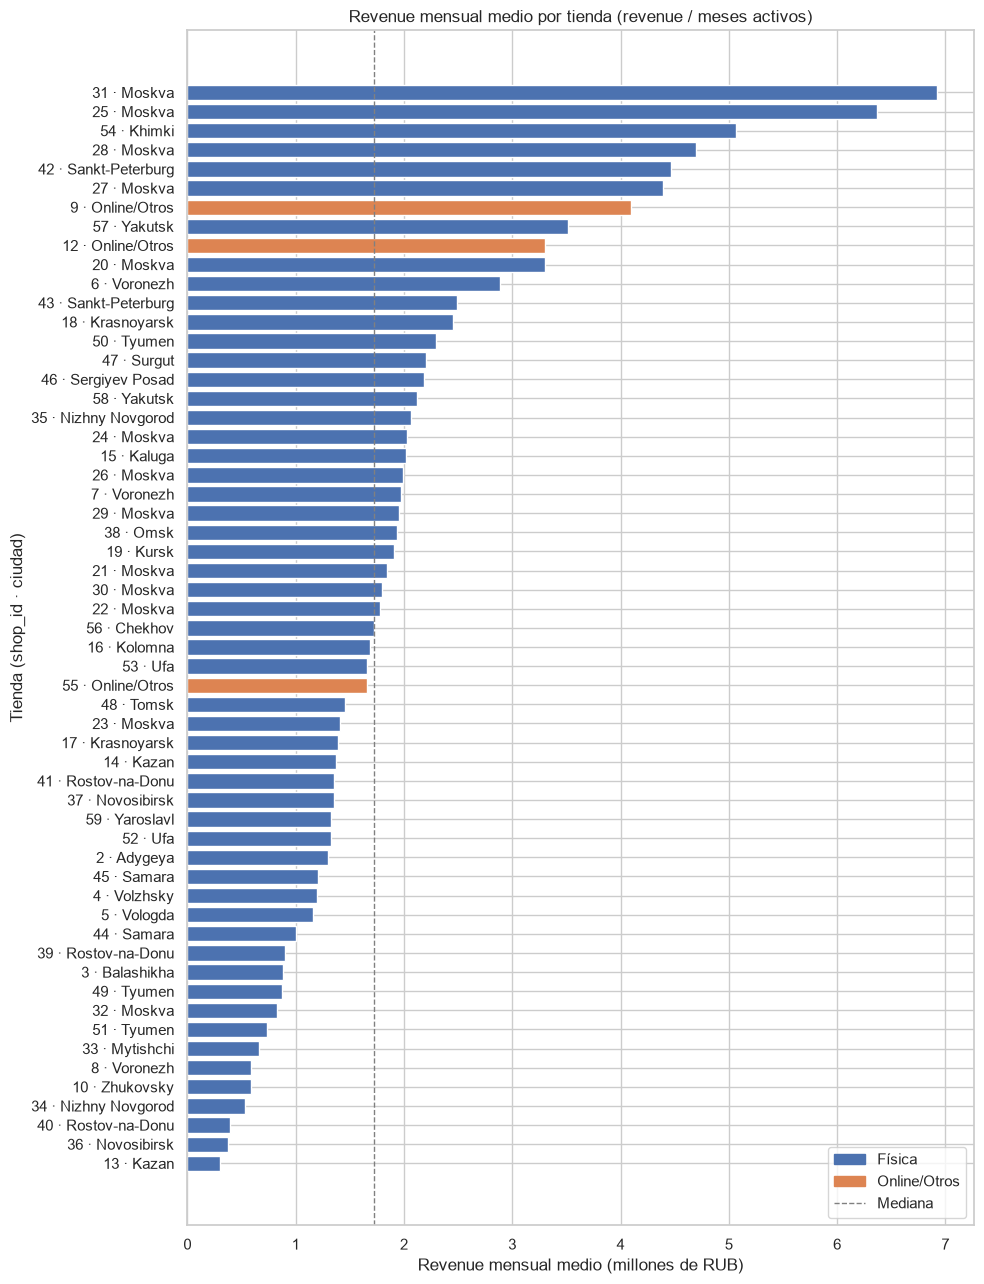

Métrica,Revenue mensual medio (M RUB)
Mediana,1.72
Máximo,6.92
Mínimo,0.30
Máximo / mediana,4.01


In [53]:
TYPE_COLORS = {"Física": "C0", "Online/Otros": "C1"}
monthly_rank = shop_performance.sort_values("Revenue mensual medio (M RUB)", ascending=True)

fig, ax = plt.subplots(figsize=(10, 13))
ax.barh(monthly_rank["shop_id"].astype(str) + " · " + monthly_rank["ciudad"].astype(str),
        monthly_rank["Revenue mensual medio (M RUB)"],
        color=monthly_rank["tipo_tienda"].map(TYPE_COLORS))
ax.axvline(monthly_rank["Revenue mensual medio (M RUB)"].median(), color="grey", linestyle="--",
           linewidth=1, label="Mediana")
ax.set_title("Revenue mensual medio por tienda (revenue / meses activos)")
ax.set_xlabel("Revenue mensual medio (millones de RUB)")
ax.set_ylabel("Tienda (shop_id · ciudad)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TYPE_COLORS.values()]
ax.legend(handles + [ax.get_lines()[0]], list(TYPE_COLORS) + ["Mediana"], loc="lower right")
plt.tight_layout()
plt.show()

style_table(
    pd.DataFrame({
        "Métrica": ["Mediana", "Máximo", "Mínimo", "Máximo / mediana"],
        "Revenue mensual medio (M RUB)": [
            monthly_rank["Revenue mensual medio (M RUB)"].median(),
            monthly_rank["Revenue mensual medio (M RUB)"].max(),
            monthly_rank["Revenue mensual medio (M RUB)"].min(),
            monthly_rank["Revenue mensual medio (M RUB)"].max()
            / monthly_rank["Revenue mensual medio (M RUB)"].median(),
        ],
    }),
    {"Revenue mensual medio (M RUB)": "{:,.2f}"},
)

**Interpretación**

- Medida por mes activo, la mediana es de 1.72 M RUB. La tienda 31 lidera con 6.92 M RUB, unas 4 veces la
  mediana, seguida de la 25 (Moskva) y la 54 (Khimki).
- Este indicador eleva a tiendas que en los totales parecían pequeñas. La 9 (venta itinerante, 4.09 M RUB) y
  la 20 (liquidación en Moskva, 3.30 M RUB) solo operan en meses de evento, de modo que su media por mes
  activo refleja picos y no actividad regular.
- Al final del ranking quedan tiendas con pocos meses o recién abiertas: la 36 (solo octubre de 2015), la 34
  y la 40. También la 13 (Kazan), con el mínimo (0.30 M RUB al mes) y el ticket más bajo.
- La tienda 55 (almacén digital) queda por debajo de la mediana en revenue mensual, aunque crece con fuerza
  en 2015.

**Ticket medio frente a unidades por mes.** Cada punto es una tienda; se etiquetan las más alejadas del
resto.

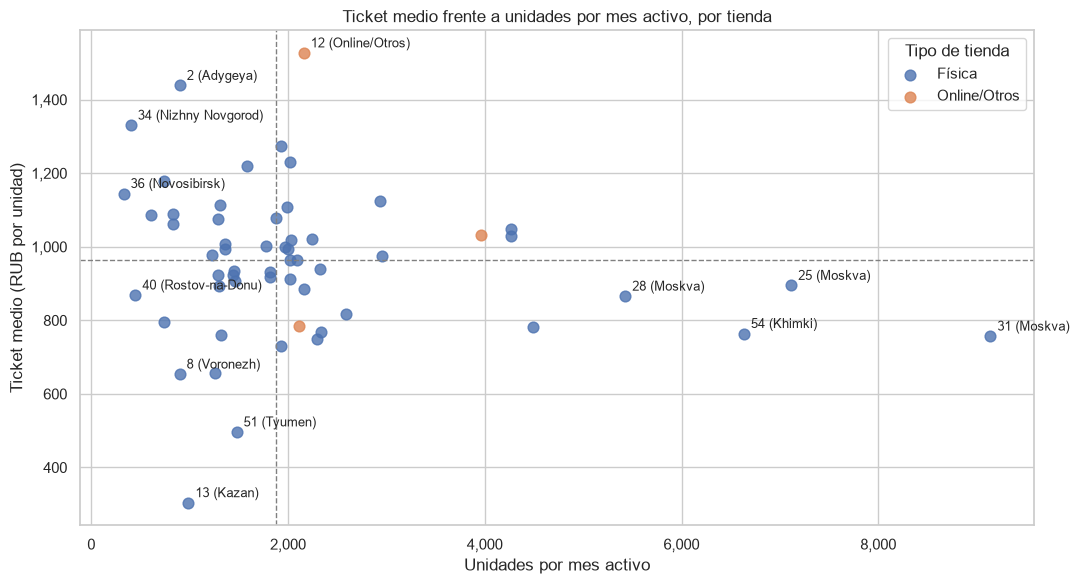

Mediana del ticket medio: 965 RUB | Mediana de unidades por mes: 1,879 | Correlación de Spearman: -0.18


In [54]:
fig, ax = plt.subplots(figsize=(11, 6))
for shop_type, group in shop_performance.groupby("tipo_tienda", observed=True):
    ax.scatter(group["Unidades por mes"], group["Ticket medio (RUB)"], s=60, alpha=0.8,
               color=TYPE_COLORS[shop_type], label=shop_type)
ticket_median = shop_performance["Ticket medio (RUB)"].median()
units_median = shop_performance["Unidades por mes"].median()
ax.axhline(ticket_median, color="grey", linestyle="--", linewidth=1)
ax.axvline(units_median, color="grey", linestyle="--", linewidth=1)
to_label = pd.concat([
    shop_performance.nlargest(4, "Unidades por mes"), shop_performance.nlargest(3, "Ticket medio (RUB)"),
    shop_performance.nsmallest(3, "Ticket medio (RUB)"), shop_performance.nsmallest(3, "Unidades por mes"),
]).drop_duplicates("shop_id")
for _, row in to_label.iterrows():
    ax.annotate(f"{row['shop_id']} ({row['ciudad']})", (row["Unidades por mes"], row["Ticket medio (RUB)"]),
                textcoords="offset points", xytext=(5, 4), fontsize=9)
ax.set_title("Ticket medio frente a unidades por mes activo, por tienda")
ax.set_xlabel("Unidades por mes activo")
ax.set_ylabel("Ticket medio (RUB por unidad)")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Tipo de tienda")
plt.tight_layout()
plt.show()

print(f"Mediana del ticket medio: {ticket_median:,.0f} RUB | Mediana de unidades por mes: {units_median:,.0f} | "
      f"Correlación de Spearman: "
      f"{shop_performance['Unidades por mes'].corr(shop_performance['Ticket medio (RUB)'], method='spearman'):.2f}")

**Interpretación**

- No hay una relación clara entre volumen y ticket medio (correlación de Spearman de −0.18). Las tiendas de
  mayor volumen (31, 25, 54 y 28, con 5,400 a 9,100 unidades por mes) tienen tickets por debajo de la
  mediana de 965 RUB (entre 757 y 895), lo que sugiere una mezcla con más productos baratos.
- La tienda online 12 combina un volumen medio con el ticket más alto (1,527 RUB). Las tiendas 2 (Adygeya)
  y 34 (Nizhny Novgorod) venden poco pero caro.
- Las tiendas 13 (Kazan) y 51 (Tyumen) tienen tickets muy bajos (304 y 496 RUB). Ambas cerraron antes del
  final del periodo.
- Tamaño y mezcla de productos son dimensiones distintas. El modelo necesita variables propias de la tienda
  (nivel de ventas y mezcla de productos), no solo su ciudad.

### 7.c Outliers y comportamientos anómalos

**Criterios de detección.**

- **Precio:** su distribución es muy asimétrica y multimodal (de accesorios baratos a consolas), por lo que
  se usa el **IQR sobre el logaritmo del precio** con vallas extremas de 3×IQR. Un precio solo es atípico si
  se aleja varios órdenes de magnitud del rango habitual, lo que evita marcar como outliers a las consolas.
- **Cantidad diaria:** el IQR no sirve porque el P25 y el P75 valen 1. Se usa el **percentil 99.9** de
  `item_cnt_day`.

In [55]:
log_price = np.log(sales_cmp["item_price"])
q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
price_low, price_high = np.exp(q1 - 3 * iqr), np.exp(q3 + 3 * iqr)
qty_p999 = sales_cmp["item_cnt_day"].quantile(0.999)

sales_cmp["price_outlier"] = np.select(
    [sales_cmp["item_price"] < price_low, sales_cmp["item_price"] > price_high], ["bajo", "alto"], default=""
)
sales_cmp["qty_outlier"] = sales_cmp["item_cnt_day"] > qty_p999

style_table(pd.DataFrame({
    "Criterio": ["Precio bajo (< Q1 − 3×IQR, escala log)", "Precio alto (> Q3 + 3×IQR, escala log)",
                 "Cantidad diaria alta (> P99.9)"],
    "Umbral": [f"{price_low:,.2f} RUB", f"{price_high:,.0f} RUB", f"{qty_p999:,.0f} unidades"],
    "Registros": [(sales_cmp["price_outlier"] == "bajo").sum(), (sales_cmp["price_outlier"] == "alto").sum(),
                  sales_cmp["qty_outlier"].sum()],
    "% de los registros": [(sales_cmp["price_outlier"] == "bajo").mean() * 100,
                           (sales_cmp["price_outlier"] == "alto").mean() * 100,
                           sales_cmp["qty_outlier"].mean() * 100],
}), {"% de los registros": "{:.3f}"})

Criterio,Umbral,Registros,% de los registros
"Precio bajo (< Q1 − 3×IQR, escala log)",3.86 RUB,"5,936",0.202
"Precio alto (> Q3 + 3×IQR, escala log)","64,515 RUB",1,0.000
Cantidad diaria alta (> P99.9),22 unidades,"2,882",0.098


**Interpretación**

- La valla de 3×IQR en escala logarítmica deja el rango de precios normales entre 3.86 y 64,515 RUB. Solo un
  registro supera el límite alto, mientras que 5,936 (el 0.20 %) quedan por debajo del bajo.
- El P99.9 de la cantidad diaria es de 22 unidades y marca 2,882 registros (el 0.10 %).
- Son proporciones pequeñas, coherentes con un criterio pensado para capturar solo valores realmente
  extremos.

**Transacciones más extremas** por precio y por cantidad, con su producto, tienda y fecha.

In [56]:
def transactions_table(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.assign(
        Fecha=frame["date"].dt.strftime("%d/%m/%Y"),
        Producto=frame["item_id"].map(item_names).str[:45],
        Descripción=frame["item_id"].map(describe_item),
    ).rename(columns={"categoria_principal": "Categoría", "item_price": "Precio (RUB)",
                      "item_cnt_day": "Unidades"})[
        ["Fecha", "shop_id", "item_id", "Producto", "Descripción", "Categoría", "Precio (RUB)", "Unidades"]
    ]


TX_FORMATS = {"Precio (RUB)": "{:,.2f}"}
print("Precios más altos")
display(style_table(transactions_table(sales_cmp.nlargest(8, "item_price")), TX_FORMATS))
print("Precios más bajos")
display(style_table(transactions_table(sales_cmp.nsmallest(8, "item_price")), TX_FORMATS))
print("Cantidades diarias más altas")
display(style_table(transactions_table(sales_cmp.nlargest(10, "item_cnt_day")), TX_FORMATS))

qty_outliers = sales_cmp[sales_cmp["qty_outlier"]]
qty_by_shop = (
    qty_outliers["shop_id"].value_counts().head(5).rename("Registros").reset_index()
    .merge(shop_performance[["shop_id", "ciudad", "tipo_tienda"]], on="shop_id")
)
qty_by_shop["% de los outliers de cantidad"] = qty_by_shop["Registros"] / len(qty_outliers) * 100
print("Tiendas con más registros de cantidad > P99.9")
style_table(qty_by_shop, {"% de los outliers de cantidad": "{:.1f}"})

Precios más altos


Fecha,shop_id,item_id,Producto,Descripción,Categoría,Precio (RUB),Unidades
13/12/2013,12,6066,Radmin 3 - 522 лиц.,"Radmin 3, 522 licencias (corporativa)",Software,"307,980.00",1
17/09/2013,12,11365,Доставка (EMS),Envío EMS (servicio),Otros,"59,200.00",1
20/03/2014,25,13199,Коллекционные шахматы (Властелин Колец),Ajedrez de colección El Señor de los Anillos,Regalos,"50,999.00",1
29/01/2015,12,7241,UserGate Proxy & Firewall 6.X с модулем фильт,UserGate Proxy & Firewall (licencia),Software,"49,782.00",1
23/10/2015,42,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Pack Xbox One 1 TB Halo 5 (edición limitada),Consolas,"42,990.00",1
29/10/2015,12,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Pack Xbox One 1 TB Halo 5 (edición limitada),Consolas,"42,990.00",1
20/10/2015,3,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Pack Xbox One 1 TB Halo 5 (edición limitada),Consolas,"42,990.00",1
20/10/2015,22,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Pack Xbox One 1 TB Halo 5 (edición limitada),Consolas,"42,990.00",1


Precios más bajos


Fecha,shop_id,item_id,Producto,Descripción,Categoría,Precio (RUB),Unidades
11/06/2013,6,11864,Змей ДЖЕККИ с сердечком 36 см,Serpiente de peluche (36 cm),Regalos,0.07,1
08/06/2013,58,11865,Змей МАКС антистресс 33 см.,Serpiente de peluche antiestrés (33 cm),Regalos,0.07,1
08/06/2013,58,20146,Удавчик Плюшевый: 75см. (яйцо ткань),Serpiente de peluche (75 cm),Regalos,0.09,4
31/07/2013,6,11872,Змея ВАСИЛИСА 23 см,Serpiente de peluche (23 cm),Regalos,0.09,1
16/06/2013,30,11859,Змей ВАСЯ с цветком 33 см,Serpiente de peluche con flor (33 cm),Regalos,0.10,1
13/06/2013,30,11855,Змей ВАСЯ 33 см,Serpiente de peluche (33 cm),Regalos,0.10,1
06/06/2013,30,11858,Змей ВАСЯ с цветком 22 см,Serpiente de peluche con flor (22 cm),Regalos,0.10,1
09/06/2013,30,11858,Змей ВАСЯ с цветком 22 см,Serpiente de peluche con flor (22 cm),Regalos,0.10,1


Cantidades diarias más altas


Fecha,shop_id,item_id,Producto,Descripción,Categoría,Precio (RUB),Unidades
28/10/2015,12,11373,Доставка до пункта выдачи (Boxberry),Envío a punto de recogida Boxberry (servicio),Otros,0.91,"2,169"
15/01/2015,12,20949,Фирменный пакет майка 1С Интерес белый (34*42,Bolsa de la tienda 1C Interes,Regalos,4.00,"1,000"
30/09/2015,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)",Entrada ИгроМир 2015 (digital),Otros,"1,692.53",669
30/09/2015,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)","Entrada ИгроМир 2015 (digital, UPR)",Otros,"1,702.83",637
14/04/2015,12,3731,"Grand Theft Auto V [PC, русские субтитры]",GTA V (PC),Videojuegos,"1,904.55",624
19/05/2015,12,11373,Доставка до пункта выдачи (Boxberry),Envío a punto de recogida Boxberry (servicio),Otros,155.19,539
29/09/2015,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)","Entrada ИгроМир 2015 (digital, UPR)",Otros,"1,500.00",533
02/10/2014,12,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно",Entrada ИгроМир 2014,Otros,"1,500.00",512
09/10/2014,55,19437,"Средиземье: Тени Мордора [PC, Цифровая версия","Middle-earth: Shadow of Mordor (PC, digital)",Videojuegos,899.00,508
29/09/2015,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)",Entrada ИгроМир 2015 (digital),Otros,"1,500.00",504


Tiendas con más registros de cantidad > P99.9


shop_id,Registros,ciudad,tipo_tienda,% de los outliers de cantidad
31,502,Moskva,Física,17.4
25,316,Moskva,Física,11.0
12,289,Online/Otros,Online/Otros,10.0
54,232,Khimki,Física,8.0
28,200,Moskva,Física,6.9


**Interpretación**

- **Precios altos:** el máximo (307,980 RUB) es una licencia corporativa de *Radmin 3* para 522 puestos,
  vendida por la tienda online 12. Le siguen un envío EMS (59,200 RUB), un ajedrez de colección, otra
  licencia de software y packs de Xbox One de edición limitada (42,990 RUB). Son ventas reales de productos
  caros o servicios, no errores.
- **Precios bajos:** son peluches con forma de serpiente vendidos a 0.07–0.10 RUB en junio y julio de 2013,
  un precio simbólico o promocional. Entre los registros por debajo del umbral también están la bolsa de la
  tienda y juegos de Battlefield a 0.50 RUB, concentrados en julio de 2014 (promoción).
- **Cantidades altas:** las más extremas son de la tienda online 12 y del almacén digital 55: 2,169 envíos
  Boxberry en un día, una compra de 1,000 bolsas, entradas digitales para ИгроМир 2014 y 2015 (de 504 a 669
  por día), el día de lanzamiento de *GTA V* para PC (624) y *Shadow of Mordor* digital (508).
- Por encima del P99.9 hay sobre todo tiendas grandes: la 31 (17.4 %), la 25 (11.0 %), la 12 online
  (10.0 %), la 54 (8.0 %) y la 28 (6.9 %). En las tiendas grandes, más de 22 unidades en un día no es raro.

**Precios anómalos por producto.** Para los productos con al menos 5 transacciones se compara el precio
máximo con el mínimo y se cuentan las transacciones con un precio inferior al 10 % de la mediana del
producto.

In [57]:
price_by_item = sales_cmp.groupby("item_id").agg(
    transactions=("item_price", "size"), price_min=("item_price", "min"),
    price_median=("item_price", "median"), price_max=("item_price", "max"),
)
sales_cmp["below_10pct_median"] = (
    sales_cmp["item_price"] < 0.1 * sales_cmp["item_id"].map(price_by_item["price_median"])
)
price_by_item["below_10pct"] = sales_cmp.groupby("item_id")["below_10pct_median"].sum()
price_by_item = price_by_item[price_by_item["transactions"] >= 5]
price_by_item["Máx / mín"] = price_by_item["price_max"] / price_by_item["price_min"]

style_table(pd.DataFrame({
    "Métrica": ["Productos con ≥ 5 transacciones", "Productos con máx/mín > 10", "Productos con máx/mín > 100",
                "Transacciones con precio < 10 % de la mediana del producto"],
    "Valor": [len(price_by_item), (price_by_item["Máx / mín"] > 10).sum(),
              (price_by_item["Máx / mín"] > 100).sum(), int(sales_cmp["below_10pct_median"].sum())],
}))

Métrica,Valor
Productos con ≥ 5 transacciones,"17,173"
Productos con máx/mín > 10,579
Productos con máx/mín > 100,72
Transacciones con precio < 10 % de la mediana del producto,"2,904"


In [58]:
extreme_price_items = price_by_item.nlargest(10, "Máx / mín").reset_index()
extreme_price_items["Producto"] = extreme_price_items["item_id"].map(item_names).str[:45]
extreme_price_items["Descripción"] = extreme_price_items["item_id"].map(describe_item)
style_table(
    extreme_price_items.rename(columns={"transactions": "Transacciones", "price_min": "Mín (RUB)",
                                        "price_median": "Mediana (RUB)", "price_max": "Máx (RUB)",
                                        "below_10pct": "< 10 % mediana"})
    [["item_id", "Producto", "Descripción", "Transacciones", "Mín (RUB)", "Mediana (RUB)", "Máx (RUB)",
      "Máx / mín", "< 10 % mediana"]],
    {"Mín (RUB)": "{:,.2f}", "Mediana (RUB)": "{:,.2f}", "Máx (RUB)": "{:,.2f}", "Máx / mín": "{:,.0f}"},
)

item_id,Producto,Descripción,Transacciones,Mín (RUB),Mediana (RUB),Máx (RUB),Máx / mín,< 10 % mediana
11865,Змей МАКС антистресс 33 см.,Serpiente de peluche antiestrés (33 cm),197,0.07,0.10,729.00,"10,414",0
11857,Змей ВАСЯ антистресс 36 см.,Serpiente de peluche antiestrés (36 cm),154,0.10,0.10,729.00,"7,290",0
11864,Змей ДЖЕККИ с сердечком 36 см,Serpiente de peluche (36 cm),129,0.07,0.10,469.00,"6,700",0
1836,"Battlefield 3. Premium Edition [PS3, русская",Battlefield 3 Premium Edition (PS3),662,0.50,"1,589.00","2,599.00","5,198",9
1837,"Battlefield 3. Premium Edition [Xbox 360, рус",Battlefield 3 Premium Edition (Xbox 360),520,0.50,"1,499.00","2,599.00","5,198",7
7019,"Titanfall [Xbox 360, русская версия]",Titanfall (Xbox 360),528,0.50,"1,499.00","2,599.00","5,198",53
11869,Змей ЯШКА антистресс 33 см.,Serpiente de peluche antiestrés (33 cm),113,0.10,0.10,510.30,"5,103",0
1850,"Battlefield 4 Limited Edition [PS3, русская в",Battlefield 4 Limited Edition (PS3),685,0.50,"1,999.00","2,499.00","4,998",37
1851,"Battlefield 4 Limited Edition [Xbox 360, русс",Battlefield 4 Limited Edition (Xbox 360),561,0.50,"1,999.00","2,499.00","4,998",35
1856,"Battlefield 4 [PS3, русская версия]",Battlefield 4 (PS3),"2,240",0.50,"1,499.00","2,499.00","4,998",148


**Interpretación**

- De los 17,173 productos con al menos 5 transacciones, 579 tienen un precio máximo más de 10 veces superior
  al mínimo, y 72 más de 100 veces. Hay 2,904 transacciones con un precio inferior al 10 % de la mediana de
  su producto.
- Los casos más extremos son de dos tipos:
  - **Peluches de serpiente:** su mediana es de 0.10 RUB y en algunas ventas llegan a 469–729 RUB. El
    precio simbólico es la norma (por eso ninguna transacción queda por debajo del 10 % de la mediana) y
    las ventas a precio completo son la excepción.
  - **Videojuegos de Battlefield y Titanfall:** tienen precios habituales de 1,499–1,999 RUB y algunas
    ventas a 0.50 RUB, que corresponden a la promoción de julio de 2014.
- El precio de una transacción no es fiable como variable por sí solo. Conviene usar la mediana o un precio
  robusto por producto y mes.

**Tiendas anómalas.** Se marcan las tiendas no físicas, las de ventas esporádicas, las que abren o cierran
durante el periodo y la tienda de liquidación ("Распродажа"), con indicadores que las distinguen del resto.

In [59]:
shop_months = sales_cmp.groupby("shop_id")["date_block_num"].agg(lambda b: sorted(set(int(x) for x in b)))
qty_outlier_share = sales_cmp.groupby("shop_id")["qty_outlier"].mean() * 100
digital_share = (
    sales_cmp.assign(is_digital=sales_cmp["item_id"].map(item_names).str.contains("Цифр", na=False))
    .groupby("shop_id")["is_digital"].mean() * 100
)

def shop_anomaly(row) -> str:
    reasons = []
    name = shops.loc[shops["shop_id"] == row["shop_id"], "shop_name"].iloc[0]
    if row["tipo_tienda"] == "Online/Otros":
        reasons.append("no física")
    if "Распродажа" in name:
        reasons.append("liquidación")
    span = row["last_block"] - shop_months[row["shop_id"]][0] + 1
    if row["active_months"] < span:
        reasons.append("ventas esporádicas")
    if shop_months[row["shop_id"]][0] > 0:
        reasons.append("abre durante el periodo")
    if row["last_block"] < 33:
        reasons.append("cierra antes de nov-2015")
    return ", ".join(reasons)


shop_flags = shop_performance.assign(Anomalía=shop_performance.apply(shop_anomaly, axis=1))
shop_flags = shop_flags[shop_flags["Anomalía"] != ""].copy()
shop_flags["Meses con ventas"] = shop_flags["shop_id"].map(
    lambda s: month_ranges(shop_months[s])
)
shop_flags["Nombre"] = shop_flags["shop_id"].map(shops.set_index("shop_id")["shop_name"])
shop_flags["% registros con cantidad > P99.9"] = shop_flags["shop_id"].map(qty_outlier_share)
shop_flags["% registros digitales"] = shop_flags["shop_id"].map(digital_share)

print(f"Tiendas con alguna anomalía: {len(shop_flags)} de {len(shop_performance)} | "
      f"% medio de registros con cantidad > P99.9 en el resto: "
      f"{qty_outlier_share.drop(shop_flags['shop_id']).mean():.2f} %")
style_table(
    shop_flags.sort_values(["tipo_tienda", "shop_id"]).rename(columns={"ciudad": "Ciudad"})
    [["shop_id", "Nombre", "Ciudad", "Anomalía", "Meses con ventas", "Revenue mensual medio (M RUB)",
      "Ticket medio (RUB)", "% registros con cantidad > P99.9", "% registros digitales", "En test.csv"]],
    {"Revenue mensual medio (M RUB)": "{:,.2f}", "Ticket medio (RUB)": "{:,.0f}",
     "% registros con cantidad > P99.9": "{:.2f}", "% registros digitales": "{:.1f}"},
)

Tiendas con alguna anomalía: 23 de 57 | % medio de registros con cantidad > P99.9 en el resto: 0.06 %


shop_id,Nombre,Ciudad,Anomalía,Meses con ventas,Revenue mensual medio (M RUB),Ticket medio (RUB),% registros con cantidad > P99.9,% registros digitales,En test.csv
5,"Вологда ТРЦ ""Мармелад""",Vologda,abre durante el periodo,1-33,1.16,892,0.02,0.0,Sí
8,"Воронеж ТРЦ Сити-Парк ""Град""",Voronezh,cierra antes de nov-2015,0-3,0.59,654,0.00,0.0,No
13,"Казань ТЦ ""Бехетле""",Kazan,cierra antes de nov-2015,0-19,0.30,304,0.01,0.0,No
17,"Красноярск ТЦ ""Взлетка Плаза""",Krasnoyarsk,"abre durante el periodo, cierra antes de nov-2015",5-24,1.39,"1,075",0.03,0.0,No
20,"Москва ""Распродажа""",Moskva,"liquidación, ventas esporádicas, abre durante el periodo","21, 33",3.30,"1,124",1.06,0.0,No
23,"Москва ТК ""Буденовский"" (пав.А2)",Moskva,cierra antes de nov-2015,0-3,1.41,730,0.01,0.0,No
27,"Москва ТЦ ""МЕГА Белая Дача II""",Moskva,"ventas esporádicas, cierra antes de nov-2015","0-30, 32",4.39,"1,029",0.11,0.0,No
29,"Москва ТЦ ""Новый век"" (Новокосино)",Moskva,cierra antes de nov-2015,0-28,1.95,963,0.04,0.0,No
30,"Москва ТЦ ""Перловский""",Moskva,cierra antes de nov-2015,0-25,1.80,768,0.03,0.0,No
32,"Москва ТЦ ""Серебряный Дом""",Moskva,cierra antes de nov-2015,0-6,0.82,658,0.05,0.0,No


**Interpretación**

- **No físicas:**
  - La tienda 12 (online) vende todo el periodo, tiene el ticket más alto y concentra transacciones
    masivas (0.83 % de sus registros superan el P99.9, frente al 0.06 % medio del resto).
  - La 55 (almacén digital 1C-Online) vende casi solo productos digitales (99.1 % de sus registros).
  - La 9 (venta itinerante) solo vende en octubre de cada año y en abril de 2015, con el mayor porcentaje
    de cantidades extremas (2.21 %).
- **Liquidación:** la tienda 20 ("Распродажа", Moskva) solo vende en octubre de 2014 y octubre de 2015.
  Junto con la 9, encaja con ventas en eventos de esas fechas, como ИгроМир.
- **Aperturas y cierres:** hay 7 tiendas que abren durante el periodo y siguen activas (5, 34, 36, 39, 48,
  49 y 55), 3 que abren y cierran (17, 33 y 40) y 10 que cierran sin reabrir (8, 13, 23, 27, 29, 30, 32,
  43, 51 y 54).
- Ninguna de las tiendas que cierran está en `test.csv`. Entre las que abren, la 36 solo tiene un mes de
  historial (octubre de 2015) y deberá pronosticarse casi sin datos propios.

**Tabla de decisiones.** Decisiones para la etapa de modelado. Los datos guardados en `data/interim` no se
modifican en esta sección.

In [60]:
monthly_pairs = sales_cmp.groupby(["date_block_num", "shop_id", "item_id"])["item_cnt_day"].sum()
pairs_above_20 = int((monthly_pairs > 20).sum())
pairs_below_0 = int((monthly_pairs < 0).sum())
print(f"Pares tienda-producto-mes: {len(monthly_pairs):,} | item_cnt_month > 20: {pairs_above_20:,} "
      f"({pairs_above_20 / len(monthly_pairs):.2%}) | < 0: {pairs_below_0:,} | máximo: {monthly_pairs.max():,}")

decisions = pd.DataFrame(
    [
        ("Precio alto extremo (> Q3 + 3×IQR en log)", int((sales_cmp["price_outlier"] == "alto").sum()),
         "Mantener",
         "Es una licencia corporativa real (Radmin, 522 licencias). No afecta al objetivo en unidades; si se usa "
         "el precio como variable, conviene usar la mediana del producto."),
        ("Precio bajo extremo (< Q1 − 3×IQR en log)", int((sales_cmp["price_outlier"] == "bajo").sum()),
         "Mantener (no usar el precio crudo)",
         "Son precios simbólicos o promocionales (peluches a 0.07–0.10 RUB, juegos a 0.50 en promociones, "
         "servicios). Las unidades son reales; el precio se resume con la mediana por producto."),
        ("Cantidad diaria > P99.9", int(sales_cmp["qty_outlier"].sum()), "Mantener a nivel diario",
         "Corresponden sobre todo a tiendas grandes y a la tienda online (envíos, entradas, lanzamientos). "
         "Se controlan con el recorte del objetivo mensual."),
        ("item_cnt_month > 20", pairs_above_20, "Recortar con clip a [0, 20] (recomendación)",
         "Práctica habitual en la competencia: la métrica se evalúa sobre valores recortados a [0, 20], y el "
         "recorte reduce la influencia de picos aislados."),
        ("item_cnt_month < 0", pairs_below_0, "Recortar con clip a 0 (recomendación)",
         "Meses con más devoluciones que ventas; el objetivo de la competencia no admite valores negativos."),
        ("Artículos que no son producto (bolsa 20949, servicios y envíos)",
         int(sales_cmp["item_id"].isin([20949, 17717, 11373, 11365]).sum()), "Mantener y marcar",
         "Aparecen en test.csv y deben pronosticarse, pero su dinámica (ligada al tráfico de la tienda) es "
         "distinta; conviene identificarlos con una variable."),
        ("Tiendas esporádicas o de liquidación (9 y 20)",
         int(sales_cmp["shop_id"].isin([9, 20]).sum()), "Excluir del entrenamiento",
         "Solo venden en meses puntuales (eventos de octubre) y no están en test.csv; distorsionan los "
         "promedios por mes."),
        ("Tiendas cerradas antes de oct-2015 (no están en test.csv)",
         int(sales_cmp["shop_id"].isin(
             shop_performance.loc[(shop_performance["Vende en oct-2015"] == "No")
                                  & (shop_performance["En test.csv"] == "No"), "shop_id"]).sum()),
         "Mantener en el histórico",
         "Aportan información de productos y estacionalidad; no requieren pronóstico."),
    ],
    columns=["Outlier", "Registros", "Decisión para el modelado", "Justificación"],
)
style_table(decisions)

Pares tienda-producto-mes: 1,609,124 | item_cnt_month > 20: 11,463 (0.71%) | < 0: 915 | máximo: 2,253


Outlier,Registros,Decisión para el modelado,Justificación
Precio alto extremo (> Q3 + 3×IQR en log),1,Mantener,"Es una licencia corporativa real (Radmin, 522 licencias). No afecta al objetivo en unidades; si se usa el precio como variable, conviene usar la mediana del producto."
Precio bajo extremo (< Q1 − 3×IQR en log),"5,936",Mantener (no usar el precio crudo),"Son precios simbólicos o promocionales (peluches a 0.07–0.10 RUB, juegos a 0.50 en promociones, servicios). Las unidades son reales; el precio se resume con la mediana por producto."
Cantidad diaria > P99.9,"2,882",Mantener a nivel diario,"Corresponden sobre todo a tiendas grandes y a la tienda online (envíos, entradas, lanzamientos). Se controlan con el recorte del objetivo mensual."
item_cnt_month > 20,"11,463","Recortar con clip a [0, 20] (recomendación)","Práctica habitual en la competencia: la métrica se evalúa sobre valores recortados a [0, 20], y el recorte reduce la influencia de picos aislados."
item_cnt_month < 0,915,Recortar con clip a 0 (recomendación),Meses con más devoluciones que ventas; el objetivo de la competencia no admite valores negativos.
"Artículos que no son producto (bolsa 20949, servicios y envíos)","41,113",Mantener y marcar,"Aparecen en test.csv y deben pronosticarse, pero su dinámica (ligada al tráfico de la tienda) es distinta; conviene identificarlos con una variable."
Tiendas esporádicas o de liquidación (9 y 20),"5,543",Excluir del entrenamiento,Solo venden en meses puntuales (eventos de octubre) y no están en test.csv; distorsionan los promedios por mes.
Tiendas cerradas antes de oct-2015 (no están en test.csv),"501,025",Mantener en el histórico,Aportan información de productos y estacionalidad; no requieren pronóstico.


**Interpretación**

- Hay 1,609,124 combinaciones tienda-producto-mes con ventas. De ellas, 11,463 (0.71 %) superan las 20
  unidades y 915 son negativas. El máximo es de 2,253 unidades: los envíos Boxberry de la tienda online en
  octubre de 2015.
- Ningún outlier de precio o cantidad se elimina de los datos: en su mayoría son ventas reales (licencias,
  envíos, entradas, promociones o lanzamientos). Su efecto se controla en el modelado:
  - **Objetivo:** se recomienda recortar `item_cnt_month` a [0, 20], la práctica habitual en la competencia.
  - **Precio:** usar medidas robustas por producto en lugar del precio crudo.
  - **Artículos que no son producto:** marcarlos con una variable, porque también están en `test.csv`.
- Las tiendas 9 y 20 son las únicas que se recomienda excluir del entrenamiento, porque no tienen
  pronóstico y solo distorsionan los promedios mensuales. Las tiendas cerradas se mantienen como histórico.
- Son recomendaciones para la etapa de modelado. `sales_train_clean.parquet` y `sales_enriched.parquet` no
  se modifican en esta sección.

## 8. Visualizaciones clave

#### Configuración de las gráficas de presentación

Paleta común para todas las gráficas de la sección: unidades en azul y revenue en naranja; tipo de tienda y
categoría principal con colores fijos (cada categoría conserva su color en todas las gráficas); y una escala
secuencial de un solo tono para los heatmaps. Cada figura se guarda en `reports/figures/` como PNG a 150 dpi.

In [61]:
sales_viz = load_parquet(ENRICHED_SALES_FILE)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

UNITS_COLOR, REVENUE_COLOR, TREND_COLOR = "#2a78d6", "#eb6834", "#3d3d3a"
SHOP_TYPE_COLORS = {"Física": "#2a78d6", "Online/Otros": "#eb6834"}
CATEGORY_COLORS = {
    "Videojuegos": "#2a78d6", "Consolas": "#eb6834", "Cine": "#1baf7a", "Regalos": "#eda100",
    "Accesorios": "#e87ba4", "Música": "#008300", "Software": "#6250d6", "Tarjetas de pago": "#e34948",
    "Libros": "#9a9893", "Otros": "#c9c7c1",
}
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list(
    "azul_secuencial", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
THOUSANDS = mtick.StrMethodFormatter("{x:,.0f}")
MONTH_LABELS = [f"{MONTH_NAMES[d.month - 1]} {d:%y}" for d in monthly_ts.index]

ITEM_DESCRIPTIONS.update({
    7856: "World of Warcraft: tarjeta de 60 días", 4181: "Kaspersky Internet Security (renovación)",
    3331: "FIFA 14 (PC)", 2445: "Crysis 3 (PC)", 2308: "Call of Duty: Black Ops II (PC)",
    4870: "Minecraft (Xbox 360)", 6738: "StarCraft II: Heart of the Swarm (PC)",
    2814: "Diablo III: Reaper of Souls (PC)", 1830: "Battlefield 3 (PC)", 10210: "The Witcher 3 (PS4)",
    5672: "Mando DualShock 4 (PS4)", 3928: "inFAMOUS: Second Son (PS4)",
    16790: "The Last of Us Remastered (PS4)", 4894: "Mortal Kombat X (PS4)",
    7807: "Watch_Dogs, edición especial (PS4)", 3342: "FIFA 15 (PS4)",
    7942: "Pack Xbox 360 250 GB + Kinect",
})

saved_figures = []


def save_figure(fig, name: str) -> None:
    """Guarda la figura en reports/figures como PNG a 150 dpi."""
    path = FIGURES_PATH / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    saved_figures.append(path)


def style_axis(ax, title: str, xlabel: str, ylabel: str) -> None:
    ax.set_title(title, fontsize=13, fontweight="bold", loc="left", pad=10)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.tick_params(labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)

### 8.a Serie de tiempo de ventas totales

Unidades y revenue mensuales en dos paneles con el eje temporal compartido, con la tendencia de la
descomposición (sección 6.b.i), los diciembres resaltados y los tres lanzamientos con mayor impacto
detectados en la sección 6.b.iii.

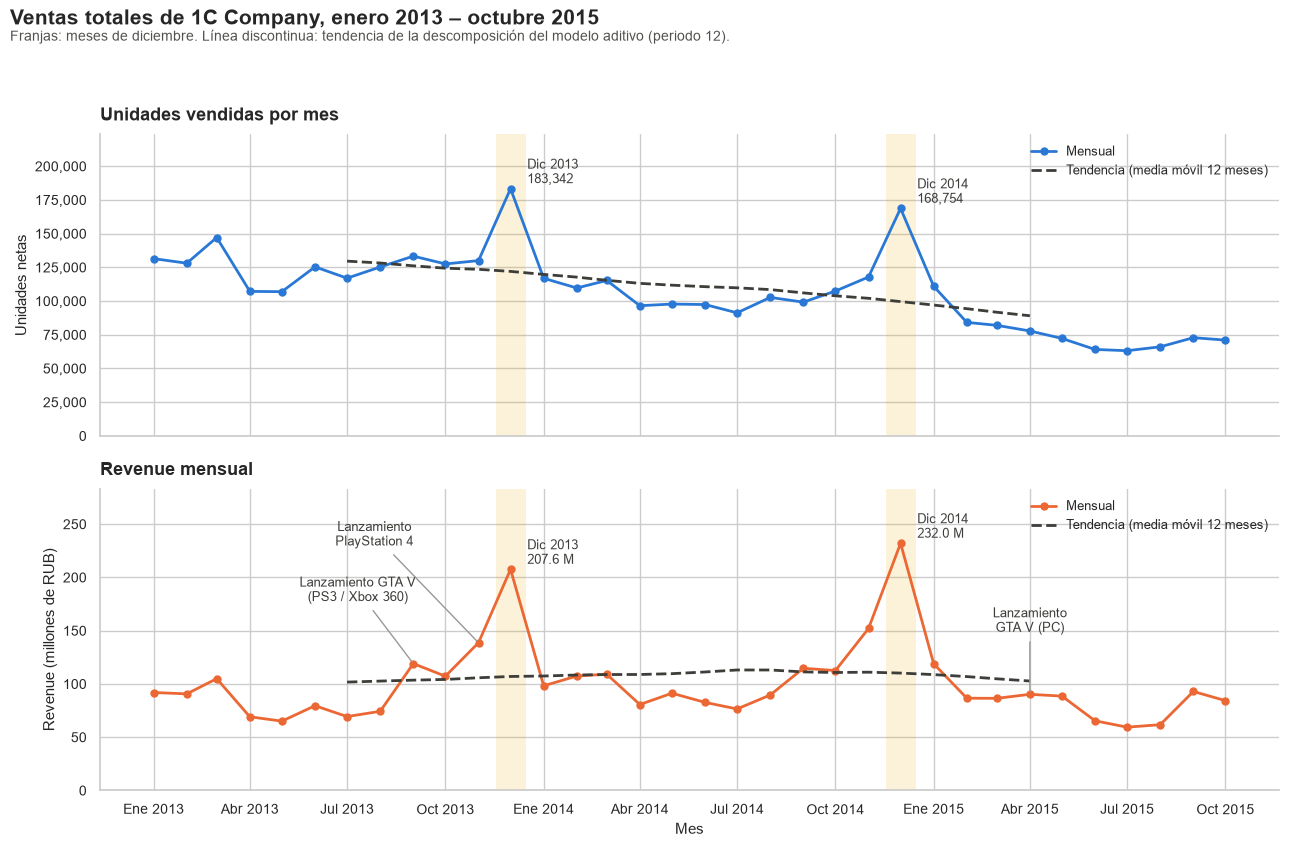

Métrica,Valor
Tendencia del revenue: inicio,2013-07: 101.7 M RUB
Tendencia del revenue: máximo,2014-07: 113.1 M RUB
Tendencia del revenue: final,2015-04: 102.7 M RUB
Revenue sep-2013 (GTA V PS3 / Xbox 360),119.1 M RUB
Revenue nov-2013 (PlayStation 4),138.7 M RUB
Revenue abr-2015 (GTA V PC),90.3 M RUB


In [62]:
revenue_decomposition = seasonal_decompose(monthly_ts["revenue_m"], model=DECOMPOSITION_MODEL, period=12)
LAUNCHES = {
    pd.Timestamp("2013-09-01"): "Lanzamiento GTA V\n(PS3 / Xbox 360)",
    pd.Timestamp("2013-11-01"): "Lanzamiento\nPlayStation 4",
    pd.Timestamp("2015-04-01"): "Lanzamiento\nGTA V (PC)",
}

fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
panels = [
    (axes[0], monthly_ts["units"], decomposition.trend, UNITS_COLOR, "Unidades vendidas por mes",
     "Unidades netas", "{:,.0f}"),
    (axes[1], monthly_ts["revenue_m"], revenue_decomposition.trend, REVENUE_COLOR, "Revenue mensual",
     "Revenue (millones de RUB)", "{:,.1f} M"),
]
for ax, series, trend_line, color, title, ylabel, value_fmt in panels:
    for month in december_months:
        ax.axvspan(month - pd.Timedelta(days=14), month + pd.Timedelta(days=14), color="#eda100", alpha=0.15,
                   linewidth=0)
    ax.plot(series.index, series, color=color, linewidth=2, marker="o", markersize=5, label="Mensual")
    ax.plot(trend_line.index, trend_line, color=TREND_COLOR, linewidth=2, linestyle="--",
            label="Tendencia (media móvil 12 meses)")
    for month in december_months:
        ax.annotate(f"Dic {month:%Y}\n{value_fmt.format(series[month])}", (month, series[month]),
                    xytext=(12, 4), textcoords="offset points", ha="left", fontsize=9, color="#3d3d3a")
    style_axis(ax, title, "", ylabel)
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_ylim(0, series.max() * 1.22)
    ax.legend(loc="upper right", fontsize=9, frameon=False)

LAUNCH_OFFSETS = {pd.Timestamp("2013-09-01"): (-40, 45), pd.Timestamp("2013-11-01"): (-75, 70),
                  pd.Timestamp("2015-04-01"): (0, 45)}
for month, label in LAUNCHES.items():
    value = monthly_ts.loc[month, "revenue_m"]
    axes[1].annotate(label, (month, value), xytext=LAUNCH_OFFSETS[month], textcoords="offset points",
                     ha="center",
                     fontsize=9, color="#3d3d3a",
                     arrowprops={"arrowstyle": "-", "color": "#9a9893", "linewidth": 1})
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(
    lambda x, _: f"{MONTH_NAMES[mdates.num2date(x).month - 1]} {mdates.num2date(x):%Y}"
))
axes[1].set_xlabel("Mes", fontsize=11)
fig.suptitle("Ventas totales de 1C Company, enero 2013 – octubre 2015", fontsize=15, fontweight="bold",
             x=0.01, y=0.995, ha="left")
fig.text(0.01, 0.958, "Franjas: meses de diciembre. Línea discontinua: tendencia de la descomposición del "
         f"modelo {MODEL_LABEL} (periodo 12).", fontsize=10, color="#52514e")
plt.tight_layout(rect=(0, 0, 1, 0.945))
save_figure(fig, "8a_serie_ventas_totales")
plt.show()

revenue_trend = revenue_decomposition.trend.dropna()
style_table(pd.DataFrame({
    "Métrica": ["Tendencia del revenue: inicio", "Tendencia del revenue: máximo",
                "Tendencia del revenue: final", "Revenue sep-2013 (GTA V PS3 / Xbox 360)",
                "Revenue nov-2013 (PlayStation 4)", "Revenue abr-2015 (GTA V PC)"],
    "Valor": [f"{revenue_trend.index[0]:%Y-%m}: {revenue_trend.iloc[0]:,.1f} M RUB",
              f"{revenue_trend.idxmax():%Y-%m}: {revenue_trend.max():,.1f} M RUB",
              f"{revenue_trend.index[-1]:%Y-%m}: {revenue_trend.iloc[-1]:,.1f} M RUB",
              *[f"{monthly_ts.loc[m, 'revenue_m']:,.1f} M RUB" for m in LAUNCHES]],
}))

**Interpretación**

- **Unidades:** su tendencia cae de forma sostenida, de 129,620 a 89,114 unidades mensuales entre julio de
  2013 y abril de 2015. Los diciembres sobresalen claramente, con 183,342 unidades en 2013 y 168,754 en 2014.
- **Revenue:** su tendencia se mantiene casi plana: sube de 101.7 a 113.1 M RUB hasta julio de 2014 y
  vuelve a 102.7 M RUB en abril de 2015. Diciembre de 2014 (232.0 M RUB) supera al de 2013 (207.6 M RUB)
  aunque se vendieron menos unidades.
- **Lanzamientos:** GTA V para PS3 y Xbox 360 lleva el revenue de septiembre de 2013 a 119.1 M RUB, y la
  PlayStation 4 adelanta en noviembre de 2013 (138.7 M RUB) el pico de diciembre. GTA V para PC (abril de
  2015, 90.3 M RUB) apenas se nota a escala mensual, porque su efecto se concentró en una semana.
- La gráfica resume el reto del forecasting: el volumen cae, los ingresos se sostienen con productos más
  caros, y el calendario de fin de año y de lanzamientos mueve los totales.

### 8.b Ventas por sucursal

Revenue mensual medio (revenue / meses activos) y unidades por mes activo de todas las tiendas, ordenadas
por revenue mensual medio. El color indica el tipo de tienda, y las barras atenuadas y rayadas marcan las
tiendas que no venden en octubre de 2015.

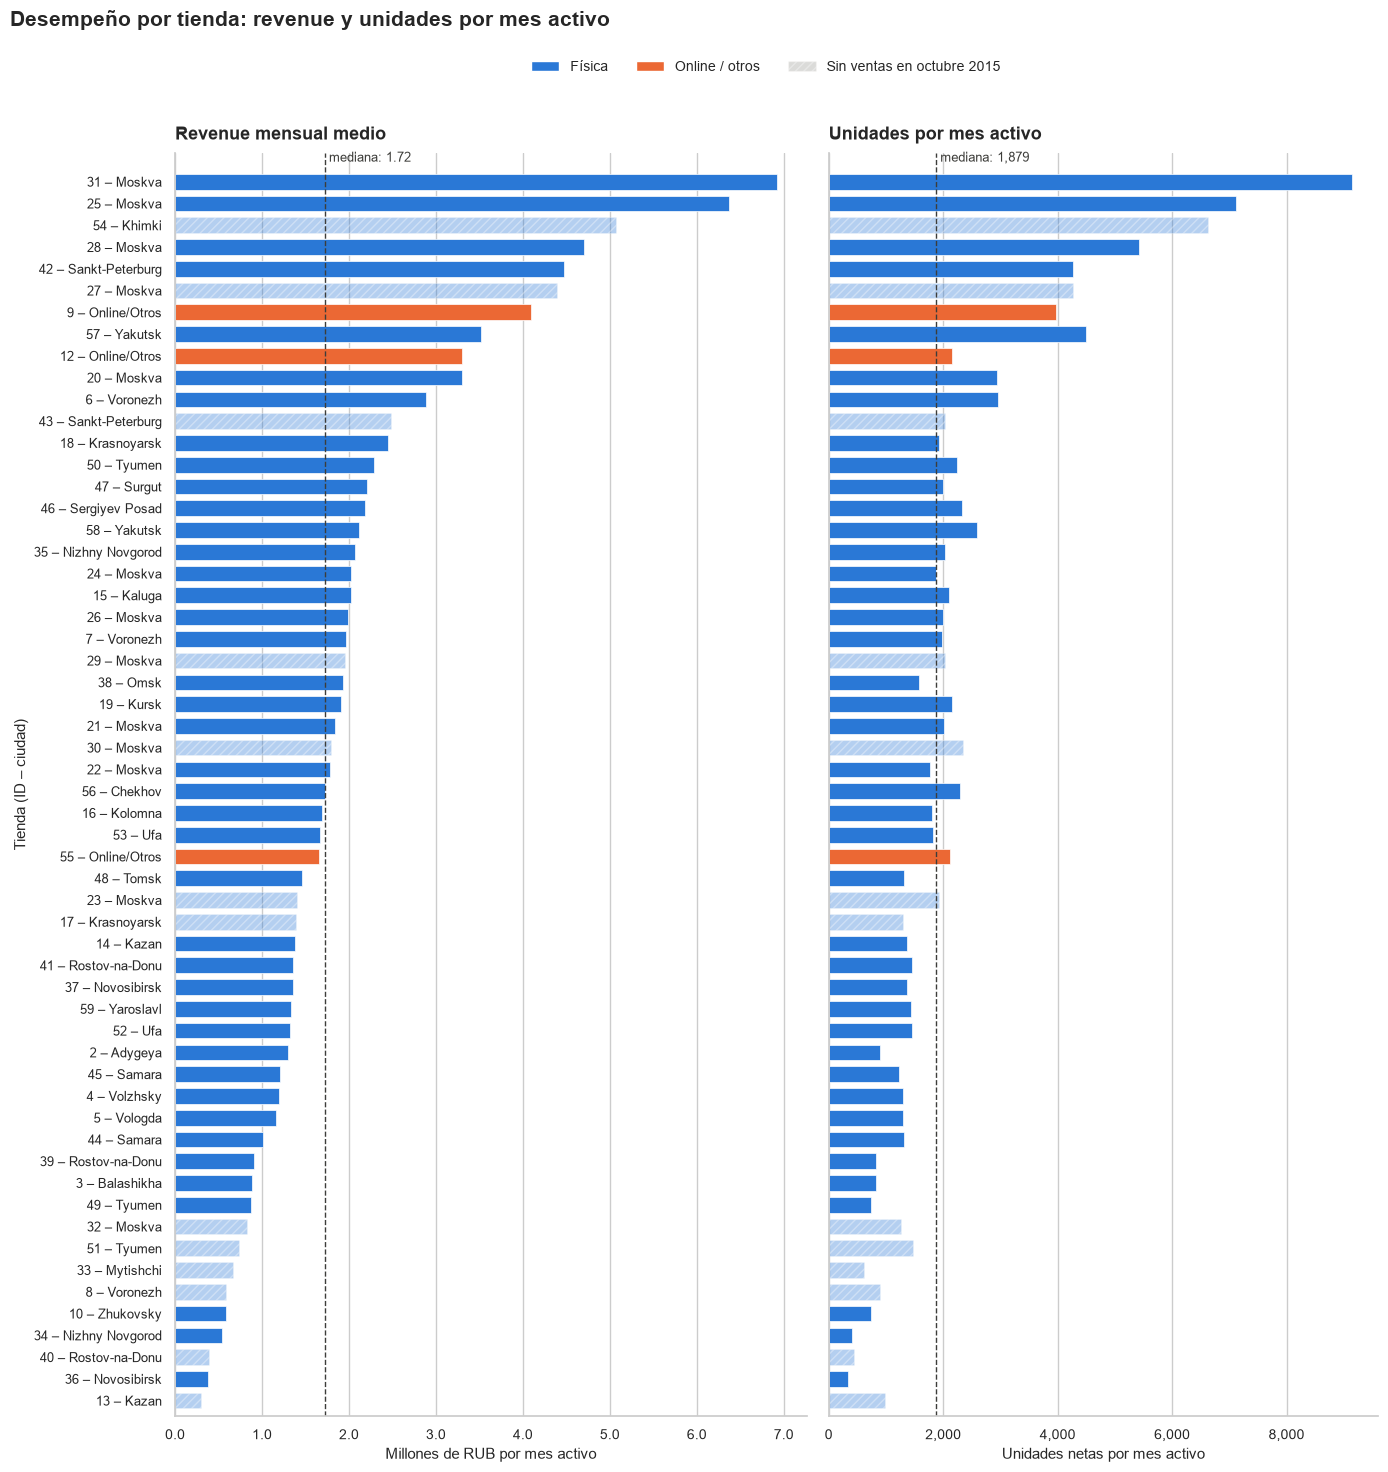

In [63]:
shop_viz = shop_performance.sort_values("Revenue mensual medio (M RUB)", ascending=True).copy()
shop_viz["label"] = shop_viz["shop_id"].astype(str) + " – " + shop_viz["ciudad"].astype(str)
inactive = shop_viz["Vende en oct-2015"] == "No"

fig, axes = plt.subplots(1, 2, figsize=(14, 15), sharey=True, gridspec_kw={"width_ratios": [1.15, 1]})
for ax, column, title, xlabel in [
    (axes[0], "Revenue mensual medio (M RUB)", "Revenue mensual medio", "Millones de RUB por mes activo"),
    (axes[1], "Unidades por mes", "Unidades por mes activo", "Unidades netas por mes activo"),
]:
    bars = ax.barh(shop_viz["label"], shop_viz[column], color=shop_viz["tipo_tienda"].map(SHOP_TYPE_COLORS),
                   height=0.72, edgecolor="white", linewidth=0.5)
    for bar, is_inactive in zip(bars, inactive):
        if is_inactive:
            bar.set_alpha(0.35)
            bar.set_hatch("////")
    median = shop_viz[column].median()
    ax.axvline(median, color=TREND_COLOR, linestyle="--", linewidth=1)
    ax.text(median, len(shop_viz) - 0.2, f" mediana: {median:,.2f}" if "Revenue" in column
            else f" mediana: {median:,.0f}", fontsize=9, color="#3d3d3a", va="bottom")
    style_axis(ax, title, xlabel, "")
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.1f}" if "Revenue" in column else "{x:,.0f}"))
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.7, len(shop_viz) + 0.3)
axes[0].set_ylabel("Tienda (ID – ciudad)", fontsize=11)
axes[0].tick_params(axis="y", labelsize=9)
legend_items = [
    Patch(facecolor=SHOP_TYPE_COLORS["Física"], label="Física"),
    Patch(facecolor=SHOP_TYPE_COLORS["Online/Otros"], label="Online / otros"),
    Patch(facecolor="#9a9893", alpha=0.35, hatch="////", label="Sin ventas en octubre 2015"),
]
fig.legend(handles=legend_items, loc="upper center", ncol=3, frameon=False, fontsize=10,
           bbox_to_anchor=(0.55, 0.955))
fig.suptitle("Desempeño por tienda: revenue y unidades por mes activo", fontsize=15, fontweight="bold",
             x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(fig, "8b_ventas_por_sucursal")
plt.show()

**Interpretación**

- La distribución entre tiendas está muy concentrada arriba. La 31 (Moskva) y la 25 (Moskva) superan los
  6 M RUB al mes, más de 3.5 veces la mediana de 1.72 M RUB, y lideran también en unidades (la mediana es
  de 1,879 al mes).
- Dos de las seis primeras tiendas por revenue mensual, la 54 (Khimki) y la 27 (Moskva), aparecen
  atenuadas: dejaron de vender antes de octubre de 2015. Su peso histórico no se trasladará a noviembre.
- Las tiendas 9 y 20 ocupan puestos altos solo porque venden en meses de evento. La tienda online 12
  destaca más en revenue que en unidades (ticket alto), y la 57 (Yakutsk) al revés.
- Las atenuadas se concentran en la parte baja del ranking: tiendas pequeñas o con pocos meses de actividad
  que cerraron.

### 8.c Ventas por producto y por categoría

**Top 20 de productos** por unidades y por revenue, con la descripción en español y coloreados por
categoría principal.

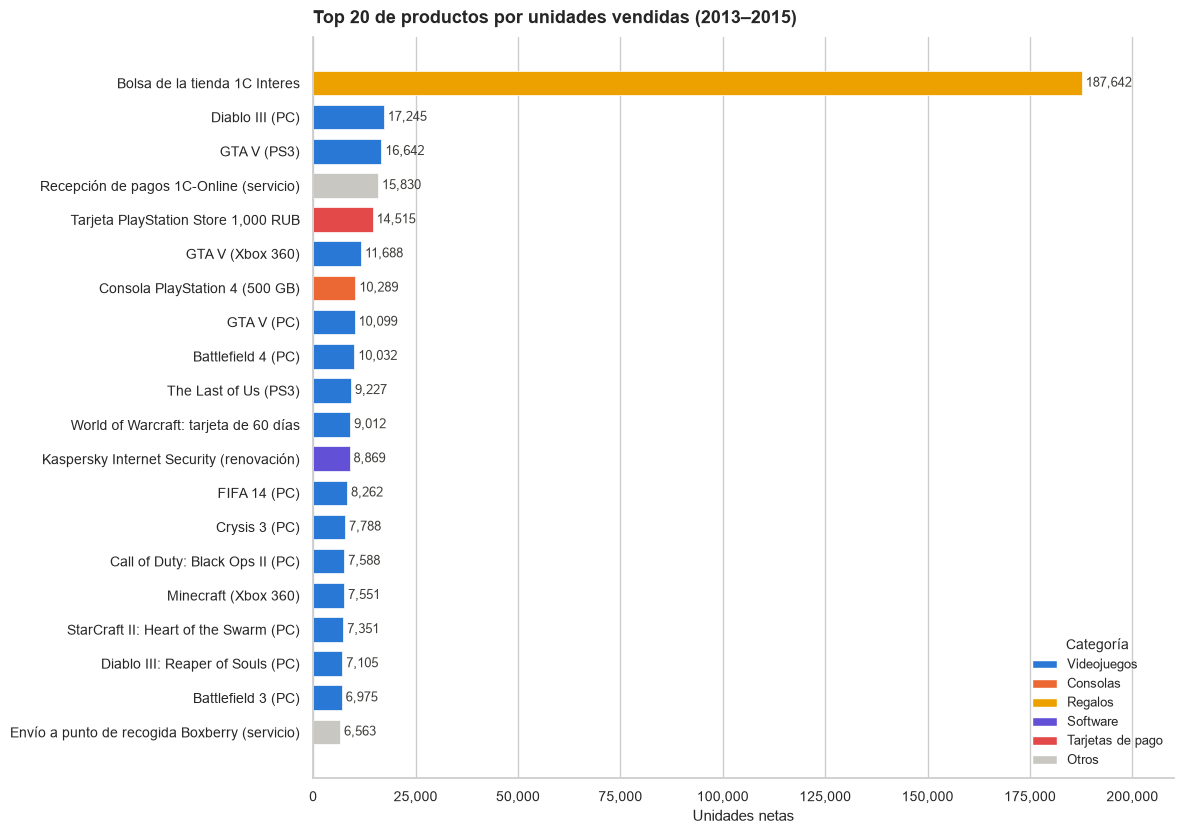

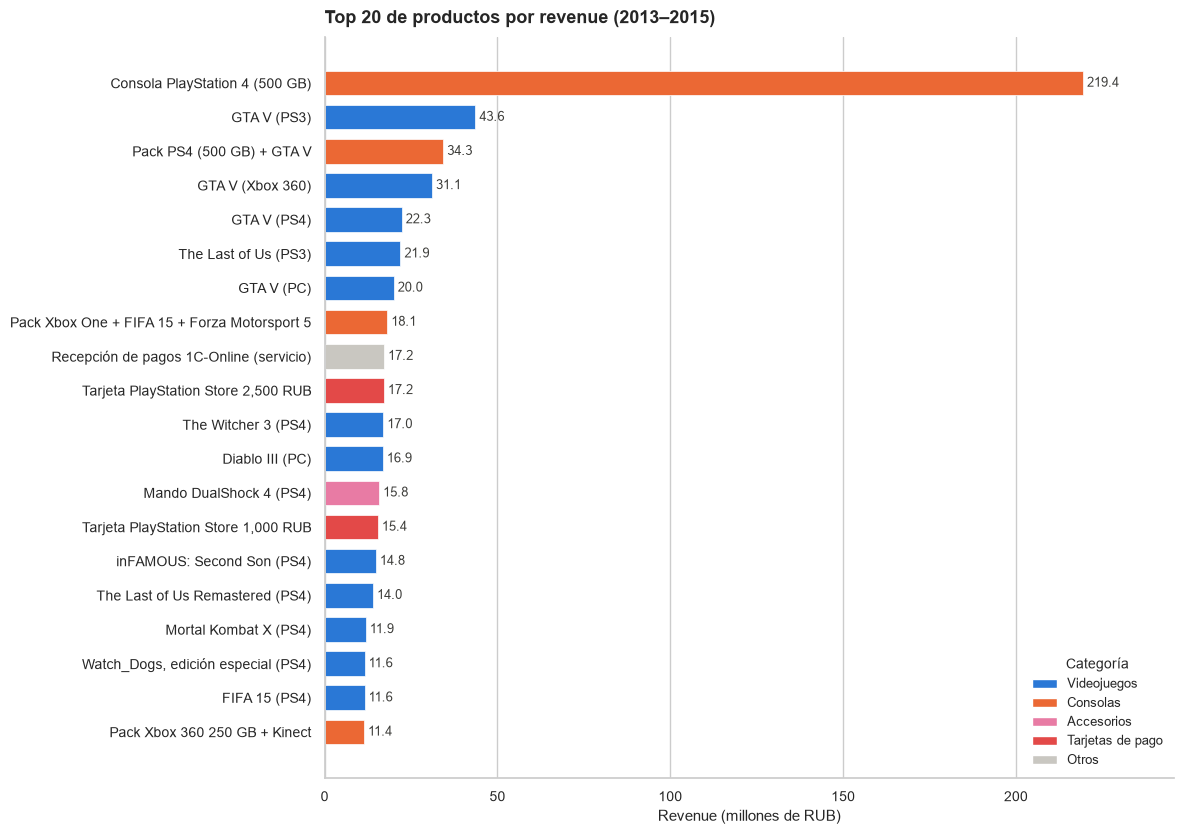

In [64]:
def plot_top_products(metric: str, title: str, xlabel: str, scale: float, value_fmt: str, name: str):
    top = item_totals.nlargest(20, metric).iloc[::-1].copy()
    top["label"] = top["item_id"].map(ITEM_DESCRIPTIONS)
    if top["label"].isna().any():
        raise ValueError(f"Faltan descripciones: {top.loc[top['label'].isna(), 'item_id'].tolist()}")
    values = top[metric] / scale

    fig, ax = plt.subplots(figsize=(12, 8.5))
    ax.barh(top["label"], values, color=top["categoria_principal"].astype(str).map(CATEGORY_COLORS),
            height=0.72, edgecolor="white", linewidth=0.5)
    for y, value in enumerate(values):
        ax.text(value, y, f" {value_fmt.format(value)}", va="center", fontsize=9, color="#3d3d3a")
    style_axis(ax, title, xlabel, "")
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, values.max() * 1.12)
    present = [c for c in CATEGORY_COLORS if c in set(top["categoria_principal"].astype(str))]
    ax.legend(handles=[Patch(facecolor=CATEGORY_COLORS[c], label=c) for c in present], title="Categoría",
              loc="lower right", frameon=False, fontsize=9, title_fontsize=10)
    plt.tight_layout()
    save_figure(fig, name)
    plt.show()


plot_top_products("units", "Top 20 de productos por unidades vendidas (2013–2015)", "Unidades netas", 1,
                  "{:,.0f}", "8c_top20_productos_unidades")
plot_top_products("revenue", "Top 20 de productos por revenue (2013–2015)", "Revenue (millones de RUB)", 1e6,
                  "{:,.1f}", "8c_top20_productos_revenue")

**Interpretación**

- **Por unidades:** la bolsa de la tienda (187,642) es un caso aparte, con más de diez veces las ventas
  del segundo producto. Del resto del top 20, 14 son videojuegos, en su mayoría de PC (10 de los 14:
  Diablo III, Battlefield, FIFA 14, Crysis 3, Call of Duty, StarCraft II, la tarjeta de World of Warcraft
  y otros). Completan el ranking servicios y tarjetas: cobro de 1C-Online, envíos Boxberry, PlayStation
  Store y Kaspersky.
- **Por revenue:** el top 20 está dominado por el ecosistema de **PlayStation 4**, con 10 de los 20
  productos (consola, pack con GTA V, mando DualShock 4 y juegos como The Witcher 3, inFAMOUS, Mortal
  Kombat X o FIFA 15). La consola PS4 sola (219.4 M RUB) quintuplica al segundo producto.
- Los dos rankings dependen de motores distintos: el volumen viene del PC y de artículos de baja cuantía, y
  los ingresos de consolas y juegos de nueva generación.

**Participación por categoría principal** en unidades y en revenue, lado a lado.

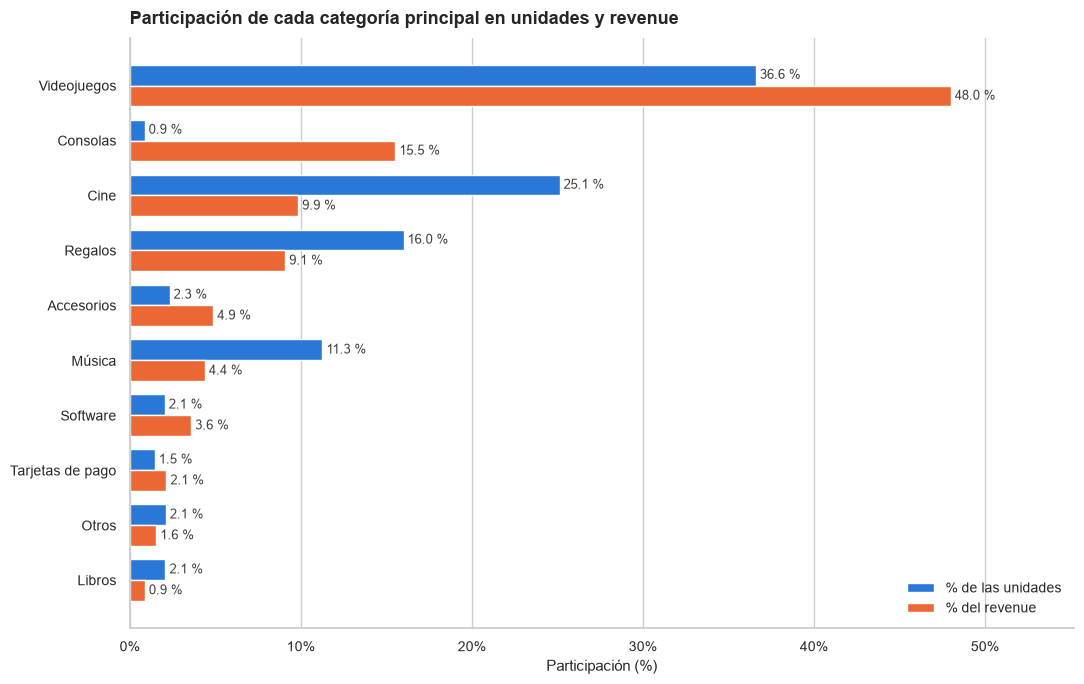

In [65]:
category_viz = main_ranking.sort_values("% revenue", ascending=True)
y = np.arange(len(category_viz))
height = 0.38

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y + height / 2, category_viz["% unidades"], height=height, color=UNITS_COLOR, label="% de las unidades",
        edgecolor="white", linewidth=1)
ax.barh(y - height / 2, category_viz["% revenue"], height=height, color=REVENUE_COLOR,
        label="% del revenue", edgecolor="white", linewidth=1)
for offset, column in [(height / 2, "% unidades"), (-height / 2, "% revenue")]:
    for yi, value in zip(y, category_viz[column]):
        ax.text(value, yi + offset, f" {value:.1f} %", va="center", fontsize=9, color="#3d3d3a")
ax.set_yticks(y, category_viz["categoria_principal"])
style_axis(ax, "Participación de cada categoría principal en unidades y revenue", "Participación (%)", "")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, category_viz[["% unidades", "% revenue"]].max().max() * 1.15)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, fontsize=10)
plt.tight_layout()
save_figure(fig, "8c_participacion_categorias")
plt.show()

**Interpretación**

- Las barras lado a lado muestran el contraste entre volumen e ingresos. **Videojuegos** domina ambas
  métricas (36.6 % de las unidades y 48.0 % del revenue), y **Consolas** casi no pesa en unidades (0.9 %)
  pero aporta el 15.5 % del revenue.
- **Cine** (25.1 % frente a 9.9 %), **Regalos** (16.0 % frente a 9.1 %) y **Música** (11.3 % frente a
  4.4 %) son categorías de volumen con precios bajos.
- Accesorios, Software y Tarjetas de pago pesan más en revenue que en unidades. Otros y Libros pesan más en
  unidades.

### 8.d Heatmaps

**Tienda × mes.** Unidades mensuales por tienda en escala de color logarítmica, con las tiendas ordenadas
por ciudad. Las celdas grises son meses sin ventas, lo que deja ver aperturas y cierres, y las líneas
verticales marcan los diciembres.

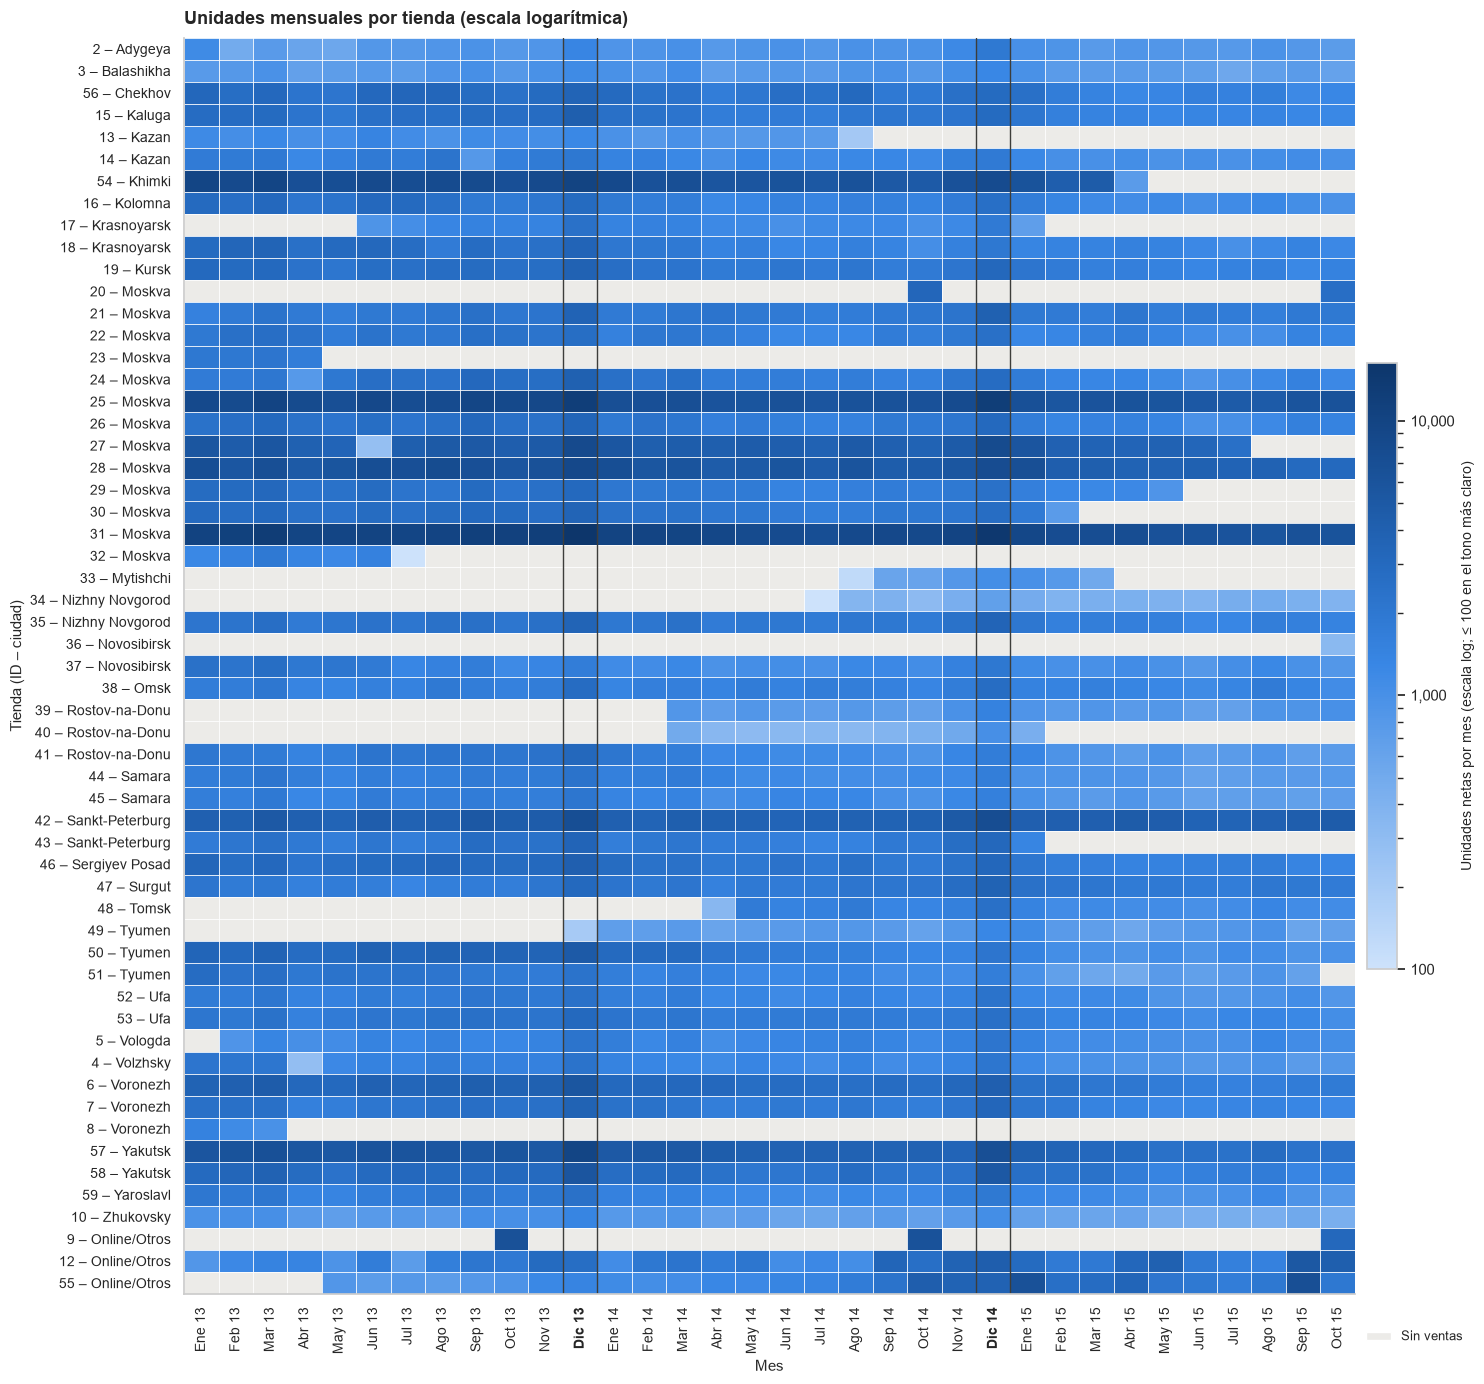

In [66]:
shop_month = sales_viz.pivot_table(index="shop_id", columns="date_block_num", values="item_cnt_day",
                                   aggfunc="sum").reindex(columns=range(34))
shop_order = (
    shop_performance[["shop_id", "ciudad", "tipo_tienda"]]
    .assign(online=lambda d: d["tipo_tienda"] == "Online/Otros", ciudad=lambda d: d["ciudad"].astype(str))
    .sort_values(["online", "ciudad", "shop_id"])
)
shop_month = shop_month.loc[shop_order["shop_id"]].where(lambda d: d > 0)

fig, ax = plt.subplots(figsize=(15, 14))
cmap = SEQUENTIAL_CMAP.copy()
cmap.set_bad("#ecebe8")
image = ax.imshow(shop_month.values, aspect="auto", cmap=cmap,
                  norm=LogNorm(vmin=100, vmax=shop_month.max().max(), clip=True), interpolation="none")
ax.set_yticks(range(len(shop_order)),
              shop_order["shop_id"].astype(str) + " – " + shop_order["ciudad"], fontsize=9)
ax.set_xticks(range(34), MONTH_LABELS, rotation=90, fontsize=9)
for label, month in zip(ax.get_xticklabels(), monthly_ts.index):
    if month.month == 12:
        label.set_fontweight("bold")
for block in [11, 23]:
    ax.axvline(block - 0.5, color="#3d3d3a", linewidth=1)
    ax.axvline(block + 0.5, color="#3d3d3a", linewidth=1)
ax.set_xticks(np.arange(-0.5, 34, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(shop_order), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.6)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
style_axis(ax, "Unidades mensuales por tienda (escala logarítmica)", "Mes", "Tienda (ID – ciudad)")
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
colorbar.set_label("Unidades netas por mes (escala log; ≤ 100 en el tono más claro)", fontsize=10)
colorbar.ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(handles=[Patch(facecolor="#ecebe8", label="Sin ventas")], loc="upper left",
          bbox_to_anchor=(1.0, -0.02), frameon=False, fontsize=9)
plt.tight_layout()
save_figure(fig, "8d_heatmap_tienda_mes")
plt.show()

**Interpretación**

- El heatmap resume la vida de la red de tiendas:
  - **Aperturas:** 5 (feb-2013), 55 (may-2013), 17 (jun-2013), 49 (dic-2013), 39 y 40 (mar-2014), 48 (abr-2014),
    34 (jul-2014), 33 (ago-2014) y 36 (oct-2015).
  - **Cierres:** 8 y 23 (2013), 32 (2013), 13 (2014), y en 2015 las 17, 30, 33, 40, 43, 54 y 29, además
    de la 51 y la 27 al final del periodo.
- Las columnas de diciembre son más oscuras en casi todas las tiendas: el pico de fin de año es
  generalizado y no depende de unas pocas tiendas.
- Las tiendas 9 y 20 solo tienen celdas en octubre (y la 9 en abril de 2015): son puntos de venta de
  evento.
- Las tiendas online (12 y 55) se oscurecen con el tiempo, al revés que la mayoría de las físicas, que se
  aclaran en 2015 por la caída de volumen.

**Categoría principal × mes y plataformas de videojuegos × mes.** Participación de cada categoría en las
unidades de cada mes (cada columna suma 100 %) y, dentro de *Videojuegos*, participación de cada plataforma,
para ver cómo cambia la mezcla de ventas.

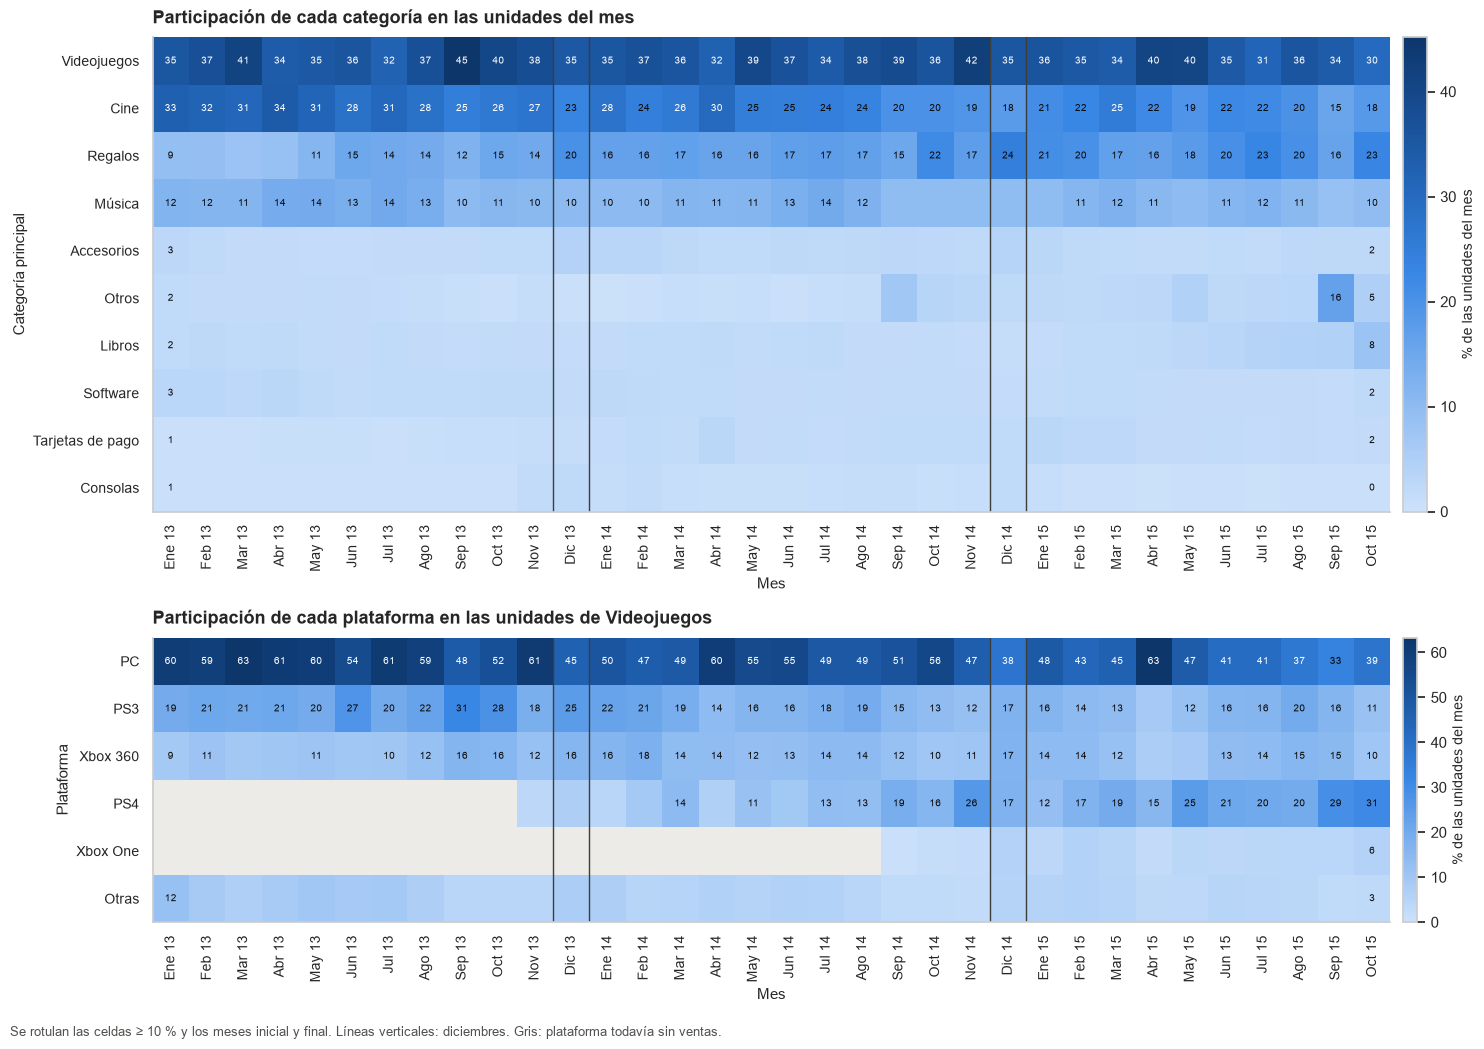

Tipo,Grupo,Media 2013 (%),Media ene–oct 2015 (%),Cambio (p. p.)
Categoría,Videojuegos,37.1,35.1,-2.0
Categoría,Cine,29.2,20.8,-8.4
Categoría,Regalos,12.6,19.4,+6.8
Categoría,Música,12.0,10.6,-1.5
Categoría,Accesorios,2.0,2.2,+0.2
Categoría,Otros,1.4,4.3,+3.0
Categoría,Libros,1.8,3.4,+1.6
Categoría,Software,2.3,1.8,-0.5
Categoría,Tarjetas de pago,0.8,2.0,+1.1
Categoría,Consolas,0.7,0.5,-0.3


In [67]:
category_month = sales_viz.pivot_table(index="categoria_principal", columns="date_block_num",
                                       values="item_cnt_day", aggfunc="sum", observed=True)
category_month = (category_month / category_month.sum() * 100).loc[
    main_ranking.sort_values("Puesto unidades")["categoria_principal"]
]

PLATFORM_BY_SUBCATEGORY = {18: "Otras", 19: "PS3", 20: "PS4", 21: "Otras", 22: "Otras", 23: "Xbox 360",
                           24: "Xbox One", 25: "Otras", 26: "Otras", 27: "Otras", 28: "PC", 29: "PC", 30: "PC",
                           31: "PC"}
games = sales_viz[sales_viz["categoria_principal"] == "Videojuegos"].assign(
    platform=lambda d: d["item_category_id"].map(PLATFORM_BY_SUBCATEGORY)
)
platform_month = games.pivot_table(index="platform", columns="date_block_num", values="item_cnt_day",
                                   aggfunc="sum")
platform_month = (platform_month / platform_month.sum() * 100).loc[
    ["PC", "PS3", "Xbox 360", "PS4", "Xbox One", "Otras"]
]

fig, axes = plt.subplots(2, 1, figsize=(15, 10.5), gridspec_kw={"height_ratios": [10, 6]})
for ax, frame, title, ylabel in [
    (axes[0], category_month, "Participación de cada categoría en las unidades del mes",
     "Categoría principal"),
    (axes[1], platform_month, "Participación de cada plataforma en las unidades de Videojuegos",
     "Plataforma"),
]:
    mix_cmap = SEQUENTIAL_CMAP.copy()
    mix_cmap.set_bad("#ecebe8")
    image = ax.imshow(frame.values, aspect="auto", cmap=mix_cmap, vmin=0, interpolation="none")
    for (row, col), value in np.ndenumerate(frame.values):
        if not np.isnan(value) and (value >= 10 or col in (0, 33)):
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if value > frame.values[~np.isnan(frame.values)].max() * 0.55 else "#0b0b0b")
    ax.set_yticks(range(len(frame)), frame.index, fontsize=10)
    ax.set_xticks(range(34), MONTH_LABELS, rotation=90, fontsize=9)
    for block in [11, 23]:
        ax.axvline(block - 0.5, color="#3d3d3a", linewidth=1)
        ax.axvline(block + 0.5, color="#3d3d3a", linewidth=1)
    ax.grid(False)
    style_axis(ax, title, "Mes", ylabel)
    colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
    colorbar.set_label("% de las unidades del mes", fontsize=10)
fig.text(0.01, 0.005, "Se rotulan las celdas ≥ 10 % y los meses inicial y final. Líneas verticales: diciembres. "
         "Gris: plataforma todavía sin ventas.",
         fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0.02, 1, 1))
save_figure(fig, "8d_heatmap_categoria_mes")
plt.show()

mix_change = pd.concat(
    [
        category_month.assign(Tipo="Categoría"),
        platform_month.assign(Tipo="Plataforma (dentro de Videojuegos)"),
    ]
)
mix_summary = pd.DataFrame({
    "Tipo": mix_change["Tipo"],
    "Grupo": mix_change.index,
    "Media 2013 (%)": mix_change[list(range(0, 12))].mean(axis=1),
    "Media ene–oct 2015 (%)": mix_change[list(range(24, 34))].mean(axis=1),
})
mix_summary["Cambio (p. p.)"] = mix_summary["Media ene–oct 2015 (%)"] - mix_summary["Media 2013 (%)"]
style_table(mix_summary.reset_index(drop=True),
            {"Media 2013 (%)": "{:.1f}", "Media ene–oct 2015 (%)": "{:.1f}", "Cambio (p. p.)": "{:+.1f}"})

**Interpretación**

- **Mezcla por categoría:**
  - **Cine** pierde peso de forma continua: del 29.2 % de las unidades en 2013 al 20.8 % en 2015
    (−8.4 p. p.), con mínimos del 15 % al 18 % a finales de 2015.
  - **Regalos** gana 6.8 p. p. (de 12.6 % a 19.4 %) y llega al 24 % en diciembre de 2014.
  - Videojuegos se mantiene en torno al 35 %.
  - Otros sube a 4.3 % de media, con un pico del 16 % en septiembre de 2015 (entradas de ИгроМир 2015), y
    Libros llega al 8 % en octubre de 2015.
- **Mezcla de plataformas dentro de Videojuegos:**
  - **PS4** pasa de no existir antes de noviembre de 2013 a un 20.9 % de media en 2015 (+15.4 p. p.) y un
    31 % en octubre de 2015.
  - **Xbox One** aparece en septiembre de 2014 y alcanza un 4.3 %.
  - A cambio, **PC** cae del 57.0 % al 43.8 % y **PS3** del 22.8 % al 14.3 %. Xbox 360 se mantiene en torno
    al 12 %.
- Para el pronóstico, la mezcla cambia y el comportamiento pasado de una categoría o plataforma no se
  traslada tal cual a noviembre de 2015. Las variables de categoría y plataforma deben capturar estas
  tendencias.

#### Figuras guardadas

In [68]:
style_table(pd.DataFrame({
    "Archivo": [path.as_posix() for path in saved_figures],
    "Tamaño (KB)": [path.stat().st_size / 1024 for path in saved_figures],
}), {"Tamaño (KB)": "{:,.0f}"})

Archivo,Tamaño (KB)
../reports/figures/8a_serie_ventas_totales.png,196
../reports/figures/8b_ventas_por_sucursal.png,232
../reports/figures/8c_top20_productos_unidades.png,143
../reports/figures/8c_top20_productos_revenue.png,133
../reports/figures/8c_participacion_categorias.png,76
../reports/figures/8d_heatmap_tienda_mes.png,273
../reports/figures/8d_heatmap_categoria_mes.png,279


## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

- **ACF (función de autocorrelación):** mide la correlación de la serie consigo misma desplazada *k*
  periodos (rezago *k*). Incluye efectos directos e indirectos: si las ventas de un mes se parecen a las del
  anterior, también se parecerán, en menor grado, a las de dos meses antes.
- **PACF (autocorrelación parcial):** mide la correlación con el rezago *k* después de descontar el efecto
  de los rezagos intermedios 1 a *k*−1. Aísla la relación directa y sirve para sugerir el orden de un modelo
  autorregresivo AR(*p*): el último rezago significativo antes de que la PACF se corte.
- **Bandas de confianza del 95 %:** la zona sombreada indica el rango compatible con una correlación nula.
  Una barra que la sobrepasa es significativa al 5 %. En la ACF la banda se ensancha con el rezago (fórmula
  de Bartlett); en la PACF es aproximadamente ±1.96/√n. Con muchos rezagos, alguno puede salir significativo
  por azar (1 de cada 20 en promedio).
- **Limitación de la serie mensual:** solo hay **34 observaciones**. La PACF solo puede estimarse hasta
  algo menos de la mitad de la muestra (**16 rezagos**), las bandas son anchas (±0.34 en la PACF) y el
  rezago 12 se apoya en solo 22 pares de meses. La serie diaria (1,034 observaciones) permite analizar
  hasta 60 rezagos con bandas mucho más estrechas (±0.06).
- **Estacionariedad:** se contrasta con la prueba de **Dickey-Fuller aumentada (ADF)**, cuya hipótesis nula
  es que la serie tiene raíz unitaria (no es estacionaria). Si el p-valor supera 0.05, se repite el análisis
  sobre la primera diferencia.

#### Selección de series representativas

Solo se usan series que existen en `test.csv` y siguen activas en octubre de 2015, porque son las que hay
que pronosticar:

- **Ventas totales:** unidades mensuales (34 observaciones) y diarias (1,034 observaciones).
- **Por sucursal:** las 3 tiendas con más unidades entre las activas y presentes en `test.csv`. Se excluye
  la 54 (Khimki), que es la tercera del histórico pero cerró en 2015.
- **Por producto:** los 3 productos con más unidades que están en `test.csv`, venden en octubre de 2015 y
  tienen ventas en al menos 18 de los 34 meses. Se **excluyen la bolsa de la tienda (20949) y los
  artículos de servicio** (entradas digitales, envíos y servicios: subcategorías 8, 9, 79 y 80), cuya
  demanda depende del tráfico de la tienda y no del producto.
- **Por sucursal-producto:** los 3 pares tienda-producto de `test.csv` con más unidades, ventas en al menos
  18 meses y actividad en octubre de 2015, con la misma exclusión.

En las series mensuales por producto y por par, los meses sin ventas se completan con 0.

In [69]:
sales_acf = load_parquet(ENRICHED_SALES_FILE)
NON_PRODUCT_CATEGORIES = {8, 9, 79, 80}
non_product_items = set(items.loc[items["item_category_id"].isin(NON_PRODUCT_CATEGORIES), "item_id"]) | {20949}
MIN_MONTHS = 18
test_pairs = set(zip(test["shop_id"], test["item_id"]))
active_shops = set(sales_acf.loc[sales_acf["date_block_num"] == 33, "shop_id"]) & set(test["shop_id"])

top_shops = (
    sales_acf[sales_acf["shop_id"].isin(active_shops)].groupby("shop_id")["item_cnt_day"].sum().nlargest(3)
)

eligible = sales_acf[~sales_acf["item_id"].isin(non_product_items)]
item_stats = eligible.groupby("item_id").agg(units=("item_cnt_day", "sum"),
                                             months=("date_block_num", "nunique"),
                                             last=("date_block_num", "max"))
top_items = item_stats[(item_stats["months"] >= MIN_MONTHS) & (item_stats["last"] == 33)
                       & item_stats.index.isin(test["item_id"])].nlargest(3, "units")

pair_stats = eligible.groupby(["shop_id", "item_id"]).agg(units=("item_cnt_day", "sum"),
                                                          months=("date_block_num", "nunique"),
                                                          last=("date_block_num", "max")).reset_index()
pair_in_test = np.array([pair in test_pairs for pair in zip(pair_stats["shop_id"], pair_stats["item_id"])])
top_pairs = pair_stats[(pair_stats["months"] >= MIN_MONTHS) & (pair_stats["last"] == 33)
                       & pair_in_test].nlargest(3, "units")

ITEM_DESCRIPTIONS.update({492: "1C:Dinero 8 (PC, digital)"})
MONTH_INDEX = pd.date_range("2013-01-01", periods=34, freq="MS")


def monthly_series(frame: pd.DataFrame) -> pd.Series:
    series = frame.groupby("date_block_num")["item_cnt_day"].sum().reindex(range(34), fill_value=0)
    series.index = MONTH_INDEX
    return series.astype(float)


daily_total = sales_acf.groupby("date")["item_cnt_day"].sum().astype(float)
SERIES = {"Total mensual": ("Mensual", monthly_series(sales_acf))}
for shop_id, units in top_shops.items():
    city = shop_performance.set_index("shop_id").loc[shop_id, "ciudad"]
    SERIES[f"Tienda {shop_id} ({city})"] = ("Mensual", monthly_series(sales_acf[sales_acf["shop_id"] == shop_id]))
for item_id in top_items.index:
    SERIES[f"Producto {item_id}: {ITEM_DESCRIPTIONS[item_id]}"] = (
        "Mensual", monthly_series(sales_acf[sales_acf["item_id"] == item_id]))
for _, pair in top_pairs.iterrows():
    mask = (sales_acf["shop_id"] == pair["shop_id"]) & (sales_acf["item_id"] == pair["item_id"])
    SERIES[f"Tienda {pair['shop_id']} × {ITEM_DESCRIPTIONS[pair['item_id']]}"] = (
        "Mensual", monthly_series(sales_acf[mask]))

selection = pd.DataFrame([
    {"Serie": name, "Frecuencia": freq, "Obs.": len(series), "Unidades totales": series.sum(),
     "Meses con ventas": int((series != 0).sum())}
    for name, (freq, series) in SERIES.items()
])
selection.loc[len(selection)] = ["Total diario", "Diaria", len(daily_total), daily_total.sum(), 34]
style_table(selection, {"Unidades totales": "{:,.0f}"})

Serie,Frecuencia,Obs.,Unidades totales,Meses con ventas
Total mensual,Mensual,34,"3,648,200",34
Tienda 31 (Moskva),Mensual,34,"310,777",34
Tienda 25 (Moskva),Mensual,34,"241,919",34
Tienda 28 (Moskva),Mensual,34,"184,557",34
Producto 2808: Diablo III (PC),Mensual,34,"17,245",34
Producto 3732: GTA V (PS3),Mensual,34,"16,642",26
"Producto 5822: Tarjeta PlayStation Store 1,000 RUB",Mensual,34,"14,515",34
"Tienda 55 × 1C:Dinero 8 (PC, digital)",Mensual,34,"2,221",30
"Tienda 31 × Tarjeta PlayStation Store 1,000 RUB",Mensual,34,"1,293",34
Tienda 25 × Diablo III (PC),Mensual,34,"1,216",32


#### Funciones de análisis

Para cada serie se dibujan la serie, su ACF y su PACF (`method="ywm"`) en una fila de tres paneles, y se
aplica la prueba ADF. Si la serie no es estacionaria (p > 0.05) se añade una segunda fila con la primera
diferencia. Para cada versión se registran los rezagos significativos al 95 %, el orden AR sugerido por la
PACF (número de rezagos significativos consecutivos desde el 1) y si hay estacionalidad visible.

In [70]:
ALPHA = 0.05


def significant_lags(series: pd.Series, nlags: int, kind: str) -> tuple[list[int], np.ndarray]:
    if kind == "acf":
        values, confint = acf(series, nlags=nlags, alpha=ALPHA, fft=False, result_object=False)
    else:
        values, confint = pacf(series, nlags=nlags, alpha=ALPHA, method="ywm")
    lower, upper = confint[:, 0] - values, confint[:, 1] - values
    lags = [k for k in range(1, nlags + 1) if values[k] < lower[k] or values[k] > upper[k]]
    return lags, values


def suggested_ar_order(pacf_lags: list[int]) -> int:
    order = 0
    while order + 1 in pacf_lags:
        order += 1
    return order


def describe_lags(lags: list[int], nlags: int) -> str:
    if not lags:
        return "Ninguno"
    return f"{month_ranges(lags)} ({len(lags)} de {nlags})"


def seasonality_label(freq: str, acf_values: np.ndarray, acf_lags: list[int], nlags: int) -> str:
    if freq == "Diaria":
        weekly = [k for k in (7, 14, 21, 28) if k in acf_lags and acf_values[k] > 0]
        if len(weekly) >= 3:
            return f"Sí, semanal ({', '.join(map(str, weekly))} significativos)"
        if 7 in acf_lags and acf_values[7] < 0:
            return "No; queda correlación negativa en el rezago 7 (efecto de la diferencia)"
        return "No"
    if nlags < 12:
        return "No evaluable"
    if 12 in acf_lags and acf_values[12] > 0:
        return "Sí (rezago 12 significativo)"
    if acf_values[12] >= 0.1 and acf_values[12] > acf_values[11] and acf_values[12] > acf_values[13]:
        return "Indicio débil (máximo local en 12, no significativo)"
    return "No visible"


def analyze_series(name: str, freq: str, versions: list[tuple[str, pd.Series]], nlags_max: int,
                   figure_name: str | None = None) -> list[dict]:
    rows = []
    fig, axes = plt.subplots(len(versions), 3, figsize=(16, 3.4 * len(versions)), squeeze=False,
                             gridspec_kw={"width_ratios": [1.4, 1, 1]})
    for (label, series), ax_row in zip(versions, axes):
        series = series.dropna()
        nlags = min(nlags_max, len(series) // 2 - 1)
        adf_pvalue = adfuller(series, autolag="AIC", result_object=False)[1]
        acf_lags, acf_values = significant_lags(series, nlags, "acf")
        pacf_lags, _ = significant_lags(series, nlags, "pacf")

        ax_row[0].plot(series.index, series.values, color=UNITS_COLOR, linewidth=1 if freq == "Diaria" else 1.8,
                       marker=None if freq == "Diaria" else "o", markersize=3)
        ax_row[0].set_title(f"{label} · ADF p = {adf_pvalue:.3f}", fontsize=11, loc="left")
        ax_row[0].set_xlabel("Fecha")
        ax_row[0].set_ylabel("Unidades netas")
        ax_row[0].yaxis.set_major_formatter(THOUSANDS)
        ax_row[0].tick_params(axis="x", labelrotation=30, labelsize=9)
        plot_acf(series, ax=ax_row[1], lags=nlags, alpha=ALPHA, zero=False, auto_ylims=True, color=UNITS_COLOR,
                 vlines_kwargs={"colors": UNITS_COLOR}, title="")
        plot_pacf(series, ax=ax_row[2], lags=nlags, alpha=ALPHA, method="ywm", zero=False, auto_ylims=True,
                  color=REVENUE_COLOR, vlines_kwargs={"colors": REVENUE_COLOR}, title="")
        for ax, title in [(ax_row[1], "ACF"), (ax_row[2], "PACF (ywm)")]:
            ax.set_title(f"{title} · {label}", fontsize=11, loc="left")
            ax.set_xlabel("Rezago (días)" if freq == "Diaria" else "Rezago (meses)")
            ax.set_ylabel("Correlación")
            ax.xaxis.set_major_locator(mtick.MultipleLocator(7) if freq == "Diaria"
                                       else mtick.MaxNLocator(integer=True))
            if freq == "Diaria":
                for k in range(7, nlags + 1, 7):
                    ax.axvline(k, color="#9a9893", linewidth=0.6, linestyle=":")
            elif nlags >= 12:
                ax.axvline(12, color="#9a9893", linewidth=0.8, linestyle=":")
        rows.append({
            "Serie": name if label == "Original" else f"{name} ({label.lower()})",
            "Frecuencia": freq, "Obs.": len(series), "p-valor ADF": adf_pvalue,
            "¿Estacionaria?": "Sí" if adf_pvalue < ALPHA else "No",
            "Rezagos significativos ACF": describe_lags(acf_lags, nlags),
            "Rezagos significativos PACF": describe_lags(pacf_lags, nlags),
            "Orden AR sugerido": suggested_ar_order(pacf_lags),
            "ACF(1)": acf_values[1],
            "ACF(7) / ACF(12)": acf_values[7] if freq == "Diaria" else (acf_values[12] if nlags >= 12 else np.nan),
            "¿Estacionalidad visible?": seasonality_label(freq, acf_values, acf_lags, nlags),
        })
    fig.suptitle(name, fontsize=14, fontweight="bold", x=0.01, ha="left")
    plt.tight_layout()
    if figure_name:
        save_figure(fig, figure_name)
    plt.show()
    return rows


def analyze_monthly(name: str, series: pd.Series) -> list[dict]:
    versions = [("Original", series)]
    if adfuller(series, autolag="AIC", result_object=False)[1] >= ALPHA:
        versions.append(("1.ª diferencia", series.diff()))
    rows = analyze_series(name, "Mensual", versions, nlags_max=16)
    display(style_table(pd.DataFrame(rows).drop(columns=["Frecuencia"]), {"p-valor ADF": "{:.4f}", "ACF(1)": "{:.2f}", "ACF(7) / ACF(12)": "{:.2f}"}))
    return rows


acf_summary = []

### 9.a Análisis ACF y PACF por serie

#### Ventas totales

**Serie mensual total** (34 observaciones, hasta 16 rezagos).

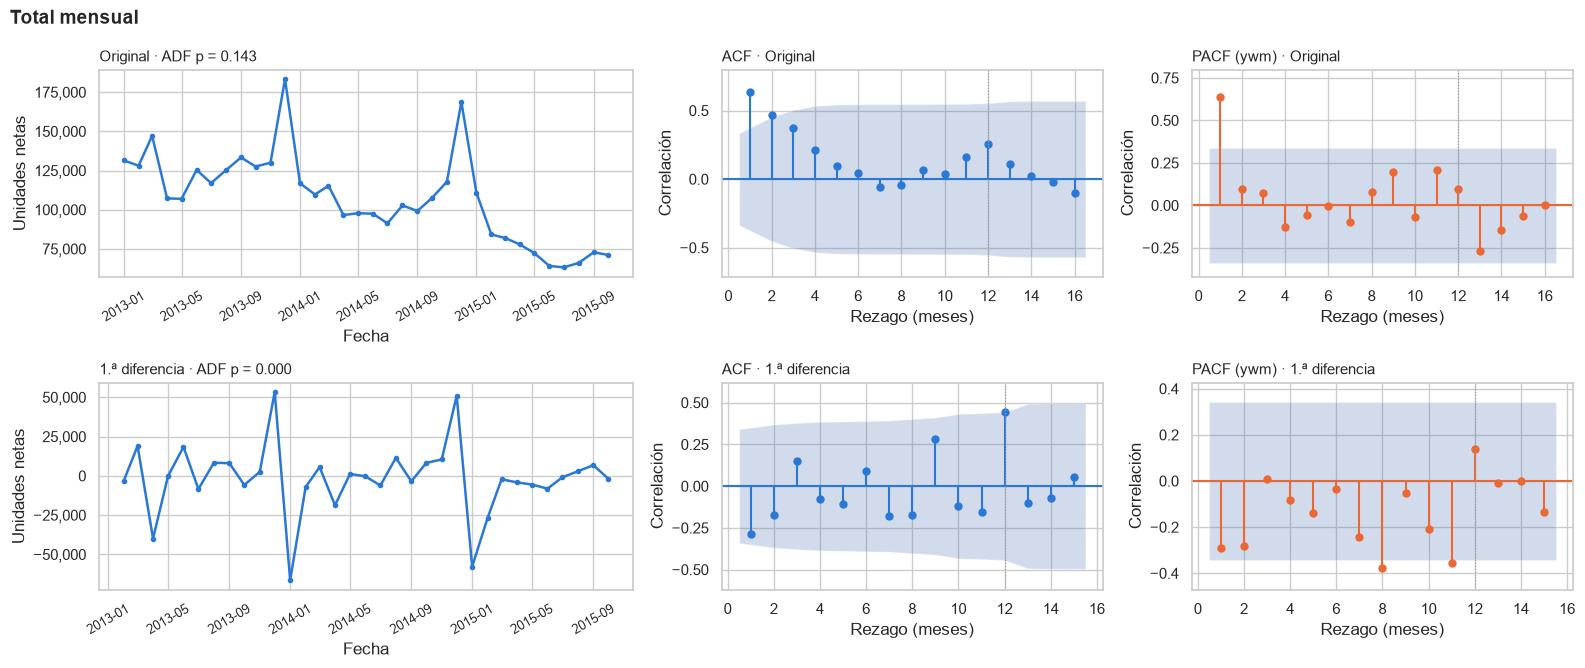

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Total mensual,34,0.1430,No,1-2 (2 de 16),1 (1 de 16),1,0.64,0.26,"Indicio débil (máximo local en 12, no significativo)"
Total mensual (1.ª diferencia),33,0.0000,Sí,12 (1 de 15),"8, 11 (2 de 15)",0,-0.29,0.45,Sí (rezago 12 significativo)


In [71]:
acf_summary += analyze_monthly("Total mensual", SERIES["Total mensual"][1])

**Interpretación**

- **Original:** la ADF no rechaza la raíz unitaria (p = 0.143), coherente con la tendencia descendente. La
  ACF decae lentamente: es significativa en los rezagos 1 y 2 (ACF(1) = 0.64), y la PACF solo en el rezago
  1. Es el patrón de un **AR(1)** sobre una serie con tendencia.
- En el rezago 12 la ACF tiene un máximo local (0.26), pero queda dentro de la banda de confianza.
- **Primera diferencia:** es estacionaria (p < 0.001). Sin la tendencia, la ACF en el rezago 12 sube a 0.45
  y es el único rezago significativo: la estacionalidad anual (diciembre) aparece cuando se elimina la
  tendencia. Los rezagos 8 y 11 significativos en la PACF no siguen un patrón claro y pueden deberse al
  azar, dado el tamaño de la muestra.

**Serie diaria total** (1,034 observaciones, hasta 60 rezagos), con la primera diferencia si no es
estacionaria y la diferencia de 7 días para eliminar el ciclo semanal. Las líneas punteadas marcan los
múltiplos de 7.

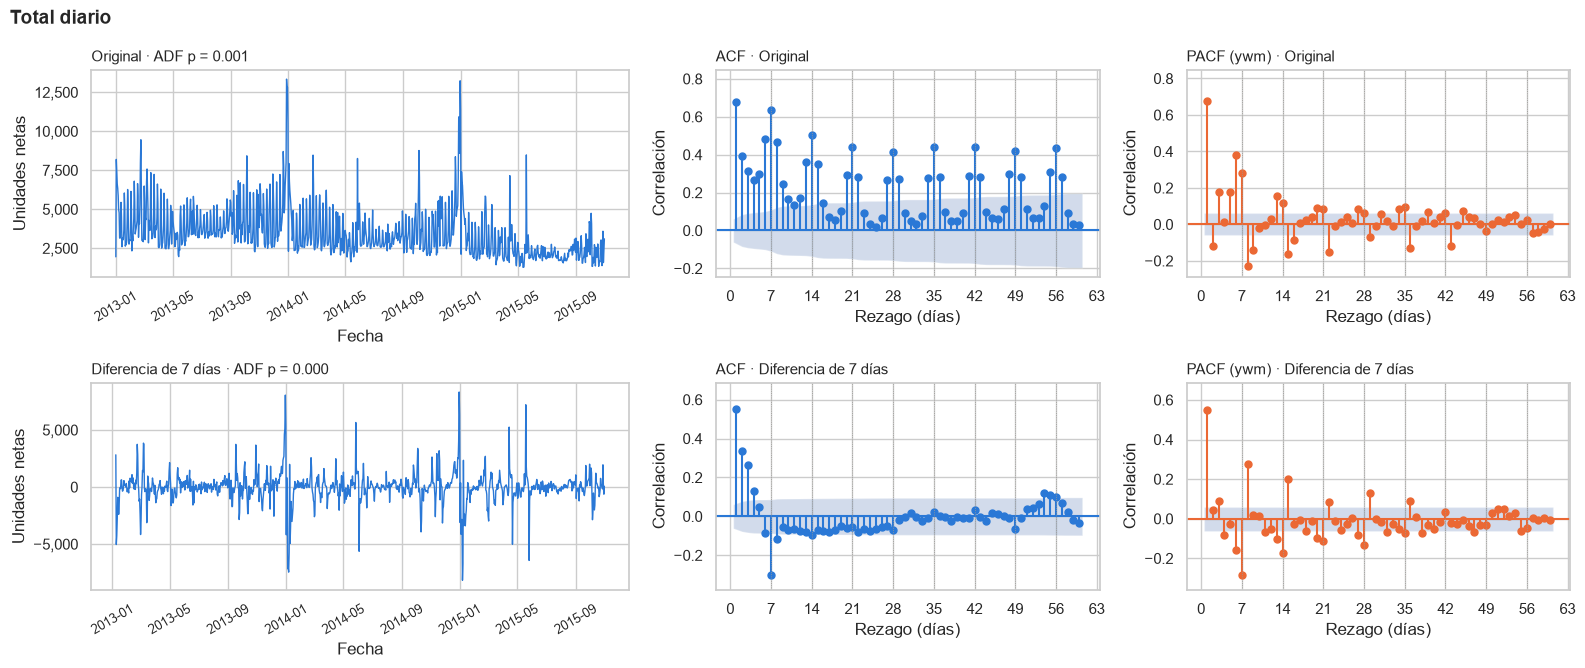

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Total diario,"1,034",0.0012,Sí,"1-15, 20-22, 27-29, 34-36, 41-43, 48-50, 55-57 (33 de 60)","1-3, 5-9, 13-16, 20-22, 27-29, 34-36, 39, 42-43, 45 (25 de 60)",3,0.68,0.64,"Sí, semanal (7, 14, 21, 28 significativos)"
Total diario (diferencia de 7 días),"1,027",0.0000,Sí,"1-4, 7-8, 14, 54-56 (10 de 60)","1, 3-4, 6-8, 11, 13-15, 18, 20-22, 27-29, 32, 35-36, 38, 47, 55 (23 de 60)",1,0.55,-0.30,No; queda correlación negativa en el rezago 7 (efecto de la diferencia)


In [72]:
daily_versions = [("Original", daily_total)]
if adfuller(daily_total, autolag="AIC", result_object=False)[1] >= ALPHA:
    daily_versions.append(("1.ª diferencia", daily_total.diff()))
daily_versions.append(("Diferencia de 7 días", daily_total.diff(7)))
daily_rows = analyze_series("Total diario", "Diaria", daily_versions, nlags_max=60,
                            figure_name="9_acf_pacf_ventas_diarias")
acf_summary += daily_rows
style_table(pd.DataFrame(daily_rows).drop(columns=["Frecuencia"]), {"p-valor ADF": "{:.4f}", "ACF(1)": "{:.2f}", "ACF(7) / ACF(12)": "{:.2f}"})

**Interpretación**

- **Original:** la ADF rechaza la raíz unitaria (p = 0.001). Con 1,034 días, la variación diaria domina
  sobre la tendencia lenta.
- La ACF muestra un **ciclo semanal muy marcado**. ACF(7) = 0.64 es casi igual a ACF(1) = 0.68, y aparecen
  picos en 14, 21, 28… hasta 56, que decaen muy despacio. Son significativos 33 de los 60 rezagos.
- La PACF es significativa en los rezagos 1 a 3 (AR(3) por la regla de corte) y vuelve a crecer en 6 y 7:
  la componente estacional semanal es directa.
- **Diferencia de 7 días:** los picos semanales desaparecen. Queda una memoria corta positiva en los
  rezagos 1 a 4 (ACF(1) = 0.55) y una correlación negativa en el rezago 7 (−0.30), junto con picos
  negativos de la PACF en múltiplos de 7. Es la firma de una componente estacional de media móvil,
  compatible con un modelo del tipo SARIMA(1,0,0)(0,1,1)₇ si se quisiera modelar la serie diaria.

#### Ventas por sucursal

Series mensuales de las 3 tiendas activas con más unidades.

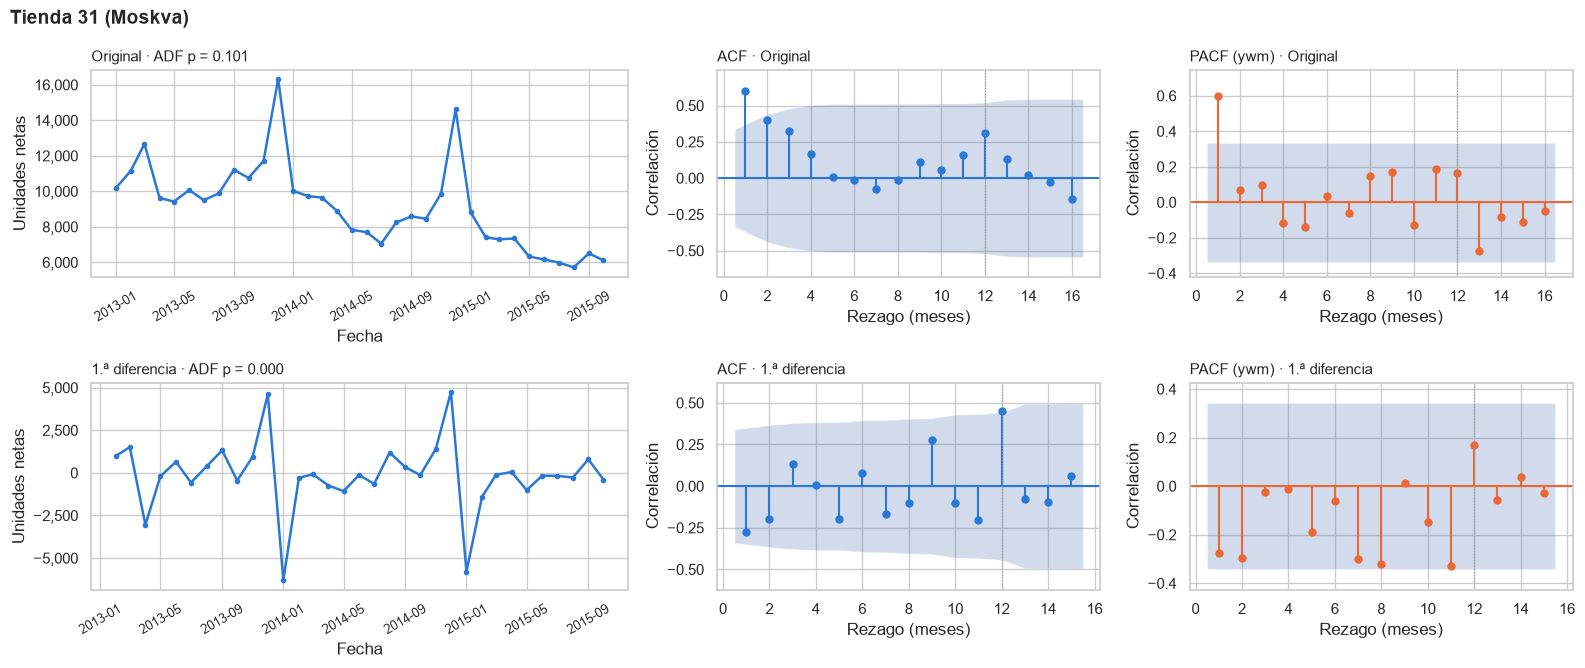

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Tienda 31 (Moskva),34,0.1014,No,1 (1 de 16),1 (1 de 16),1,0.60,0.31,"Indicio débil (máximo local en 12, no significativo)"
Tienda 31 (Moskva) (1.ª diferencia),33,0.0000,Sí,12 (1 de 15),Ninguno,0,-0.28,0.45,Sí (rezago 12 significativo)


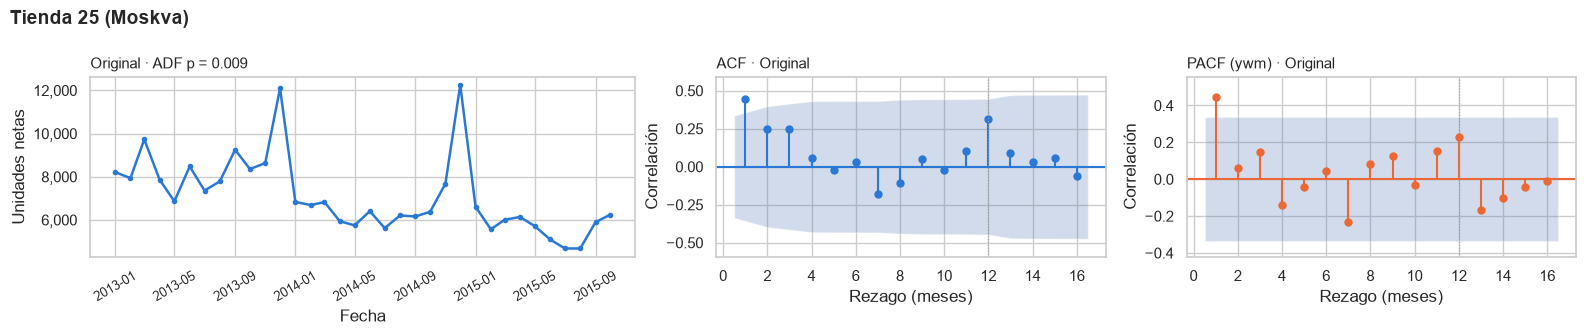

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Tienda 25 (Moskva),34,0.0095,Sí,1 (1 de 16),1 (1 de 16),1,0.44,0.31,"Indicio débil (máximo local en 12, no significativo)"


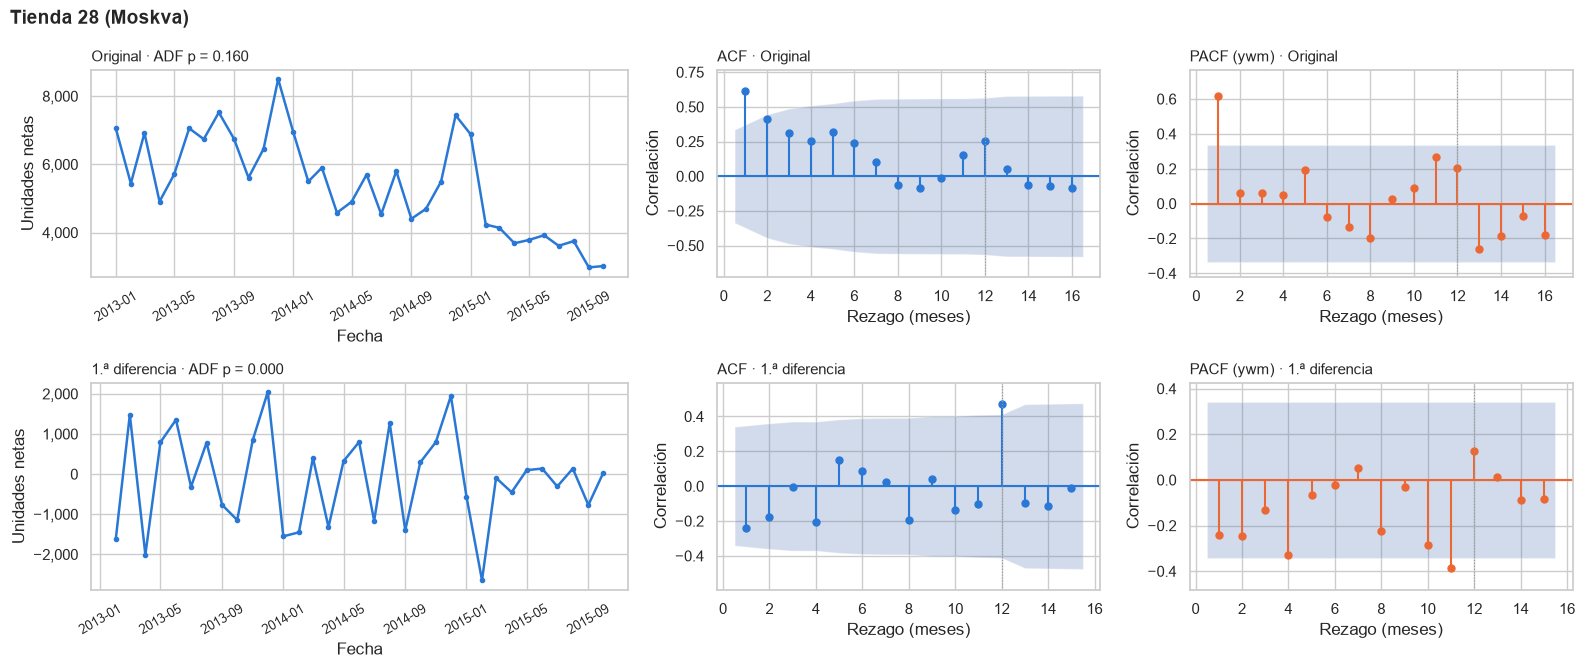

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Tienda 28 (Moskva),34,0.1601,No,1 (1 de 16),1 (1 de 16),1,0.61,0.25,"Indicio débil (máximo local en 12, no significativo)"
Tienda 28 (Moskva) (1.ª diferencia),33,0.0000,Sí,12 (1 de 15),11 (1 de 15),0,-0.24,0.47,Sí (rezago 12 significativo)


In [73]:
for name in [n for n in SERIES if n.startswith("Tienda") and "×" not in n]:
    acf_summary += analyze_monthly(name, SERIES[name][1])

**Interpretación**

- Las tres tiendas repiten la estructura de la serie total: **ACF(1) entre 0.44 y 0.61**, significativa,
  con la PACF cortada en el rezago 1 (AR(1)).
- Las tiendas 31 y 28 no son estacionarias (p = 0.101 y 0.160). La 25 sí lo es (p = 0.010) porque su caída
  en 2015 es más moderada (−9.8 % en unidades enero–octubre, sección 7.b).
- En niveles, el rezago 12 (0.25–0.31) no es significativo. Tras diferenciar, la ACF en el rezago 12 sube
  a 0.45 en la 31 y 0.47 en la 28 y pasa a ser significativa. Las tiendas grandes comparten la
  estacionalidad anual del total.

#### Ventas por producto

Series mensuales de los 3 productos con más unidades (sin la bolsa ni los artículos de servicio).

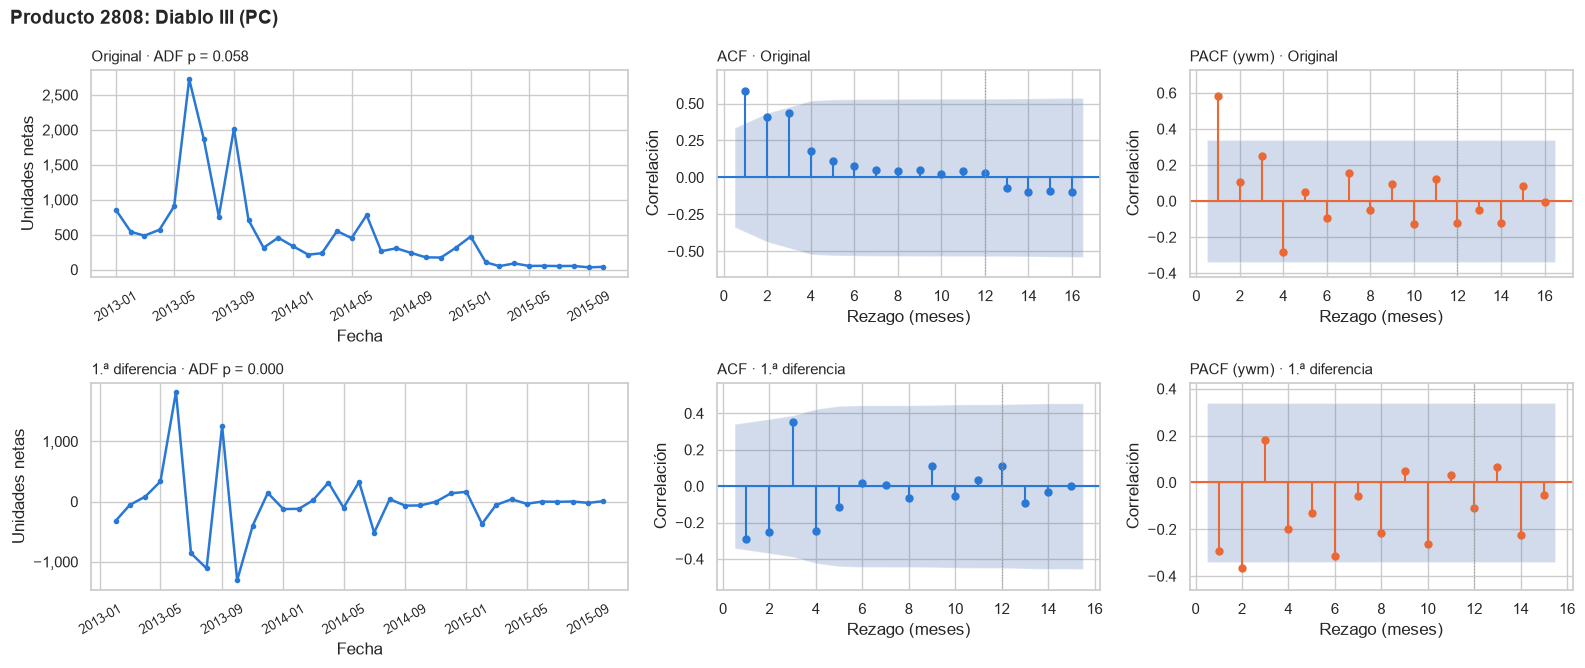

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Producto 2808: Diablo III (PC),34,0.0579,No,1 (1 de 16),1 (1 de 16),1,0.58,0.03,No visible
Producto 2808: Diablo III (PC) (1.ª diferencia),33,0.0000,Sí,Ninguno,2 (1 de 15),0,-0.29,0.11,"Indicio débil (máximo local en 12, no significativo)"


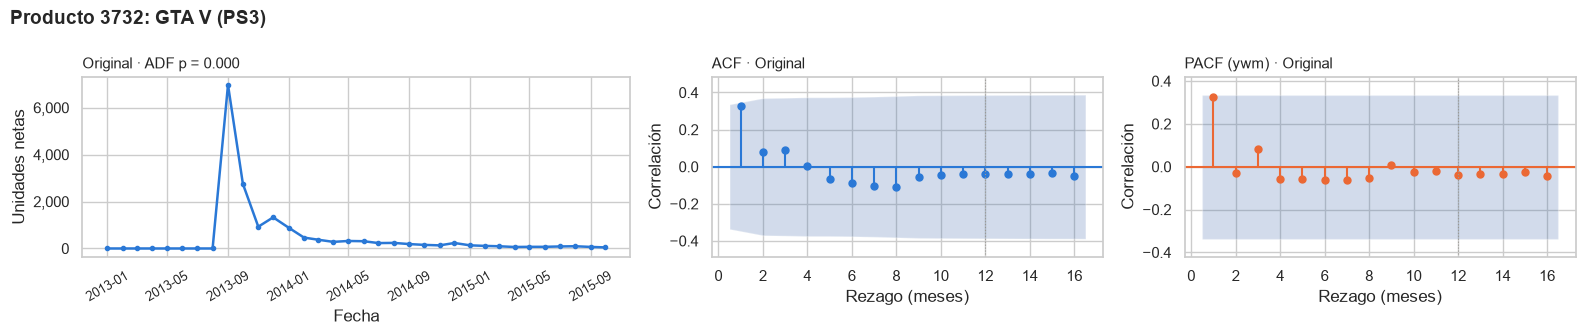

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Producto 3732: GTA V (PS3),34,0.0000,Sí,Ninguno,Ninguno,0,0.32,-0.04,No visible


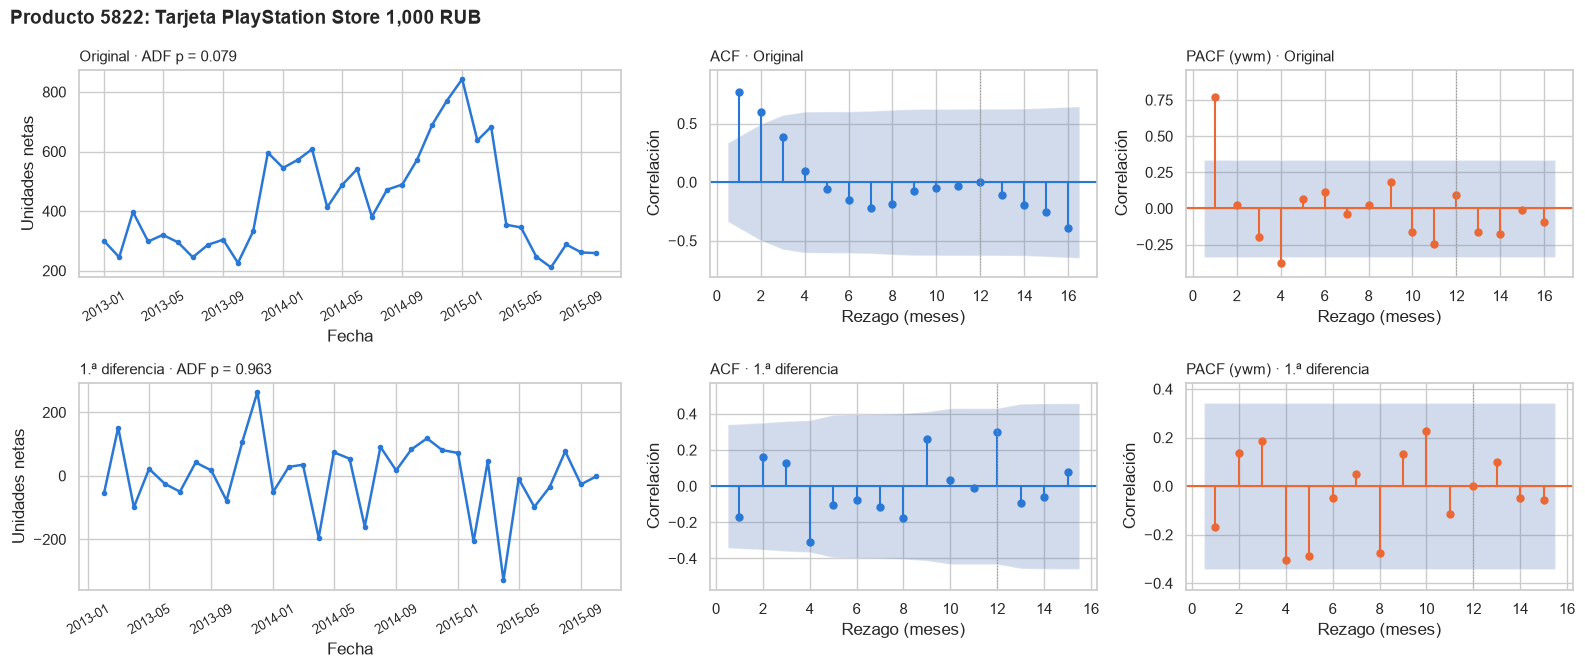

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
"Producto 5822: Tarjeta PlayStation Store 1,000 RUB",34,0.0788,No,1-2 (2 de 16),"1, 4 (2 de 16)",1,0.77,0.00,No visible
"Producto 5822: Tarjeta PlayStation Store 1,000 RUB (1.ª diferencia)",33,0.9627,No,Ninguno,Ninguno,0,-0.17,0.30,"Indicio débil (máximo local en 12, no significativo)"


In [74]:
for name in [n for n in SERIES if n.startswith("Producto")]:
    acf_summary += analyze_monthly(name, SERIES[name][1])

**Interpretación**

- **Diablo III (PC):** tiene ventas los 34 meses, con una lenta caída propia del ciclo de vida del producto.
  ACF(1) = 0.58 es significativa, la PACF se corta en 1 y la ADF queda en el límite (p = 0.058). No hay
  estacionalidad anual (ACF(12) = 0.03).
- **GTA V (PS3):** está dominada por el **ciclo de lanzamiento**: cero hasta agosto de 2013, un pico de casi
  7,000 unidades en septiembre de 2013 y un decaimiento rápido. La ADF la declara estacionaria (p < 0.001)
  porque vuelve a un nivel bajo y estable, y ninguna autocorrelación es significativa (ACF(1) = 0.32, con
  bandas de ±0.34). Un modelo AR no captura este patrón; hacen falta variables de antigüedad del producto.
- **Tarjeta PSN 1,000 RUB:** es la serie con más memoria (ACF(1) = 0.77, rezagos 1 y 2 significativos), por
  su crecimiento hasta diciembre de 2014 y su caída en 2015. En la primera diferencia la ACF y la PACF no
  tienen rezagos significativos (se comporta como ruido), aunque la ADF da p = 0.963. Con 33 observaciones,
  la ADF tiene poca potencia y es sensible al número de rezagos que elige; aquí pesa más la evidencia
  de la ACF.
- Ninguno de los tres productos tiene estacionalidad anual visible: su dinámica la marca el ciclo de vida.

#### Ventas por sucursal-producto

Series mensuales de los 3 pares tienda-producto con más unidades y ventas en la mayoría de los meses.

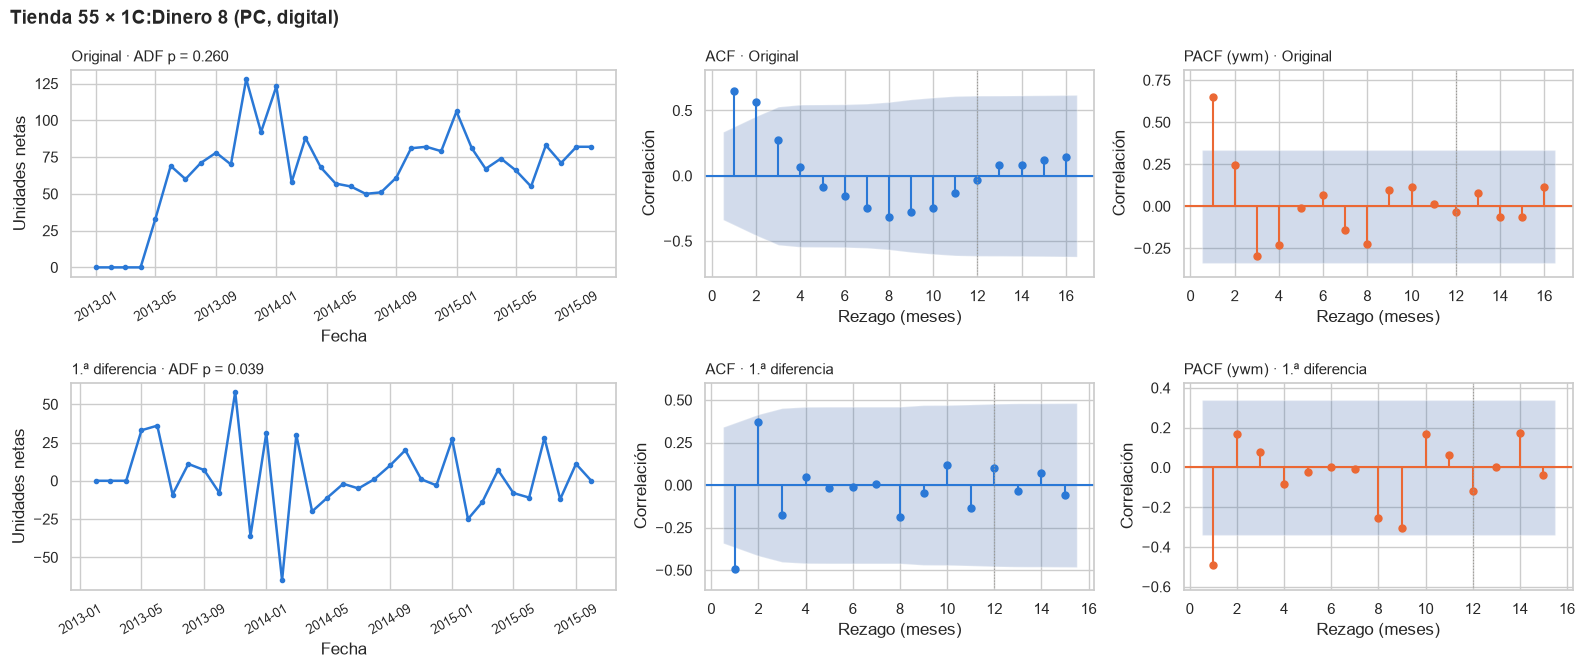

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
"Tienda 55 × 1C:Dinero 8 (PC, digital)",34,0.2598,No,1-2 (2 de 16),1 (1 de 16),1,0.65,-0.03,No visible
"Tienda 55 × 1C:Dinero 8 (PC, digital) (1.ª diferencia)",33,0.0394,Sí,1 (1 de 15),1 (1 de 15),1,-0.49,0.10,No visible


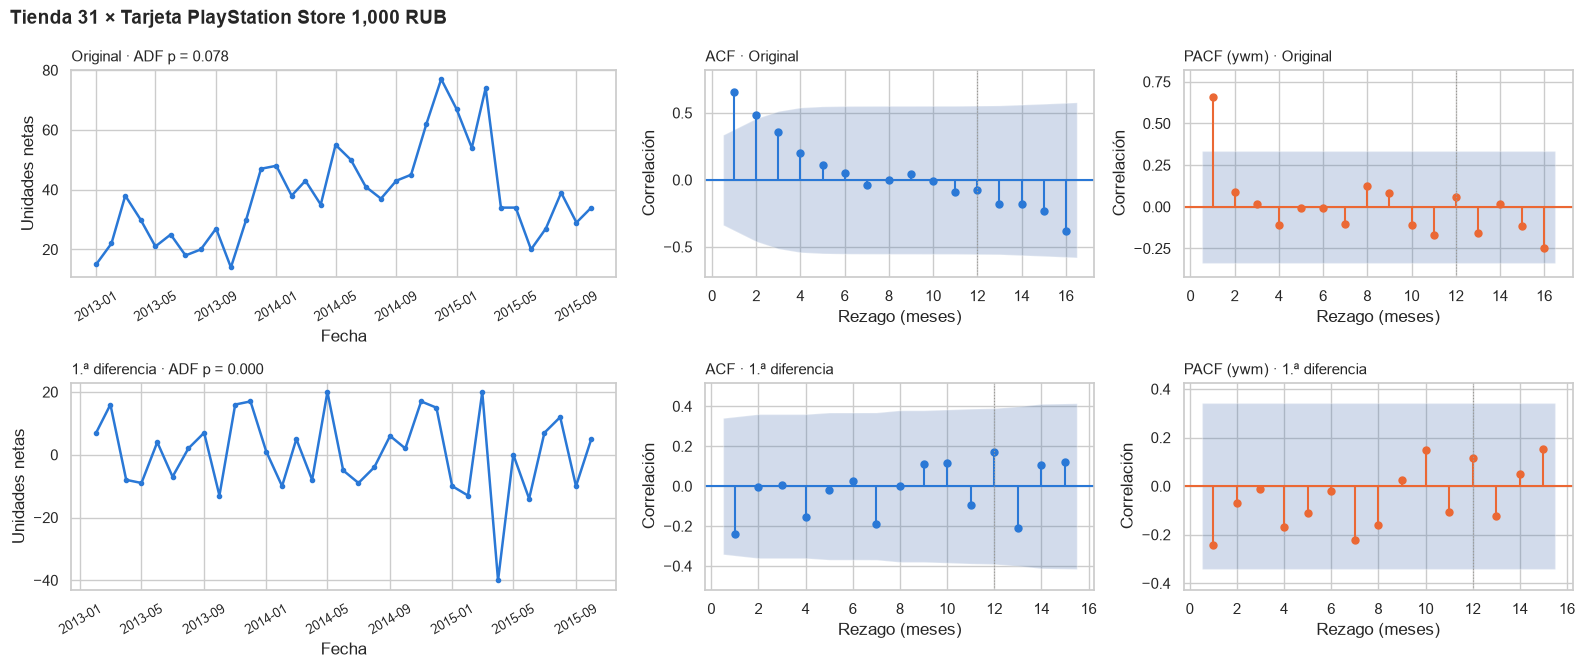

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
"Tienda 31 × Tarjeta PlayStation Store 1,000 RUB",34,0.0784,No,1-2 (2 de 16),1 (1 de 16),1,0.66,-0.08,No visible
"Tienda 31 × Tarjeta PlayStation Store 1,000 RUB (1.ª diferencia)",33,0.0000,Sí,Ninguno,Ninguno,0,-0.24,0.17,"Indicio débil (máximo local en 12, no significativo)"


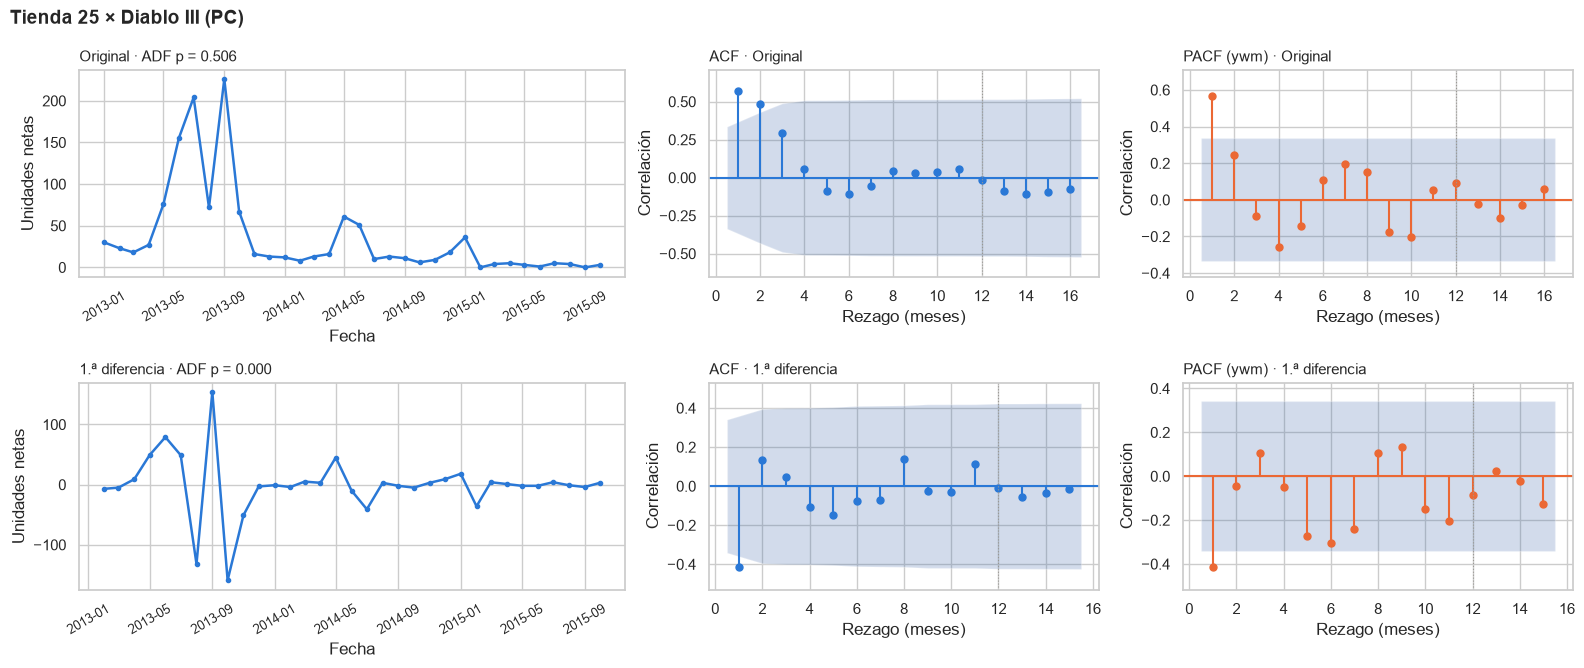

Serie,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Tienda 25 × Diablo III (PC),34,0.5064,No,1-2 (2 de 16),1 (1 de 16),1,0.57,-0.02,No visible
Tienda 25 × Diablo III (PC) (1.ª diferencia),33,0.0000,Sí,1 (1 de 15),1 (1 de 15),1,-0.41,-0.01,No visible


In [75]:
for name in [n for n in SERIES if "×" in n]:
    acf_summary += analyze_monthly(name, SERIES[name][1])

**Interpretación**

- Los tres pares tienda-producto no son estacionarios en niveles (p entre 0.078 y 0.506) y tienen una
  **ACF(1) alta (0.57–0.66)**, con los rezagos 1 y 2 significativos en la ACF y solo el 1 en la PACF: el
  mejor predictor de las ventas de un mes es el mes anterior.
- Al diferenciar, dos pares muestran una ACF(1) **negativa** y significativa (−0.49 en 55 × 1C:Dinero y
  −0.41 en 25 × Diablo III). Es la señal típica de **sobrediferenciación**: la serie oscila alrededor de un
  nivel, y la diferencia introduce una correlación negativa artificial.
- No hay estacionalidad anual a nivel de par (ACF(12) entre −0.08 y −0.02 en niveles). Con ventas mensuales
  pequeñas (entre 35 y 65 unidades al mes de media), el ruido tapa el efecto de diciembre.

#### Tabla resumen

Resultados de todas las series y sus transformaciones. La tabla se guarda en `reports/figures/` como CSV
y como imagen.

In [76]:
acf_summary_table = pd.DataFrame(acf_summary)
acf_summary_table.to_csv(FIGURES_PATH / "9_tabla_resumen_acf_pacf.csv", index=False, encoding="utf-8-sig")

table_display = acf_summary_table.assign(**{
    "p-valor ADF": acf_summary_table["p-valor ADF"].map("{:.4f}".format),
    "ACF(1)": acf_summary_table["ACF(1)"].map("{:.2f}".format),
    "ACF(7) / ACF(12)": acf_summary_table["ACF(7) / ACF(12)"].map("{:.2f}".format),
})
fig, ax = plt.subplots(figsize=(24, 0.32 * (len(table_display) + 1)))
ax.axis("off")
table = ax.table(cellText=table_display.values, colLabels=table_display.columns, cellLoc="left",
                 colLoc="left", bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.auto_set_column_width(list(range(table_display.shape[1])))
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#d9d8d4")
    if row == 0:
        cell.set_facecolor("#cde2fb")
        cell.set_text_props(fontweight="bold")
ax.set_title("Resumen de ACF, PACF y prueba ADF por serie", fontsize=14, fontweight="bold", loc="left")
plt.tight_layout()
save_figure(fig, "9_tabla_resumen_acf_pacf")
plt.close(fig)

print("Guardado:", (FIGURES_PATH / "9_tabla_resumen_acf_pacf.csv").as_posix(), "y",
      saved_figures[-1].as_posix())
style_table(acf_summary_table, {"p-valor ADF": "{:.4f}", "ACF(1)": "{:.2f}", "ACF(7) / ACF(12)": "{:.2f}"})

Guardado: ../reports/figures/9_tabla_resumen_acf_pacf.csv y ../reports/figures/9_tabla_resumen_acf_pacf.png


Serie,Frecuencia,Obs.,p-valor ADF,¿Estacionaria?,Rezagos significativos ACF,Rezagos significativos PACF,Orden AR sugerido,ACF(1),ACF(7) / ACF(12),¿Estacionalidad visible?
Total mensual,Mensual,34,0.1430,No,1-2 (2 de 16),1 (1 de 16),1,0.64,0.26,"Indicio débil (máximo local en 12, no significativo)"
Total mensual (1.ª diferencia),Mensual,33,0.0000,Sí,12 (1 de 15),"8, 11 (2 de 15)",0,-0.29,0.45,Sí (rezago 12 significativo)
Total diario,Diaria,"1,034",0.0012,Sí,"1-15, 20-22, 27-29, 34-36, 41-43, 48-50, 55-57 (33 de 60)","1-3, 5-9, 13-16, 20-22, 27-29, 34-36, 39, 42-43, 45 (25 de 60)",3,0.68,0.64,"Sí, semanal (7, 14, 21, 28 significativos)"
Total diario (diferencia de 7 días),Diaria,"1,027",0.0000,Sí,"1-4, 7-8, 14, 54-56 (10 de 60)","1, 3-4, 6-8, 11, 13-15, 18, 20-22, 27-29, 32, 35-36, 38, 47, 55 (23 de 60)",1,0.55,-0.30,No; queda correlación negativa en el rezago 7 (efecto de la diferencia)
Tienda 31 (Moskva),Mensual,34,0.1014,No,1 (1 de 16),1 (1 de 16),1,0.60,0.31,"Indicio débil (máximo local en 12, no significativo)"
Tienda 31 (Moskva) (1.ª diferencia),Mensual,33,0.0000,Sí,12 (1 de 15),Ninguno,0,-0.28,0.45,Sí (rezago 12 significativo)
Tienda 25 (Moskva),Mensual,34,0.0095,Sí,1 (1 de 16),1 (1 de 16),1,0.44,0.31,"Indicio débil (máximo local en 12, no significativo)"
Tienda 28 (Moskva),Mensual,34,0.1601,No,1 (1 de 16),1 (1 de 16),1,0.61,0.25,"Indicio débil (máximo local en 12, no significativo)"
Tienda 28 (Moskva) (1.ª diferencia),Mensual,33,0.0000,Sí,12 (1 de 15),11 (1 de 15),0,-0.24,0.47,Sí (rezago 12 significativo)
Producto 2808: Diablo III (PC),Mensual,34,0.0579,No,1 (1 de 16),1 (1 de 16),1,0.58,0.03,No visible


### 9.b Interpretación

**i. ¿Existen correlaciones significativas en distintos rezagos?**

- **Sí, sobre todo en el rezago 1.**
  - **Mensuales:** 9 de las 10 series mensuales tienen una ACF(1) significativa, entre 0.44 y 0.77 (la
    excepción es GTA V, por su pico de lanzamiento). La PACF se corta casi siempre en el rezago 1 (orden
    AR sugerido = 1), y el rezago 2 solo aparece en la ACF como efecto indirecto del 1.
  - **Diaria:** la memoria es mucho más larga. Hay correlaciones significativas en 33 de 60 rezagos de la
    ACF y en 25 de la PACF, concentradas en los rezagos 1 a 3 y en los múltiplos de 7.
- **Por nivel de agregación:** el total y las tiendas tienen la estructura más estable (AR(1) más
  estacionalidad anual tras diferenciar). Los productos dependen de su ciclo de vida, y los pares
  tienda-producto tienen memoria de 1 o 2 meses pero sin estacionalidad.
- Más allá del rezago 2, las series mensuales casi no tienen correlaciones significativas. Las aisladas
  (rezagos 4, 8 u 11 en alguna PACF) son esperables por azar con 15 o 16 rezagos analizados.

**ii. ¿Se observa estacionalidad en patrones repetitivos?**

- **Semanal (serie diaria): sí, y muy fuerte.** Los rezagos 7, 14, 21 y 28 son significativos, con ACF(7)
  = 0.64, y desaparecen con la diferencia de 7 días. Confirma el ciclo de fin de semana de la sección 6.
- **Anual (rezago 12, series mensuales): solo en las series agregadas y tras eliminar la tendencia.** En el
  total y en las tiendas 31 y 28, la ACF(12) de la primera diferencia es significativa (0.45–0.47). En
  niveles es un máximo local no significativo (0.25–0.31). En productos y pares no se observa.
- **Con 34 meses el rezago 12 apenas se puede evaluar:**
  - solo hay 22 pares de observaciones separadas 12 meses y solo dos ciclos anuales completos (dos
    diciembres);
  - la banda de Bartlett se ensancha con los rezagos anteriores y en el rezago 12 supera ±0.4, así que
    solo correlaciones muy fuertes resultan significativas;
  - la PACF solo puede calcularse hasta el rezago 16 y su estimación en 12 es muy inestable.
  La ausencia de significación en el rezago 12 no prueba que no haya estacionalidad: indica falta de
  potencia. La descomposición (sección 6) y el perfil mensual sí la muestran con claridad.

**Implicaciones para el modelo de forecasting**

- **Rezagos útiles como variables:**
  - **Rezago 1** de `item_cnt_month` (el más informativo en todos los niveles).
  - **Rezagos 2 y 3**, que aportan algo de memoria adicional y suavizan el ruido del rezago 1.
  - **Rezago 12**, útil sobre todo en variables agregadas (ventas de la tienda, de la categoría o
    totales del mismo mes del año anterior), porque a nivel de par apenas tiene señal. Para noviembre de
    2015 equivale a usar noviembre de 2014.
- **Diferenciación:** no conviene diferenciar el objetivo a nivel tienda-producto. Las series ya tienen una
  media estable en el corto plazo, y diferenciar provoca sobrediferenciación (ACF(1) negativa). Es mejor
  trabajar en niveles con rezagos y añadir variables que capturen la tendencia: medias móviles recientes,
  la variación del último mes y la tendencia de la tienda o la categoría. Si se usa un modelo clásico
  (ARIMA/SARIMA) sobre series agregadas, sí procede d = 1 con un término estacional de periodo 12.
- **Ciclo de vida del producto:** como GTA V muestra, las ventas de un producto dependen de su lanzamiento
  más que de sus rezagos. Conviene añadir los meses desde la primera venta y si el producto es nuevo en el
  mes a predecir.
- **Ciclo semanal:** no se usa directamente porque el objetivo es mensual, pero puede resumirse en el
  número de fines de semana del mes.

## 10. Insights y conclusiones del EDA

### 10.a Variables que afectan directamente las ventas

#### Grilla mensual tienda-producto

Se construye la grilla con la que se modelará `item_cnt_month`: para cada mes, todas las combinaciones de
tiendas y productos con ventas en ese mes, con 0 en los pares sin ventas. Así se replica la estructura de
`test.csv`, que incluye pares sin ventas. El objetivo se recorta a [0, 20], como recomienda la sección 7.c,
y se añaden las variables candidatas:

- **Rezagos 1 y 12** del objetivo del mismo par.
- **Precio medio del producto:** mediana de sus precios válidos en todo el histórico.
- **Antigüedad del producto:** meses desde su primera venta.
- **Categoría principal.**
- **Tamaño de la tienda:** unidades medias por mes activo.
- **Mes del año.**

In [77]:
sales_grid = load_parquet(ENRICHED_SALES_FILE)
KEYS = ["date_block_num", "shop_id", "item_id"]

grid = pd.concat(
    [
        pd.MultiIndex.from_product([[block], frame["shop_id"].unique(), frame["item_id"].unique()],
                                   names=KEYS).to_frame(index=False)
        for block, frame in sales_grid.groupby("date_block_num")
    ],
    ignore_index=True,
)
monthly_target = sales_grid.groupby(KEYS)["item_cnt_day"].sum().rename("item_cnt_month").reset_index()
grid = grid.merge(monthly_target, on=KEYS, how="left")
grid["item_cnt_month"] = grid["item_cnt_month"].fillna(0).clip(0, 20).astype("int8")

for lag in (1, 12):
    lagged = grid[KEYS + ["item_cnt_month"]].assign(date_block_num=lambda d: d["date_block_num"] + lag)
    grid = grid.merge(lagged.rename(columns={"item_cnt_month": f"lag_{lag}"}), on=KEYS, how="left")
    grid[f"lag_{lag}"] = grid[f"lag_{lag}"].fillna(0).astype("int8")

item_first_block = sales_grid.groupby("item_id")["date_block_num"].min()
item_price = sales_grid.groupby("item_id")["item_price"].median()
item_category = sales_grid.drop_duplicates("item_id").set_index("item_id")["categoria_principal"]
shop_size = shop_performance.set_index("shop_id")["Unidades por mes"]

grid["item_age"] = (grid["date_block_num"] - grid["item_id"].map(item_first_block)).astype("int8")
grid["item_price"] = grid["item_id"].map(item_price)
grid["categoria_principal"] = grid["item_id"].map(item_category)
grid["shop_size"] = grid["shop_id"].map(shop_size)
grid["month"] = (grid["date_block_num"] % 12 + 1).astype("int8")

style_table(pd.DataFrame({
    "Métrica": ["Filas de la grilla (pares tienda-producto-mes)", "Pares con ventas (item_cnt_month > 0)",
                "Media de item_cnt_month (recortado)", "Memoria (MB)"],
    "Valor": [f"{len(grid):,}", f"{(grid['item_cnt_month'] > 0).mean():.1%}",
              f"{grid['item_cnt_month'].mean():.3f}", f"{memory_mb(grid):,.0f}"],
}))

Métrica,Valor
Filas de la grilla (pares tienda-producto-mes),"10,913,850"
Pares con ventas (item_cnt_month > 0),14.7%
Media de item_cnt_month (recortado),0.298
Memoria (MB),343


#### Relación de las variables con `item_cnt_month`

Correlación de Spearman para las variables numéricas, porque el objetivo está concentrado en 0 y es muy
asimétrico. El rezago 1 se evalúa desde el mes 1 y el rezago 12 desde el mes 12, para que siempre haya
historial. Para las variables categóricas se comparan medias por grupo.

In [78]:
def spearman(frame: pd.DataFrame, column: str) -> float:
    return frame["item_cnt_month"].corr(frame[column], method="spearman")


numeric_relations = pd.DataFrame([
    {"Variable": "Rezago 1 (lag_1)", "Meses evaluados": "1–33", "Spearman": spearman(grid[grid["date_block_num"] >= 1], "lag_1")},
    {"Variable": "Rezago 12 (lag_12)", "Meses evaluados": "12–33", "Spearman": spearman(grid[grid["date_block_num"] >= 12], "lag_12")},
    {"Variable": "Precio medio del producto", "Meses evaluados": "0–33", "Spearman": spearman(grid, "item_price")},
    {"Variable": "Antigüedad del producto (meses)", "Meses evaluados": "0–33", "Spearman": spearman(grid, "item_age")},
    {"Variable": "Tamaño de la tienda (unidades por mes)", "Meses evaluados": "0–33", "Spearman": spearman(grid, "shop_size")},
])
display(style_table(numeric_relations, {"Spearman": "{:+.3f}"}))

lag1_groups = grid[grid["date_block_num"] >= 1].groupby(grid["lag_1"] > 0)["item_cnt_month"].agg(["mean", lambda s: (s > 0).mean()])
age_groups = grid.groupby(pd.cut(grid["item_age"], bins=[-1, 0, 2, 5, 11, 33],
                                 labels=["Mes de lanzamiento (0)", "1–2", "3–5", "6–11", "12 o más"]),
                          observed=True)["item_cnt_month"].mean()
size_groups = grid.groupby(pd.qcut(grid["shop_size"], 4, labels=["Q1 (pequeñas)", "Q2", "Q3", "Q4 (grandes)"]),
                           observed=True)["item_cnt_month"].mean()
month_groups = grid.groupby(np.select([grid["month"] == 12, grid["month"] == 11], ["Diciembre", "Noviembre"],
                                      default="Resto de meses"))["item_cnt_month"].mean()
category_groups = grid.groupby("categoria_principal", observed=True)["item_cnt_month"].mean().sort_values(ascending=False)

group_relations = pd.concat([
    pd.DataFrame({"Variable": "Rezago 1", "Grupo": ["lag_1 = 0", "lag_1 > 0"], "Media item_cnt_month": lag1_groups["mean"].values,
                  "% con ventas": lag1_groups["<lambda_0>"].values * 100}),
    pd.DataFrame({"Variable": "Antigüedad", "Grupo": age_groups.index.astype(str), "Media item_cnt_month": age_groups.values}),
    pd.DataFrame({"Variable": "Tamaño de tienda", "Grupo": size_groups.index.astype(str), "Media item_cnt_month": size_groups.values}),
    pd.DataFrame({"Variable": "Mes del año", "Grupo": month_groups.index, "Media item_cnt_month": month_groups.values}),
    pd.DataFrame({"Variable": "Categoría principal", "Grupo": category_groups.index.astype(str),
                  "Media item_cnt_month": category_groups.values}),
], ignore_index=True)
style_table(group_relations, {"Media item_cnt_month": "{:.3f}", "% con ventas": "{:.1f}"})

Variable,Meses evaluados,Spearman
Rezago 1 (lag_1),1–33,+0.379
Rezago 12 (lag_12),12–33,+0.151
Precio medio del producto,0–33,+0.083
Antigüedad del producto (meses),0–33,-0.083
Tamaño de la tienda (unidades por mes),0–33,+0.177


Variable,Grupo,Media item_cnt_month,% con ventas
Rezago 1,lag_1 = 0,0.152,9.6
Rezago 1,lag_1 > 0,1.170,45.2
Antigüedad,Mes de lanzamiento (0),0.516,—
Antigüedad,1–2,0.514,—
Antigüedad,3–5,0.295,—
Antigüedad,6–11,0.241,—
Antigüedad,12 o más,0.202,—
Tamaño de tienda,Q1 (pequeñas),0.145,—
Tamaño de tienda,Q2,0.224,—
Tamaño de tienda,Q3,0.264,—


**Interpretación**

- La grilla tiene 10,913,850 combinaciones tienda-producto-mes. Solo el 14.7 % tiene ventas, y la media de
  `item_cnt_month` recortado es 0.298: el objetivo está dominado por ceros.
- **El rezago 1 es la variable más relacionada** (Spearman +0.379). Si el par vendió el mes anterior, la
  media del mes es 1.170 y el 45.2 % vuelve a vender; si no vendió, la media cae a 0.152 y solo el 9.6 %
  vende.
- **Tamaño de la tienda:** Spearman +0.177. Las tiendas del cuartil grande venden unas 4 veces más por par
  (0.592) que las del pequeño (0.145).
- **Rezago 12:** la relación es débil a nivel par (+0.151), como ya indicaba la ACF de la sección 9.
- **Antigüedad del producto:** el Spearman es bajo (−0.083), pero la relación no es lineal. La media es de
  0.516 en el mes de lanzamiento y de 0.514 en los dos meses siguientes, y cae a 0.202 con 12 meses o más.
  Las ventas se concentran en los primeros meses de vida del producto.
- **Categoría principal:** hay grandes diferencias. Tarjetas de pago (1.705) y Otros (1.402, por los
  servicios) tienen la media más alta por par, seguidas de Videojuegos (0.651). Libros (0.130) y Música
  (0.173) son las más bajas.
- **Mes del año:** diciembre eleva la media a 0.426, un 48 % más que el resto de meses (0.288). Noviembre se
  sitúa algo por encima (0.307, +6.6 %).
- **Precio:** apenas se relaciona con las unidades (+0.083).

#### Tabla final de variables

Resumen de las variables con efecto directo sobre las ventas, la evidencia que lo respalda y su uso
recomendado en el modelo.

In [79]:
def group_mean(variable: str, group: str) -> float:
    row = group_relations[(group_relations["Variable"] == variable) & (group_relations["Grupo"] == group)]
    return float(row["Media item_cnt_month"].iloc[0])


def rho(variable_prefix: str) -> float:
    return float(numeric_relations.loc[numeric_relations["Variable"].str.startswith(variable_prefix), "Spearman"].iloc[0])


variable_table = pd.DataFrame([
    ("Rezago 1 de item_cnt_month", f"Spearman {rho('Rezago 1'):+.2f}; media {group_mean('Rezago 1', 'lag_1 > 0'):.2f} si vendió el mes anterior frente a "
     f"{group_mean('Rezago 1', 'lag_1 = 0'):.2f}; ACF(1) de 0.44–0.77", "6.b.i, 9, 10.a",
     "Variable principal; añadir también rezagos 2 y 3 y medias móviles"),
    ("Rezago 12 de item_cnt_month", f"Spearman {rho('Rezago 12'):+.2f} a nivel par; ACF(12) significativa solo en series agregadas",
     "6.b.ii, 9, 10.a", "Usar sobre todo en agregados (tienda, categoría) del mismo mes del año anterior"),
    ("Antigüedad del producto", f"Spearman {rho('Antigüedad'):+.2f}; media {group_mean('Antigüedad', 'Mes de lanzamiento (0)'):.2f} en el mes de lanzamiento frente a "
     f"{group_mean('Antigüedad', '12 o más'):.2f} con 12 meses o más", "6.b.iii, 7.a, 9, 10.a",
     "Meses desde la primera venta e indicador de producto nuevo"),
    ("Tamaño de la tienda", f"Spearman {rho('Tamaño'):+.2f}; media {group_mean('Tamaño de tienda', 'Q4 (grandes)'):.2f} en el cuartil grande frente a "
     f"{group_mean('Tamaño de tienda', 'Q1 (pequeñas)'):.2f} en el pequeño", "5.b.ii, 7.b, 10.a",
     "Media histórica y reciente de ventas de la tienda; indicador de tienda online"),
    ("Categoría principal", f"Media de {category_groups.iloc[0]:.2f} en {category_groups.index[0]} frente a "
     f"{category_groups.iloc[-1]:.2f} en {category_groups.index[-1]}", "5.b.i, 7.a, 8.d, 10.a",
     "Categoría y subcategoría codificadas, con medias históricas por categoría y tendencia de su mezcla"),
    ("Mes del año (noviembre / diciembre)", f"Media de {group_mean('Mes del año', 'Noviembre'):.3f} en noviembre y "
     f"{group_mean('Mes del año', 'Diciembre'):.3f} en diciembre frente a {group_mean('Mes del año', 'Resto de meses'):.3f}; índice estacional de noviembre 1.092",
     "6.b.ii, 10.a", "Mes del año y número de fines de semana del mes"),
    ("Precio medio del producto", f"Spearman {rho('Precio'):+.2f}: relación débil, confundida con la categoría "
     "(los videojuegos son caros y se venden más por par)", "5.a, 7.c, 10.a",
     "Variable secundaria: precio robusto (mediana) por producto, combinado con la categoría; nunca el precio crudo"),
], columns=["Variable", "Evidencia (cifra)", "Sección", "Uso recomendado en el modelo"])
style_table(variable_table)

Variable,Evidencia (cifra),Sección,Uso recomendado en el modelo
Rezago 1 de item_cnt_month,Spearman +0.38; media 1.17 si vendió el mes anterior frente a 0.15; ACF(1) de 0.44–0.77,"6.b.i, 9, 10.a",Variable principal; añadir también rezagos 2 y 3 y medias móviles
Rezago 12 de item_cnt_month,Spearman +0.15 a nivel par; ACF(12) significativa solo en series agregadas,"6.b.ii, 9, 10.a","Usar sobre todo en agregados (tienda, categoría) del mismo mes del año anterior"
Antigüedad del producto,Spearman -0.08; media 0.52 en el mes de lanzamiento frente a 0.20 con 12 meses o más,"6.b.iii, 7.a, 9, 10.a",Meses desde la primera venta e indicador de producto nuevo
Tamaño de la tienda,Spearman +0.18; media 0.59 en el cuartil grande frente a 0.15 en el pequeño,"5.b.ii, 7.b, 10.a",Media histórica y reciente de ventas de la tienda; indicador de tienda online
Categoría principal,Media de 1.70 en Tarjetas de pago frente a 0.13 en Libros,"5.b.i, 7.a, 8.d, 10.a","Categoría y subcategoría codificadas, con medias históricas por categoría y tendencia de su mezcla"
Mes del año (noviembre / diciembre),Media de 0.307 en noviembre y 0.426 en diciembre frente a 0.288; índice estacional de noviembre 1.092,"6.b.ii, 10.a",Mes del año y número de fines de semana del mes
Precio medio del producto,"Spearman +0.08: relación débil, confundida con la categoría (los videojuegos son caros y se venden más por par)","5.a, 7.c, 10.a","Variable secundaria: precio robusto (mediana) por producto, combinado con la categoría; nunca el precio crudo"


**Interpretación**

- Por orden de importancia, las variables con más evidencia son el **historial reciente del par** (rezago
  1 y siguientes), el **tamaño o nivel de la tienda**, la **categoría** y la **antigüedad del producto**.
- La estacionalidad (diciembre y, en menor medida, noviembre) y el rezago 12 aportan sobre todo a nivel
  agregado.
- El precio es una variable secundaria: su efecto se mezcla con el de la categoría.
- Todas las variables pueden construirse con información disponible al cierre de octubre de 2015, sin usar
  datos del mes a predecir.

### 10.b Patrones útiles para el forecasting y cobertura de `test.csv`

#### Cobertura de `test.csv`

Cada par tienda-producto de `test.csv` se clasifica en tres grupos: con historial (el par vendió alguna vez
en train), producto conocido pero nuevo para esa tienda, y producto que nunca se vendió.

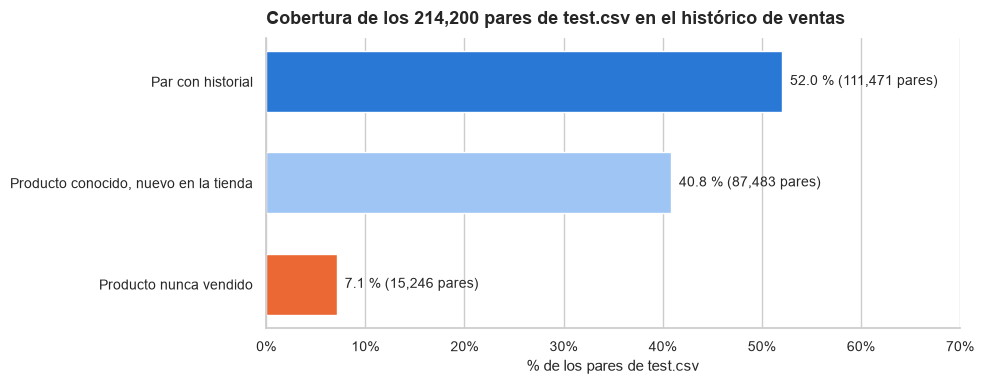

Grupo,Pares,Productos distintos,% de los pares de test
Par con historial,"111,471","4,716",52.0
"Producto conocido, nuevo en la tienda","87,483","4,737",40.8
Producto nunca vendido,"15,246",363,7.1


In [80]:
train_pairs = set(zip(sales_grid["shop_id"], sales_grid["item_id"]))
train_items = set(sales_grid["item_id"])
test_cov = test.copy()
test_cov["has_history"] = [pair in train_pairs for pair in zip(test_cov["shop_id"], test_cov["item_id"])]
test_cov["Grupo"] = np.select(
    [test_cov["has_history"], test_cov["item_id"].isin(train_items)],
    ["Par con historial", "Producto conocido, nuevo en la tienda"], default="Producto nunca vendido",
)
coverage = (
    test_cov.groupby("Grupo").agg(pairs=("ID", "size"), items=("item_id", "nunique"))
    .reindex(["Par con historial", "Producto conocido, nuevo en la tienda", "Producto nunca vendido"])
    .reset_index()
)
coverage["% de los pares de test"] = coverage["pairs"] / len(test_cov) * 100

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(coverage["Grupo"][::-1], coverage["% de los pares de test"][::-1],
               color=[UNITS_COLOR, "#9ec5f4", REVENUE_COLOR][::-1], height=0.6)
for bar, (_, row) in zip(bars, coverage[::-1].iterrows()):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  {row['% de los pares de test']:.1f} % ({row['pairs']:,} pares)", va="center", fontsize=10)
style_axis(ax, "Cobertura de los 214,200 pares de test.csv en el histórico de ventas", "% de los pares de test.csv", "")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 70)
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_figure(fig, "10b_cobertura_test")
plt.show()

style_table(coverage.rename(columns={"pairs": "Pares", "items": "Productos distintos"}),
            {"% de los pares de test": "{:.1f}"})

**Interpretación**

- `test.csv` cruza las 42 tiendas con 5,100 productos (214,200 pares). Solo el **52.0 %** de los pares
  (111,471) vendió alguna vez en esa tienda.
- El **40.8 %** (87,483 pares) son productos conocidos pero que nunca se vendieron en esa tienda. Para ellos
  no hay historial propio, pero sí del producto en otras tiendas.
- El **7.1 %** (15,246 pares, que corresponden a 363 productos) son productos que no aparecen en ningún
  registro de train: lanzamientos de noviembre de 2015.
- Casi la mitad de los pares carecen de historial propio. El modelo debe apoyarse en información del
  producto en otras tiendas, de la categoría y de la tienda, y predecir muchos ceros.

**Productos nuevos y actividad reciente.** Categorías de los productos de `test.csv` que nunca se vendieron
(lanzamientos de noviembre), actividad reciente de los pares con historial y comprobación de las tiendas
de `test.csv`.

In [81]:
new_items = items[items["item_id"].isin(test_cov.loc[test_cov["Grupo"] == "Producto nunca vendido", "item_id"])]
new_items = new_items.assign(Subcategoría=new_items["item_category_id"].map(SUBCATEGORY_TRANSLATION))
new_by_subcategory = new_items["Subcategoría"].value_counts().head(10).rename("Productos nuevos").reset_index()
new_by_subcategory["% de los productos nuevos"] = new_by_subcategory["Productos nuevos"] / len(new_items) * 100
print(f"Productos nunca vendidos en test.csv: {len(new_items):,}")
display(style_table(new_by_subcategory, {"% de los productos nuevos": "{:.1f}"}))

pair_last_block = sales_grid.groupby(["shop_id", "item_id"])["date_block_num"].max()
history_pairs = test_cov[test_cov["has_history"]]
last_blocks = pd.Series([pair_last_block[pair] for pair in zip(history_pairs["shop_id"], history_pairs["item_id"])])
test_shops = set(test["shop_id"])
october_shops = set(sales_grid.loc[sales_grid["date_block_num"] == 33, "shop_id"])
closed_shops = set(shop_performance.loc[shop_performance["Vende en oct-2015"] == "No", "shop_id"])

style_table(pd.DataFrame({
    "Verificación": ["Pares con historial que vendieron en octubre de 2015",
                     "Pares con historial que vendieron en los últimos 3 meses (ago–oct 2015)",
                     "Pares con historial sin ventas desde hace más de 12 meses",
                     "Tiendas en test.csv", "Tiendas de test.csv con ventas en octubre de 2015",
                     "Tiendas cerradas (sin ventas en oct-2015) presentes en test.csv",
                     "IDs reasignados en la sección 4 (0, 1, 11) presentes en test.csv"],
    "Resultado": [f"{(last_blocks == 33).mean():.1%}", f"{(last_blocks >= 31).mean():.1%}",
                  f"{(last_blocks < 21).mean():.1%}", f"{len(test_shops)}",
                  f"{len(test_shops & october_shops)} de {len(test_shops)}",
                  f"{len(test_shops & closed_shops)}", f"{len(test_shops & {0, 1, 11})}"],
}))

Productos nunca vendidos en test.csv: 363


Subcategoría,Productos nuevos,% de los productos nuevos
Cine - DVD,71,19.6
Música - CD de producción local,38,10.5
Regalos - Figuras,28,7.7
Juegos PC - Digital,25,6.9
Libros - Cómics y manga,22,6.1
Música - Vinilo,21,5.8
Juegos - PS4,18,5.0
Regalos - Juegos de mesa (compactos),12,3.3
Juegos - Accesorios para juegos,12,3.3
Regalos - Merchandising,11,3.0


Verificación,Resultado
Pares con historial que vendieron en octubre de 2015,25.7%
Pares con historial que vendieron en los últimos 3 meses (ago–oct 2015),50.2%
Pares con historial sin ventas desde hace más de 12 meses,13.5%
Tiendas en test.csv,42
Tiendas de test.csv con ventas en octubre de 2015,42 de 42
Tiendas cerradas (sin ventas en oct-2015) presentes en test.csv,0
"IDs reasignados en la sección 4 (0, 1, 11) presentes en test.csv",0


**Interpretación**

- **Productos nuevos:** se concentran en Cine - DVD (19.6 %), CD de música local (10.5 %), figuras de regalo
  (7.7 %), juegos de PC digitales (6.9 %), cómics y manga (6.1 %), vinilos (5.8 %) y juegos de PS4
  (5.0 %). Son las mismas familias con más lanzamientos en el histórico.
- **Pares con historial:** incluso entre ellos, la actividad reciente es baja. Solo el 25.7 % vendió en
  octubre de 2015 y el 50.2 % en los últimos 3 meses, y el 13.5 % lleva más de un año sin ventas. Para buena
  parte de ellos lo esperable en noviembre es 0.
- **Tiendas:** las 42 tiendas de `test.csv` tienen ventas en octubre de 2015. No aparece ninguna de las 13
  cerradas ni ninguno de los IDs reasignados en la sección 4 (0, 1 y 11), lo que confirma que la
  unificación es coherente con `test.csv`.

#### Patrones para el modelo

1. **Tendencia descendente:** las unidades caen un 26.1 % de enero a octubre de 2015 frente a 2014
   (5.b.iii), y la tendencia baja un 31.3 % (6.b.i). Conviene priorizar el historial reciente y usar
   variables de tendencia (medias móviles cortas y variación del último mes).
2. **Estacionalidad de noviembre y diciembre:** noviembre está un 9.2 % por encima de la tendencia y supera
   a octubre en los dos años con datos (6.b.ii). Diciembre está un 57.9 % por encima. Incluir el mes del año
   y el mismo mes del año anterior a nivel agregado.
3. **Ciclo de vida del producto:** los lanzamientos concentran las ventas en los primeros meses (6.b.iii,
   10.a). Incluir la antigüedad, un indicador de producto nuevo y el comportamiento de lanzamientos previos
   de la misma categoría, que sirve para los 363 productos nuevos de `test.csv`.
4. **Rezagos:** usar los rezagos 1, 2 y 3 del par, del producto y de la tienda. El rezago 12 solo en
   agregados. No diferenciar el objetivo (9).
5. **Recorte del objetivo:** entrenar y evaluar con `item_cnt_month` recortado a [0, 20] (7.c).
6. **Tiendas:** usar los IDs unificados (0→57, 1→58, 11→10) (4.c), excluir las tiendas 9 y 20 (7.c) y
   añadir el nivel de ventas de cada tienda y un indicador de canal online (7.b).
7. **Artículos que no son producto:** marcar la bolsa, los servicios y los envíos con una variable (7.a,
   7.c).
8. **Esparsidad:** el 85.3 % de la grilla son ceros y la mitad de los pares de `test.csv` no tiene historial
   (10.a, 10.b). Entrenar con la grilla completa (no solo con los pares con ventas) para que el modelo
   aprenda a predecir ceros.

### 10.c Calidad y preparación del dataset

Checklist de los aspectos de calidad revisados en el EDA, con su estado y la acción aplicada o recomendada.

In [82]:
quality_checklist = pd.DataFrame([
    ("Valores nulos", "Correcto", "Ninguna columna de los 5 archivos tiene nulos (4.a). Sin acción.", "4.a"),
    ("Tipos de datos", "Corregido", "Identificadores y cantidades convertidos a enteros pequeños; memoria de sales_train de 162.39 a 67.20 MB (3.a, 3.b).", "3.a"),
    ("Fechas", "Corregido", "date convertida de texto dd.mm.yyyy a datetime sin NaT; date_block_num coherente en el 100 % de los registros; sin días faltantes (3.b, 3.c).", "3.b, 3.c"),
    ("Duplicados exactos", "Corregido", "6 filas eliminadas en sales_clean (4.c).", "4.c"),
    ("Tiendas repetidas", "Corregido", "Pares 0/57, 1/58 y 11/10 unificados con el ID de test.csv (4.c).", "4.c"),
    ("Precios inválidos (≤ 0)", "Corregido", "1 registro imputado con la mediana producto-tienda-mes (4.b).", "4.b"),
    ("Devoluciones (cantidades negativas)", "Conservadas", "7,356 registros mantenidos como ventas netas; item_cnt_month < 0 se recorta a 0 al modelar (4.b, 7.c).", "4.b, 7.c"),
    ("Outliers de precio y cantidad", "Identificados", "Se mantienen (ventas reales); recomendación: recortar item_cnt_month a [0, 20] y usar precios robustos (7.c).", "7.c"),
    ("Artículos que no son producto", "Identificados", "Bolsa, servicios y envíos marcados para crear una variable indicadora (7.a, 7.c).", "7.a, 7.c"),
    ("Tiendas esporádicas y cerradas", "Identificadas", "Excluir 9 y 20 del entrenamiento; las cerradas no están en test.csv (7.c, 10.b).", "7.c, 10.b"),
    ("Cobertura de test.csv", "Revisada", f"{coverage.iloc[0]['% de los pares de test']:.1f} % de pares con historial, "
     f"{coverage.iloc[1]['% de los pares de test']:.1f} % producto nuevo en la tienda y "
     f"{coverage.iloc[2]['% de los pares de test']:.1f} % producto nunca vendido (10.b).", "10.b"),
], columns=["Aspecto", "Estado", "Acción aplicada o recomendada", "Sección"])
style_table(quality_checklist)

Aspecto,Estado,Acción aplicada o recomendada,Sección
Valores nulos,Correcto,Ninguna columna de los 5 archivos tiene nulos (4.a). Sin acción.,4.a
Tipos de datos,Corregido,"Identificadores y cantidades convertidos a enteros pequeños; memoria de sales_train de 162.39 a 67.20 MB (3.a, 3.b).",3.a
Fechas,Corregido,"date convertida de texto dd.mm.yyyy a datetime sin NaT; date_block_num coherente en el 100 % de los registros; sin días faltantes (3.b, 3.c).","3.b, 3.c"
Duplicados exactos,Corregido,6 filas eliminadas en sales_clean (4.c).,4.c
Tiendas repetidas,Corregido,"Pares 0/57, 1/58 y 11/10 unificados con el ID de test.csv (4.c).",4.c
Precios inválidos (≤ 0),Corregido,1 registro imputado con la mediana producto-tienda-mes (4.b).,4.b
Devoluciones (cantidades negativas),Conservadas,"7,356 registros mantenidos como ventas netas; item_cnt_month < 0 se recorta a 0 al modelar (4.b, 7.c).","4.b, 7.c"
Outliers de precio y cantidad,Identificados,"Se mantienen (ventas reales); recomendación: recortar item_cnt_month a [0, 20] y usar precios robustos (7.c).",7.c
Artículos que no son producto,Identificados,"Bolsa, servicios y envíos marcados para crear una variable indicadora (7.a, 7.c).","7.a, 7.c"
Tiendas esporádicas y cerradas,Identificadas,"Excluir 9 y 20 del entrenamiento; las cerradas no están en test.csv (7.c, 10.b).","7.c, 10.b"


#### Conclusión sobre la preparación del dataset

El dataset está **listo para la etapa de modelado** en cuanto a calidad. No hay nulos, las fechas y los
tipos están validados, y ya se corrigieron los duplicados, las tiendas repetidas y el único precio
inválido. La copia limpia y enriquecida se guardó en `data/interim/` (`sales_train_clean.parquet` y
`sales_enriched.parquet`).

Falta la **preparación específica para el modelo**:

- construir la grilla mensual tienda-producto con el objetivo recortado a [0, 20] e incluir noviembre de
  2015 (`date_block_num` = 34) con los pares de `test.csv`;
- generar los rezagos y las medias históricas sin usar información del mes a predecir;
- añadir las variables de antigüedad, categoría, tienda e indicadores de artículos que no son producto;
- excluir las tiendas 9 y 20 del entrenamiento;
- definir un esquema de validación temporal, por ejemplo entrenar hasta septiembre de 2015 y validar en
  octubre, que imite el pronóstico de noviembre.